# INS305 – Xây dựng hệ hỗ trợ quyết định đánh giá nguy cơ tiền tiểu đường và tiểu đường dựa trên học máy và dữ liệu khảo sát sức khỏe

## 0. Import thư viện và thiết lập thư mục

Notebook **không phụ thuộc đường dẫn cố định**. Thư mục dự án được xác định theo thứ tự:
1. biến môi trường `DSS_PROJECT_DIR` (nếu có);
2. thư mục hiện tại (hoặc thư mục cha gần nhất) có thư mục `datas/` hoặc file `DSS_FinalProject.ipynb`;
3. thư mục hiện tại.

Cấu trúc thư mục dự án:
```
<thư mục dự án>/
├── DSS_FinalProject.ipynb
├── requirements.txt, README.md
├── datas/                 # dữ liệu gốc, train/validation/test.csv, datas/splits/ (danh sách bản ghi từng tập)
├── results/tables/        # mọi bảng kết quả (.csv)
├── results/figures/       # mọi biểu đồ (.png)
└── models/                # (dùng ở Giai đoạn 2)
```

In [1]:
from pathlib import Path
import hashlib
import json
import os
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix, brier_score_loss,
                             log_loss, precision_recall_curve)

warnings.filterwarnings("ignore")


def find_project_dir():
    """Xác định thư mục dự án mà không dùng đường dẫn cố định."""
    env = os.environ.get("DSS_PROJECT_DIR")
    if env:
        return Path(env).expanduser().resolve()
    cwd = Path.cwd().resolve()
    for cand in [cwd, *list(cwd.parents)[:2]]:
        if (cand / "datas").is_dir() or (cand / "DSS_FinalProject.ipynb").is_file():
            return cand
    return cwd


folder = find_project_dir()

RESULTS = folder / "results"
TABLES = RESULTS / "tables"
FIGURES = RESULTS / "figures"
DATA = folder / "datas"
MODEL = folder / "models"

for p in [RESULTS, TABLES, FIGURES, DATA, MODEL]:
    p.mkdir(parents=True, exist_ok=True)

print("Thư mục dự án:", folder)
print("Các mục trong thư mục:")
for p in sorted(folder.glob("*")):
    print(" -", p.name)

Thư mục dự án: D:\CK
Các mục trong thư mục:
 - .ipynb_checkpoints
 - __pycache__
 - Baocao
 - datas
 - DSS_FinalProject.ipynb
 - DSS_Phase2.ipynb
 - dss_utils.py
 - models
 - README.md
 - requirements.txt
 - results


In [2]:
# Hàm lưu bảng: mọi bảng kết quả được lưu vào results/tables (UTF-8 có BOM để Excel đọc đúng tiếng Việt)
def save_table(table, name, index=False):
    path = TABLES / f"{name}.csv"
    table.to_csv(path, index=index, encoding="utf-8-sig")
    print(f"-> Đã lưu bảng: {path}")

## Giai đoạn 1: Phân tích và tiền xử lý dữ liệu
- 1.1 Đọc dữ liệu và kiểm tra chất lượng
- 1.2 Phân tích phân bố
- 1.3 Trực quan hóa và liên hệ thống kê với biến mục tiêu
- 1.4 Xử lý dữ liệu trùng lặp và mất cân bằng lớp
- 1.5 Chia Train / Validation / Test (stratified)
- 1.6 Chuẩn hóa quy trình thực nghiệm (theo góp ý của cô): kiểm tra 21 đặc trưng, lưu danh sách tập, hai kịch bản đánh giá, thí nghiệm đối chứng bản ghi trùng

### 1.1 Đọc dataset và kiểm tra chất lượng

Notebook đọc file `diabetes_binary_health_indicators_BRFSS2015.csv` (BRFSS 2015, CDC). File được tìm trong `datas/` (ưu tiên), rồi thư mục dự án; nếu nằm ngoài `datas/` thì tự sao chép vào `datas/`. Nếu không thấy, notebook báo lỗi kèm hướng dẫn.

In [3]:
CSV_NAME = "diabetes_binary_health_indicators_BRFSS2015.csv"
data_file = DATA / CSV_NAME

# Tìm file dữ liệu: datas/ (ưu tiên) -> thư mục dự án -> thư mục data/
candidates = [data_file, folder / CSV_NAME, folder / "data" / CSV_NAME]
found = next((p for p in candidates if p.exists()), None)
if found is None:
    raise FileNotFoundError(
        f"Không tìm thấy file {CSV_NAME}. Hãy đặt file vào thư mục: {DATA}"
    )
if found != data_file:
    shutil.copy2(found, data_file)
    print(f"Đã sao chép dữ liệu từ {found} vào {data_file}")

# Đọc dữ liệu
df = pd.read_csv(data_file)

# Nhãn và đúng 21 đặc trưng đầu vào (danh sách cố định, theo thứ tự cột của file gốc).
# Mọi bước huấn luyện chỉ được dùng FEATURES; các cột phụ tạo thêm trong notebook không được đưa vào mô hình.
TARGET = "Diabetes_binary"
FEATURES_21 = [
    "HighBP", "HighChol", "CholCheck", "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack",
    "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "GenHlth", "MentHlth", "PhysHlth", "DiffWalk", "Sex", "Age", "Education", "Income",
]
assert len(FEATURES_21) == 21 and len(set(FEATURES_21)) == 21
assert list(df.columns) == [TARGET] + FEATURES_21, "File dữ liệu không đúng cấu trúc BRFSS 2015 (nhãn + 21 đặc trưng)"

print("Source:", data_file)
print("Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

Source: D:\CK\datas\diabetes_binary_health_indicators_BRFSS2015.csv
Shape: (253680, 22)
Columns: ['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [4]:
print("=== 1. KIỂM TRA KIỂU DỮ LIỆU (DATA TYPES) ===")
display(df.dtypes.to_frame("dtype"))

print("\n=== 2. KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) ===")
missing_df = pd.DataFrame({
    'Số lượng thiếu': df.isnull().sum(),
    'Tỷ lệ thiếu (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_df[missing_df['Số lượng thiếu'] > 0])
if missing_df['Số lượng thiếu'].sum() == 0:
    print("-> Không có giá trị thiếu nào trong tập dữ liệu.")
print("-" * 50)

print("\n=== 3. KIỂM TRA BẢN GHI TRÙNG LẶP (DUPLICATES) ===")
num_duplicates = df.duplicated().sum()
print(f"Số lượng bản ghi trùng lặp hoàn toàn: {num_duplicates}")
print(f"Tỷ lệ trùng lặp: {(num_duplicates / len(df)) * 100:.2f}%")
print("-" * 50)

print("\n=== 4. KIỂM TRA TÍNH HỢP LỆ CỦA CÁC ĐẶC TRƯNG (VALUE RANGES) ===")
# Theo tài liệu mô tả của dataset BRFSS 2015, ta kiểm tra giá trị Min - Max và các giá trị duy nhất (unique) của từng cột
validity_check = []
for col in df.columns:
    unique_vals = sorted(df[col].dropna().unique())
    validity_check.append({
        'Đặc trưng': col,
        'Kiểu dữ liệu': df[col].dtype,
        'Min': df[col].min(),
        'Max': df[col].max(),
        'Số lượng giá trị unique': len(unique_vals),
    })

df_validity = pd.DataFrame(validity_check)
display(df_validity)

# --- Lưu bảng kết quả vào results/tables ---
save_table(df.dtypes.astype(str).rename("Kiểu dữ liệu").rename_axis("Đặc trưng").reset_index(), "1_1_data_types")
save_table(missing_df.rename_axis("Đặc trưng").reset_index(), "1_1_missing_values")
save_table(df_validity, "1_1_value_ranges")

=== 1. KIỂM TRA KIỂU DỮ LIỆU (DATA TYPES) ===


,dtype
Diabetes_binary,float64
HighBP,float64
HighChol,float64
CholCheck,float64
BMI,float64
Smoker,float64
Stroke,float64
HeartDiseaseorAttack,float64
PhysActivity,float64
Fruits,float64



=== 2. KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) ===


,Số lượng thiếu,Tỷ lệ thiếu (%)


-> Không có giá trị thiếu nào trong tập dữ liệu.
--------------------------------------------------

=== 3. KIỂM TRA BẢN GHI TRÙNG LẶP (DUPLICATES) ===
Số lượng bản ghi trùng lặp hoàn toàn: 24206
Tỷ lệ trùng lặp: 9.54%
--------------------------------------------------

=== 4. KIỂM TRA TÍNH HỢP LỆ CỦA CÁC ĐẶC TRƯNG (VALUE RANGES) ===


,Đặc trưng,Kiểu dữ liệu,Min,Max,Số lượng giá trị unique
0,Diabetes_binary,float64,0.0,1.0,2
1,HighBP,float64,0.0,1.0,2
2,HighChol,float64,0.0,1.0,2
3,CholCheck,float64,0.0,1.0,2
4,BMI,float64,12.0,98.0,84
5,Smoker,float64,0.0,1.0,2
6,Stroke,float64,0.0,1.0,2
7,HeartDiseaseorAttack,float64,0.0,1.0,2
8,PhysActivity,float64,0.0,1.0,2
9,Fruits,float64,0.0,1.0,2


-> Đã lưu bảng: D:\CK\results\tables\1_1_data_types.csv
-> Đã lưu bảng: D:\CK\results\tables\1_1_missing_values.csv
-> Đã lưu bảng: D:\CK\results\tables\1_1_value_ranges.csv


### 1.2 Phân tích phân bố biến mục tiêu, BMI, nhóm tuổi, huyết áp, hoạt động thể chất và các yếu tố sức khỏe khác.

=== 1. PHÂN BỐ BIẾN MỤC TIÊU (Diabetes_binary) ===


,Số lượng,Tỷ lệ (%)
Diabetes_binary,,
0.0,218334,86.066698
1.0,35346,13.933302



=== 2. THỐNG KÊ MÔ TẢ CHỈ SỐ BMI ===


,Chỉ số thống kê,Giá trị BMI
0,count,253680.00
1,mean,28.38
2,std,6.61
3,min,12.00
4,25%,24.00
5,50%,27.00
6,75%,31.00
7,max,98.00



=== 3. PHÂN BỐ CÁC YẾU TỐ SỨC KHỎE QUAN TRỌNG (Tỷ lệ %) ===


,Đặc trưng,Tỷ lệ Không (0.0) (%),Tỷ lệ Có (1.0) (%)
0,HighBP,57.099890,42.900110
1,HighChol,57.587906,42.412094
2,CholCheck,3.733050,96.266950
3,Smoker,55.683144,44.316856
4,Stroke,95.942920,4.057080
5,HeartDiseaseorAttack,90.581441,9.418559
6,PhysActivity,24.345632,75.654368
7,DiffWalk,83.177625,16.822375



-> Đã lưu biểu đồ phân tích tại: D:\CK\results\figures\distribution_analysis.png


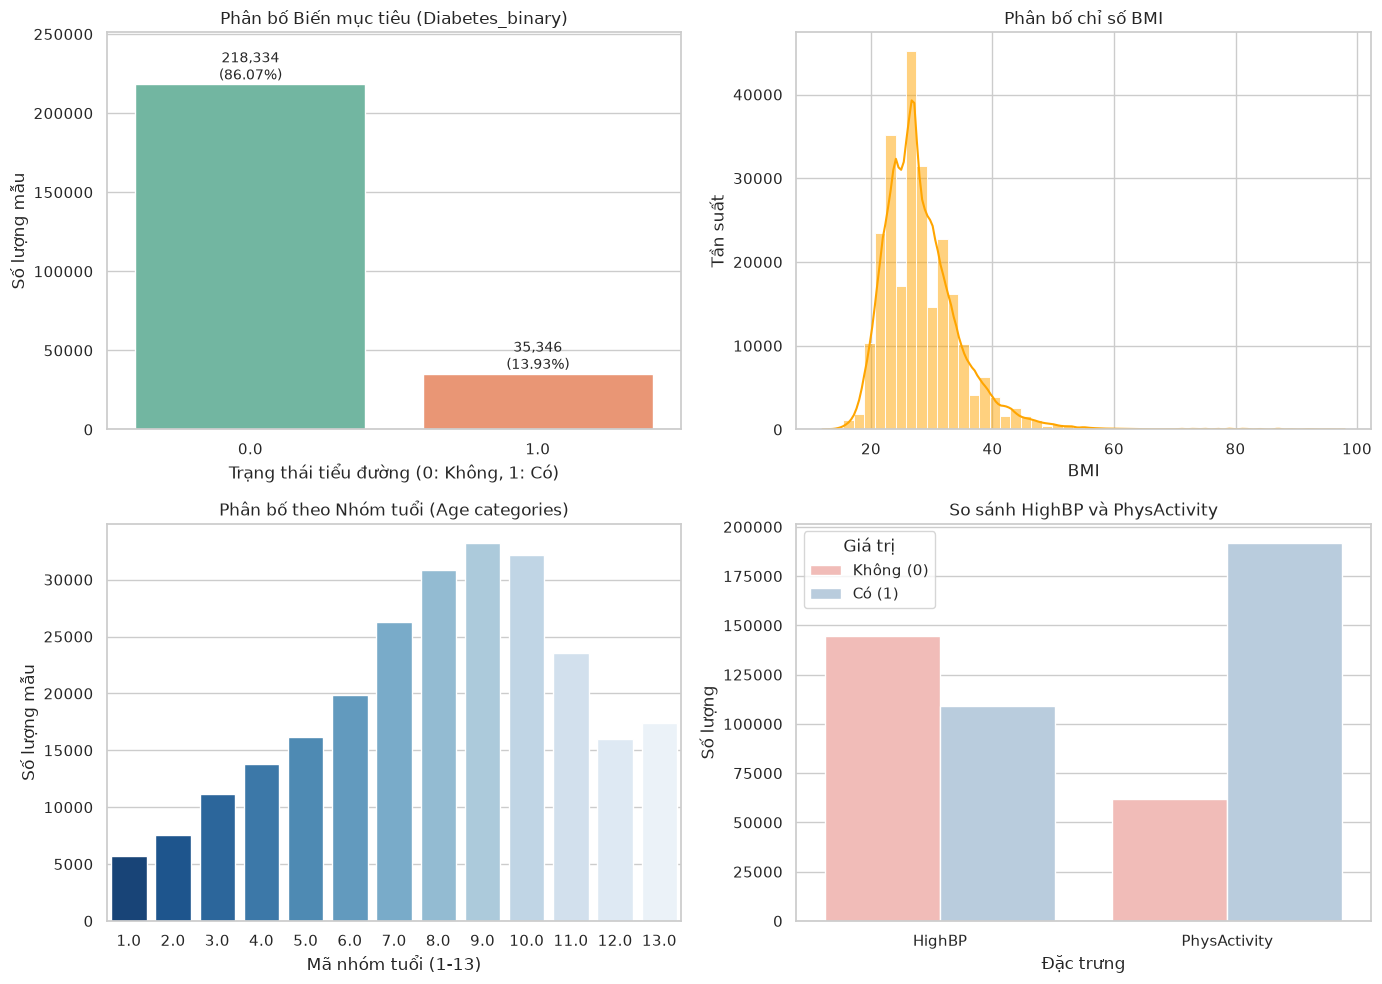

-> Đã lưu bảng: D:\CK\results\tables\1_2_target_distribution.csv
-> Đã lưu bảng: D:\CK\results\tables\1_2_bmi_summary.csv
-> Đã lưu bảng: D:\CK\results\tables\1_2_key_binary_features_distribution.csv


In [5]:
%matplotlib inline
# Thiết lập giao diện hiển thị đồ họa
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("=== 1. PHÂN BỐ BIẾN MỤC TIÊU (Diabetes_binary) ===")
target_counts = df['Diabetes_binary'].value_counts()
target_percent = df['Diabetes_binary'].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({
    'Số lượng': target_counts,
    'Tỷ lệ (%)': target_percent
})
display(target_summary)

print("\n=== 2. THỐNG KÊ MÔ TẢ CHỈ SỐ BMI ===")
bmi_desc = df['BMI'].describe()
df_bmi_summary = pd.DataFrame({
    'Chỉ số thống kê': bmi_desc.index,
    'Giá trị BMI': bmi_desc.values
})
df_bmi_summary['Giá trị BMI'] = df_bmi_summary['Giá trị BMI'].round(2)
display(df_bmi_summary)

print("\n=== 3. PHÂN BỐ CÁC YẾU TỐ SỨC KHỎE QUAN TRỌNG (Tỷ lệ %) ===")
key_features = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'DiffWalk']
summary_features = []
for col in key_features:
    pct = df[col].value_counts(normalize=True) * 100
    summary_features.append({
        'Đặc trưng': col,
        'Tỷ lệ Không (0.0) (%)': pct.get(0.0, 0),
        'Tỷ lệ Có (1.0) (%)': pct.get(1.0, 0)
    })
display(pd.DataFrame(summary_features))

# --- VẼ BIỂU ĐỒ TRỰC QUAN HÓA PHÂN BỐ ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Biến mục tiêu
ax = axes[0, 0]

sns.countplot(
    x='Diabetes_binary',
    data=df,
    ax=ax,
    hue='Diabetes_binary',
    palette='Set2',
    legend=False
)

ax.set_title('Phân bố Biến mục tiêu (Diabetes_binary)')
ax.set_xlabel('Trạng thái tiểu đường (0: Không, 1: Có)')
ax.set_ylabel('Số lượng mẫu')

# Tính số lượng và tỷ lệ phần trăm
total = len(df)
counts = df['Diabetes_binary'].value_counts().sort_index()

# Hiển thị số lượng và % trên đầu mỗi cột
for bar in ax.patches:
    count = int(bar.get_height())
    percent = count / total * 100

    ax.annotate(
        f'{count:,}\n({percent:.2f}%)',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

ax.set_ylim(0, counts.max() * 1.15)

# 2. Phân bố BMI
sns.histplot(df['BMI'], bins=50, kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Phân bố chỉ số BMI')
axes[0, 1].set_xlabel('BMI')
axes[0, 1].set_ylabel('Tần suất')

# 3. Phân bố Nhóm tuổi (Age)
sns.countplot(x='Age', data=df, ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title('Phân bố theo Nhóm tuổi (Age categories)')
axes[1, 0].set_xlabel('Mã nhóm tuổi (1-13)')
axes[1, 0].set_ylabel('Số lượng mẫu')

# 4. Huyết áp cao (HighBP) và Hoạt động thể chất (PhysActivity)
# Tạo DataFrame phụ để vẽ gộp
melted_df = pd.melt(df[['HighBP', 'PhysActivity']], var_name='Feature', value_name='Value')
sns.countplot(x='Feature', hue='Value', data=melted_df, ax=axes[1, 1], palette='Pastel1')
axes[1, 1].set_title('So sánh HighBP và PhysActivity')
axes[1, 1].set_xlabel('Đặc trưng')
axes[1, 1].set_ylabel('Số lượng')
axes[1, 1].legend(title='Giá trị', labels=['Không (0)', 'Có (1)'])

plt.tight_layout()

# Lưu hình ảnh vào thư mục figures đã thiết lập ở bước trước
output_fig_path = FIGURES / "distribution_analysis.png"
plt.savefig(output_fig_path, dpi=300)
print(f"\n-> Đã lưu biểu đồ phân tích tại: {output_fig_path}")

plt.show()

# --- Lưu bảng kết quả vào results/tables ---
save_table(target_summary.rename_axis("Diabetes_binary").reset_index(), "1_2_target_distribution")
save_table(df_bmi_summary, "1_2_bmi_summary")
save_table(pd.DataFrame(summary_features), "1_2_key_binary_features_distribution")

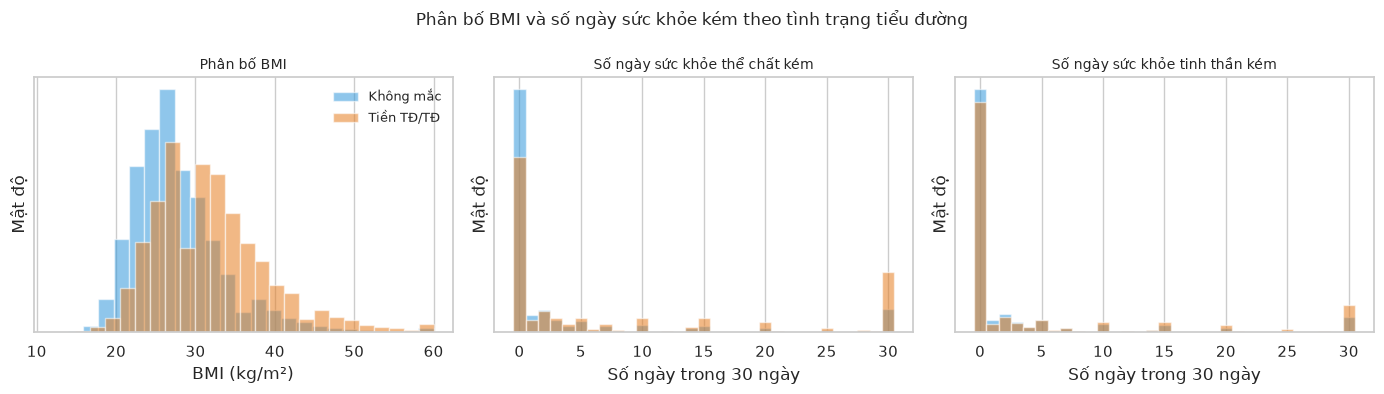

In [6]:
# Phân bố BMI và số ngày sức khỏe kém
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
BLUE = "#3498DB"    # Xanh dương
ORANGE = "#E67E22"  # Cam

variables = [
    ("BMI", "Phân bố BMI", 60),
    ("PhysHlth", "Số ngày sức khỏe thể chất kém", 30),
    ("MentHlth", "Số ngày sức khỏe tinh thần kém", 30)
]

TARGET = "Diabetes_binary"

for ax, (col, title, xmax) in zip(axs, variables):
    for value, color, label in [
        (0, BLUE, "Không mắc"),
        (1, ORANGE, "Tiền TĐ/TĐ")
    ]:
        data = df.loc[df[TARGET] == value, col].clip(upper=xmax)

        ax.hist(
            data,
            bins=25 if col == "BMI" else np.arange(-0.5, xmax + 1.5, 1),
            density=True,
            alpha=0.55,
            color=color,
            label=label
        )

    ax.set_title(title, fontsize=10)
    ax.set_xlabel(
        "BMI (kg/m²)" if col == "BMI"
        else "Số ngày trong 30 ngày"
    )
    ax.set_ylabel("Mật độ")
    ax.set_yticks([])

axs[0].legend(frameon=False, fontsize=9)
fig.suptitle(
    "Phân bố BMI và số ngày sức khỏe kém theo tình trạng tiểu đường",
    fontsize=12
)

fig.tight_layout()
fig.savefig(
    FIGURES / "fig2_bmi_health_days_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

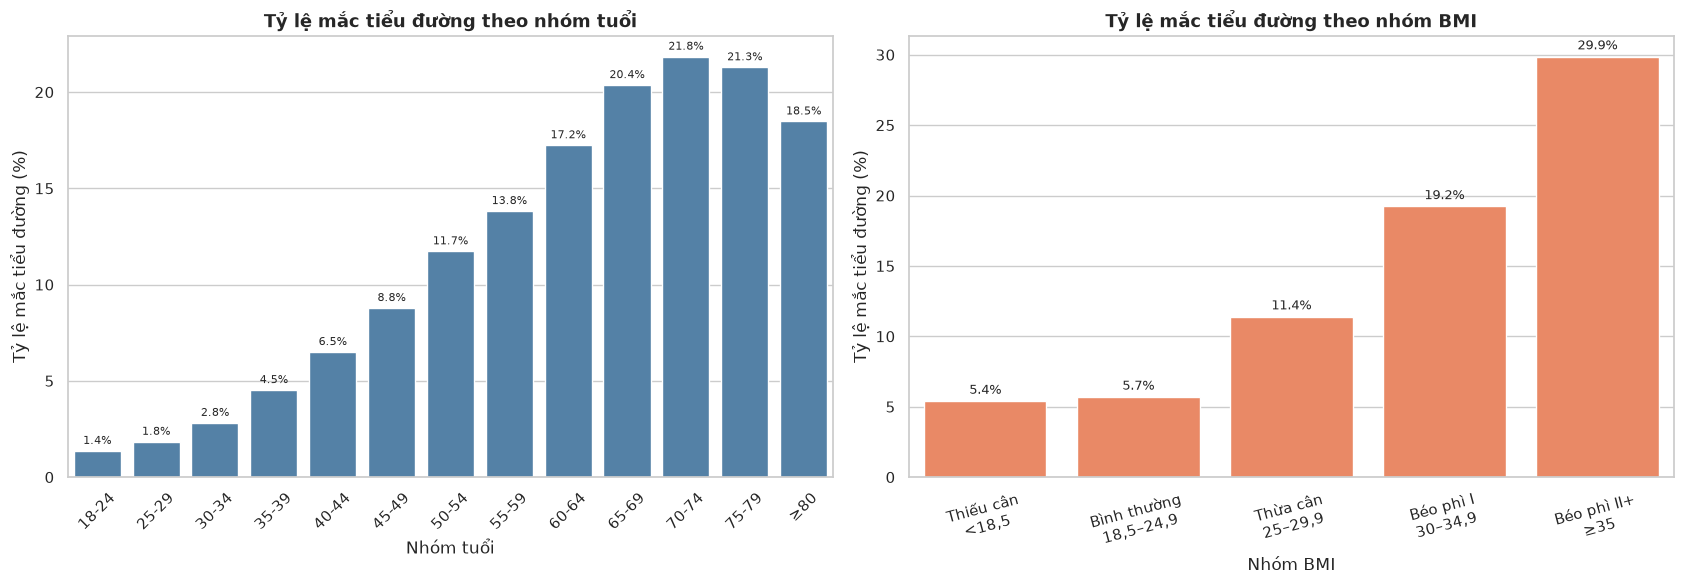

-> Đã lưu bảng: D:\CK\results\tables\1_2_rate_by_age_group.csv
-> Đã lưu bảng: D:\CK\results\tables\1_2_rate_by_bmi_group.csv


In [7]:
AGE_LBL = [
    "18-24", "25-29", "30-34", "35-39", "40-44",
    "45-49", "50-54", "55-59", "60-64", "65-69",
    "70-74", "75-79", "≥80"
]

# AGE trong bộ dữ liệu BRFSS thường được mã hóa từ 1 đến 13
df["AGE_group"] = pd.cut(
    df["Age"],
    bins=np.arange(0.5, 14.5, 1),
    labels=AGE_LBL
)

df["BMI_group"] = pd.cut(
    df["BMI"],
    bins=[0, 18.5, 25, 30, 35, 100],
    labels=[
        "Thiếu cân\n<18,5",
        "Bình thường\n18,5–24,9",
        "Thừa cân\n25–29,9",
        "Béo phì I\n30–34,9",
        "Béo phì II+\n≥35"
    ],
    right=False
)

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# Tính tỷ lệ mắc tiểu đường theo nhóm tuổi
age_rate = (
    df.groupby("AGE_group", observed=False)["Diabetes_binary"]
    .mean() * 100
)

# Tính tỷ lệ mắc tiểu đường theo nhóm BMI
bmi_rate = (
    df.groupby("BMI_group", observed=False)["Diabetes_binary"]
    .mean() * 100
)

# Tạo 2 biểu đồ cột
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Biểu đồ 1: Theo nhóm tuổi
sns.barplot(
    x=age_rate.index.astype(str),
    y=age_rate.values,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title(
    "Tỷ lệ mắc tiểu đường theo nhóm tuổi",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Nhóm tuổi")
axes[0].set_ylabel("Tỷ lệ mắc tiểu đường (%)")
axes[0].tick_params(axis="x", rotation=45)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", fontsize=8, padding=3)

# Biểu đồ 2: Theo nhóm BMI
sns.barplot(
    x=bmi_rate.index.astype(str),
    y=bmi_rate.values,
    ax=axes[1],
    color="coral"
)

axes[1].set_title(
    "Tỷ lệ mắc tiểu đường theo nhóm BMI",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Nhóm BMI")
axes[1].set_ylabel("Tỷ lệ mắc tiểu đường (%)")
axes[1].tick_params(axis="x", rotation=15)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", fontsize=9, padding=3)

plt.tight_layout()
plt.savefig(
    FIGURES / "diabetes_rate_by_age_bmi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --- Lưu bảng kết quả vào results/tables ---
save_table(age_rate.rename("Tỷ lệ mắc (%)").rename_axis("Nhóm tuổi").reset_index(), "1_2_rate_by_age_group")
save_table(
    bmi_rate.rename("Tỷ lệ mắc (%)").rename(index=lambda s: str(s).replace("\n", " ")).rename_axis("Nhóm BMI").reset_index(),
    "1_2_rate_by_bmi_group")

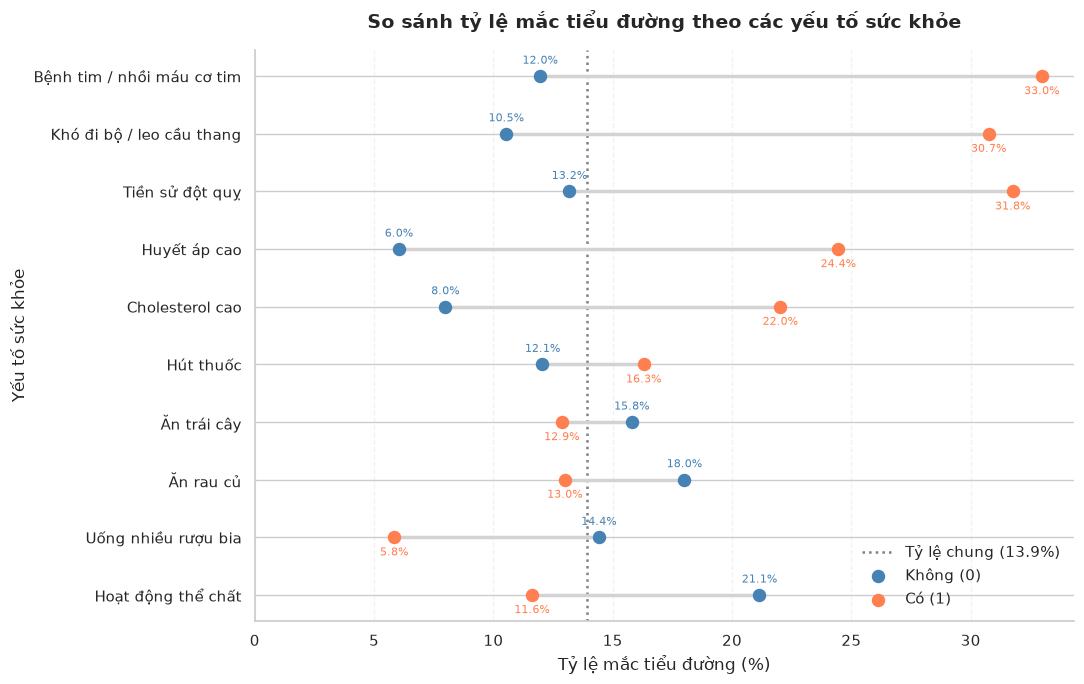

-> Đã lưu bảng: D:\CK\results\tables\1_2_binary_factor_rates.csv


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Các yếu tố sức khỏe nhị phân
binary_features = [
    "HeartDiseaseorAttack",
    "DiffWalk",
    "Stroke",
    "HighBP",
    "HighChol",
    "Smoker",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump"
]

# Chỉ giữ các cột có trong DataFrame
binary_features = [c for c in binary_features if c in df.columns]

# Tên hiển thị trên biểu đồ
feature_names = {
    "HeartDiseaseorAttack": "Bệnh tim / nhồi máu cơ tim",
    "DiffWalk": "Khó đi bộ / leo cầu thang",
    "Stroke": "Tiền sử đột quỵ",
    "HighBP": "Huyết áp cao",
    "HighChol": "Cholesterol cao",
    "Smoker": "Hút thuốc",
    "PhysActivity": "Hoạt động thể chất",
    "Fruits": "Ăn trái cây",
    "Veggies": "Ăn rau củ",
    "HvyAlcoholConsump": "Uống nhiều rượu bia"
}

# Tính tỷ lệ mắc (%) khi yếu tố = 0 và yếu tố = 1
results = []

for feature in binary_features:
    for value in [0, 1]:
        subset = df.loc[
            df[feature].eq(value),
            "Diabetes_binary"
        ].dropna()

        if len(subset) > 0:
            results.append({
                "Yếu tố": feature_names.get(feature, feature),
                "Trạng thái": value,
                "Tỷ lệ (%)": subset.mean() * 100
            })

rate_df = pd.DataFrame(results)

# Chuyển dữ liệu thành 2 cột Không (0) và Có (1)
pivot_df = rate_df.pivot(
    index="Yếu tố",
    columns="Trạng thái",
    values="Tỷ lệ (%)"
).dropna(subset=[0, 1])

# Sắp xếp theo mức chênh lệch tỷ lệ mắc
pivot_df["Chênh lệch"] = pivot_df[1] - pivot_df[0]
pivot_df = pivot_df.sort_values("Chênh lệch")

# Tỷ lệ mắc trung bình toàn bộ dữ liệu
overall_rate = df["Diabetes_binary"].mean() * 100

# Vẽ biểu đồ dumbbell ngang
fig, ax = plt.subplots(figsize=(11, 7))

y = np.arange(len(pivot_df))

# Đường chấm dọc: tỷ lệ mắc trung bình toàn bộ dữ liệu
ax.axvline(
    overall_rate,
    color="gray",
    linestyle=":",
    linewidth=1.8,
    label=f"Tỷ lệ chung ({overall_rate:.1f}%)",
    zorder=1
)

# Đường nối giữa hai nhóm
for i, (_, row) in enumerate(pivot_df.iterrows()):
    ax.plot(
        [row[0], row[1]],
        [i, i],
        color="lightgray",
        linewidth=2.5,
        zorder=2
    )

# Hai nhóm dữ liệu
ax.scatter(
    pivot_df[0], y,
    color="steelblue",
    s=75,
    label="Không (0)",
    zorder=3
)

ax.scatter(
    pivot_df[1], y,
    color="coral",
    s=75,
    label="Có (1)",
    zorder=3
)

# Nhãn tỷ lệ bên cạnh từng điểm
for i, (_, row) in enumerate(pivot_df.iterrows()):
    ax.annotate(
        f"{row[0]:.1f}%",
        (row[0], i),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="steelblue"
    )

    ax.annotate(
        f"{row[1]:.1f}%",
        (row[1], i),
        xytext=(0, -13),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="coral"
    )

ax.set_yticks(y)
ax.set_yticklabels(pivot_df.index)
ax.set_xlabel("Tỷ lệ mắc tiểu đường (%)")
ax.set_ylabel("Yếu tố sức khỏe")

ax.set_title(
    "So sánh tỷ lệ mắc tiểu đường theo các yếu tố sức khỏe",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlim(left=0)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="lower right",
    frameon=False
)

plt.tight_layout()

plt.savefig(
    FIGURES / "diabetes_dumbbell_binary_factors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --- Lưu bảng kết quả vào results/tables ---
save_table(
    pivot_df.rename(columns={0: "Tỷ lệ mắc khi = 0 (%)", 1: "Tỷ lệ mắc khi = 1 (%)"}).rename_axis(columns=None).reset_index(),
    "1_2_binary_factor_rates")

### 1.3 Trực quan hóa & liên hệ thống kê với biến mục tiêu 

                Biến Hệ số liên hệ   Phương pháp    p-value
                 BMI        0.3766 Rank-biserial  0.000e+00
             GenHlth        0.2993    Cramér's V  0.000e+00
              HighBP        0.2631    Cramér's V  0.000e+00
            PhysHlth        0.2260 Rank-biserial  0.000e+00
            DiffWalk        0.2183    Cramér's V  0.000e+00
            HighChol        0.2003    Cramér's V  0.000e+00
                 Age        0.1862    Cramér's V  0.000e+00
HeartDiseaseorAttack        0.1773    Cramér's V  0.000e+00
              Income        0.1662    Cramér's V  0.000e+00
           Education        0.1260    Cramér's V  0.000e+00
        PhysActivity        0.1181    Cramér's V  0.000e+00
              Stroke        0.1058    Cramér's V  0.000e+00
           CholCheck        0.0648    Cramér's V 2.290e-233
              Smoker        0.0608    Cramér's V 7.240e-206
   HvyAlcoholConsump        0.0571    Cramér's V 1.304e-181
             Veggies        0.0566    Cr

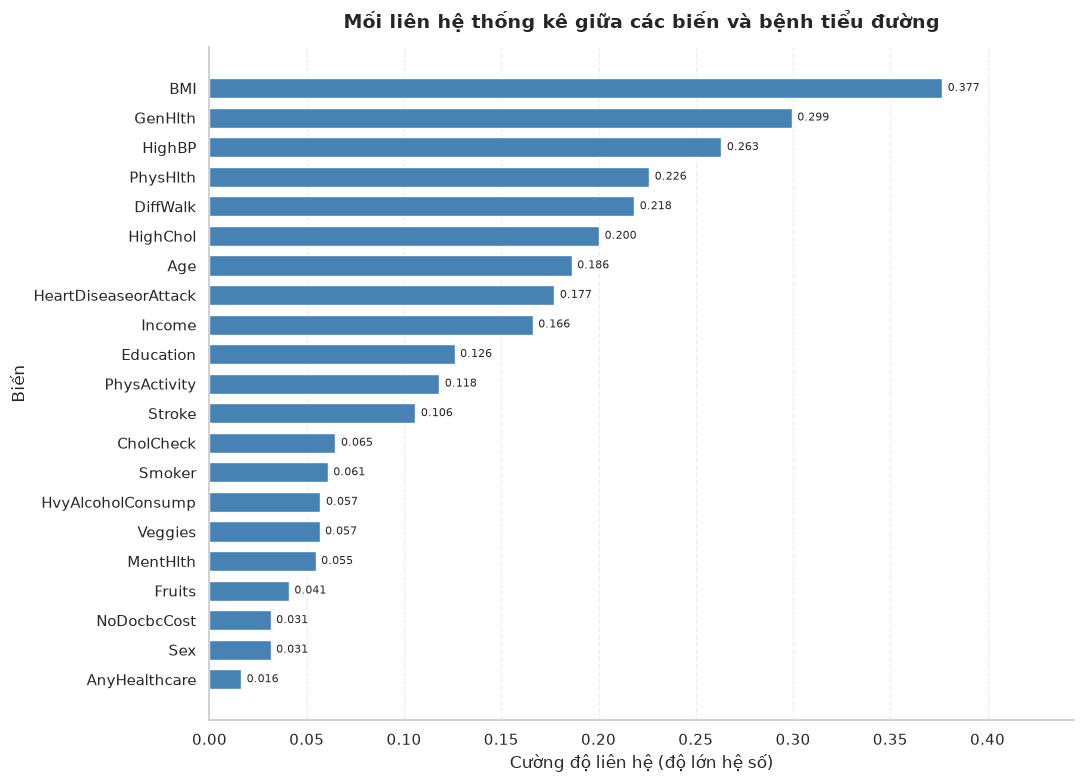

-> Đã lưu bảng: D:\CK\results\tables\1_3_association_with_target.csv


In [9]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

target = "Diabetes_binary"

# Các biến phân loại nhị phân và thứ bậc
categorical_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk",
    "Sex", "Age", "GenHlth", "Education", "Income"
]

# Các biến số dùng Mann–Whitney và rank-biserial
numeric_features = ["BMI", "MentHlth", "PhysHlth"]

categorical_features = [
    c for c in categorical_features
    if c in df.columns and c != target
]

numeric_features = [
    c for c in numeric_features
    if c in df.columns and c != target
]

results = []

# 1. Cramér's V cho biến phân loại
for feature in categorical_features:
    data = df[[feature, target]].dropna()

    if data[feature].nunique() < 2 or data[target].nunique() < 2:
        continue

    table = pd.crosstab(data[feature], data[target])

    if min(table.shape) < 2:
        continue

    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()

    cramers_v = np.sqrt(
        chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1))
    )

    results.append({
        "Biến": feature,
        "Hệ số liên hệ": cramers_v,
        "Phương pháp": "Cramér's V",
        "p-value": p_value
    })

# 2. Rank-biserial correlation cho biến số
for feature in numeric_features:
    data = df[[feature, target]].dropna()

    group0 = data.loc[data[target] == 0, feature]
    group1 = data.loc[data[target] == 1, feature]

    if len(group0) == 0 or len(group1) == 0:
        continue

    # Mann–Whitney U: nhóm mắc bệnh so với nhóm không mắc
    u_stat, p_value = mannwhitneyu(
        group1, group0,
        alternative="two-sided"
    )

    # Hệ số rank-biserial có dấu
    r_rb = 2 * u_stat / (len(group1) * len(group0)) - 1

    results.append({
        "Biến": feature,
        "Hệ số liên hệ": abs(r_rb),
        "Phương pháp": "Rank-biserial",
        "p-value": p_value
    })

# 3. Tổng hợp và xếp hạng theo cường độ liên hệ
result_df = pd.DataFrame(results)

result_df = result_df.sort_values(
    "Hệ số liên hệ",
    ascending=True
).reset_index(drop=True)

print(
    result_df.sort_values("Hệ số liên hệ", ascending=False)
    .to_string(index=False, formatters={
        "Hệ số liên hệ": "{:.4f}".format,
        "p-value": "{:.3e}".format
    })
)

# 4. Vẽ biểu đồ thanh ngang
fig, ax = plt.subplots(
    figsize=(11, max(6, len(result_df) * 0.38))
)

bars = ax.barh(
    result_df["Biến"],
    result_df["Hệ số liên hệ"],
    color="steelblue",
    height=0.68
)

# Hiển thị hệ số cuối mỗi thanh
ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4,
    fontsize=8
)

ax.set_title(
    "Mối liên hệ thống kê giữa các biến và bệnh tiểu đường",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Cường độ liên hệ (độ lớn hệ số)")
ax.set_ylabel("Biến")

ax.set_xlim(
    0,
    max(0.1, result_df["Hệ số liên hệ"].max() * 1.18)
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES / "association_strength_diabetes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --- Lưu bảng kết quả vào results/tables ---
save_table(result_df.sort_values("Hệ số liên hệ", ascending=False), "1_3_association_with_target")

### 1.4 Xử lý dữ liệu trùng lặp và mất cân bằng lớp

#### 1.4.1 Phân tích nguyên nhân dữ liệu trùng lặp

Theo hướng dẫn của cô, bản ghi trùng lặp **không được mặc nhiên coi là bản ghi sai**, vì những người trả lời khác nhau có thể có cùng câu trả lời khảo sát (21 đặc trưng, hầu hết là biến nhị phân hoặc thứ bậc có rất ít giá trị). Vì vậy cần kiểm tra hai giả thuyết:

- **H1 – Lỗi nhập liệu hoặc sao chép:** bản sao xuất hiện ngẫu nhiên ở mọi loại hồ sơ, và tỷ lệ lớp 1 trong các bản sao xấp xỉ tỷ lệ chung (13,93%).
- **H2 – Trùng hợp tự nhiên:** bản sao tập trung ở các hồ sơ đơn giản, phổ biến (ít yếu tố nguy cơ), và tỷ lệ lớp 1 trong các bản sao thấp.

Quy ước: *bản sao* là bản ghi trùng hoàn toàn (21 đặc trưng và nhãn) với một bản ghi xuất hiện trước đó; *hồ sơ* là một tổ hợp 21 đặc trưng, có thể gồm nhiều người trả lời.

In [10]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

TARGET = "Diabetes_binary"
# 21 đặc trưng cố định (không lấy theo df.columns vì df còn các cột phụ như AGE_group, profile_id, is_copy)
FEATURES = list(FEATURES_21)
SEED = 42

# 1. Bản ghi trùng lặp hoàn toàn (cả 21 đặc trưng và nhãn); giữ lại bản đầu tiên, các bản sau là "bản sao"
dup_mask = df.duplicated(subset=FEATURES + [TARGET], keep="first")
n_total, n_dup = len(df), int(dup_mask.sum())
dup_pos = int(df.loc[dup_mask, TARGET].sum())

# 2. "Hồ sơ" = tổ hợp 21 đặc trưng (không xét nhãn). Một hồ sơ có thể gồm nhiều người trả lời khác nhau
df["profile_id"] = df.groupby(FEATURES, sort=False).ngroup()
df["profile_size"] = df.groupby("profile_id")["profile_id"].transform("size")
profile_sizes = df.groupby("profile_id").size()

# 3. Hồ sơ có cùng đặc trưng nhưng khác nhãn (xung đột nhãn)
label_conflict = df.groupby("profile_id")[TARGET].nunique()
conflict_profiles = int((label_conflict > 1).sum())
conflict_rows = int(df["profile_id"].isin(label_conflict[label_conflict > 1].index).sum())

dup_summary = pd.DataFrame({
    "Chỉ số": [
        "Tổng số bản ghi",
        "Số bản sao trùng lặp hoàn toàn (đặc trưng + nhãn)",
        "Tỷ lệ bản sao (%)",
        "  trong đó thuộc lớp 0 (không mắc)",
        "  trong đó thuộc lớp 1 (tiền TĐ / TĐ)",
        "Tỷ lệ lớp 1 trong các bản sao (%)",
        "Tỷ lệ lớp 1 trong toàn bộ dữ liệu (%)",
        "Số hồ sơ đặc trưng khác nhau",
        "Số hồ sơ xuất hiện từ 2 lần trở lên",
        "Kích thước hồ sơ lớn nhất (số bản ghi)",
        "Số hồ sơ xung đột nhãn (cùng đặc trưng, khác nhãn)",
        "Số bản ghi thuộc các hồ sơ xung đột nhãn",
    ],
    "Giá trị": pd.Series([
        n_total, n_dup, round(100 * n_dup / n_total, 2), n_dup - dup_pos, dup_pos,
        round(100 * dup_pos / n_dup, 2), round(100 * df[TARGET].mean(), 2),
        int(profile_sizes.size), int((profile_sizes > 1).sum()), int(profile_sizes.max()),
        conflict_profiles, conflict_rows,
    ], dtype=object),
})
display(dup_summary)
save_table(dup_summary, "1_4_duplicate_summary")

,Chỉ số,Giá trị
0,Tổng số bản ghi,253680
1,Số bản sao trùng lặp hoàn toàn (đặc trưng + nhãn),24206
2,Tỷ lệ bản sao (%),9.54
3,trong đó thuộc lớp 0 (không mắc),23957
4,trong đó thuộc lớp 1 (tiền TĐ / TĐ),249
5,Tỷ lệ lớp 1 trong các bản sao (%),1.03
6,Tỷ lệ lớp 1 trong toàn bộ dữ liệu (%),13.93
7,Số hồ sơ đặc trưng khác nhau,227908
8,Số hồ sơ xuất hiện từ 2 lần trở lên,12228
9,Kích thước hồ sơ lớn nhất (số bản ghi),59


-> Đã lưu bảng: D:\CK\results\tables\1_4_duplicate_summary.csv


,Số yếu tố nguy cơ (0–7),Số người,Số bản sao,Tỷ lệ lớp 1 (%),Tỷ lệ bản sao (%)
0,0,67007,14405,1.98,21.50
1,1,66263,6335,6.15,9.56
2,2,53609,2713,14.22,5.06
3,3,34477,705,25.42,2.04
4,4,18587,41,36.10,0.22
5,5,9561,7,46.89,0.07
6,6,3515,0,54.51,0.00
7,7,661,0,67.47,0.00


-> Đã lưu bảng: D:\CK\results\tables\1_4_duplicate_rate_by_risk_factors.csv


,so_ban_ghi,so_lop_1,Age,BMI,HighBP,HighChol,GenHlth,PhysActivity,Income
0,59,0,6,21,0,0,1,1,8
1,55,0,6,23,0,0,1,1,8
2,53,0,7,23,0,0,1,1,8
3,52,0,6,22,0,0,1,1,8
4,52,0,5,21,0,0,1,1,8
5,51,0,8,22,0,0,1,1,8
6,50,0,8,23,0,0,1,1,8
7,47,0,7,21,0,0,1,1,8
8,44,0,4,21,0,0,1,1,8
9,44,1,7,24,0,0,1,1,8


-> Đã lưu bảng: D:\CK\results\tables\1_4_top10_repeated_profiles.csv
-> Đã lưu biểu đồ: D:\CK\results\figures\duplicate_analysis.png


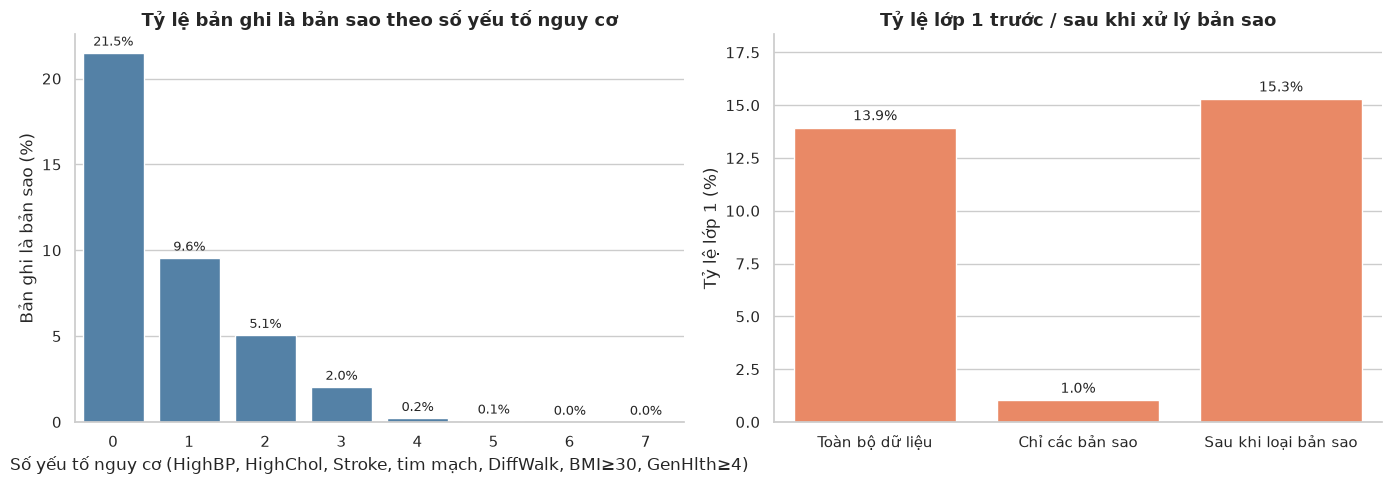

In [11]:
# Bản sao trùng lặp tập trung ở nhóm nào? Dùng "số yếu tố nguy cơ" để mô tả mức độ phức tạp của hồ sơ
risk_flags = pd.DataFrame({
    "HighBP": df["HighBP"] == 1,
    "HighChol": df["HighChol"] == 1,
    "Stroke": df["Stroke"] == 1,
    "HeartDiseaseorAttack": df["HeartDiseaseorAttack"] == 1,
    "DiffWalk": df["DiffWalk"] == 1,
    "BMI>=30": df["BMI"] >= 30,
    "GenHlth>=4": df["GenHlth"] >= 4,
})
df["n_risk"] = risk_flags.sum(axis=1).astype(int)
df["is_copy"] = dup_mask

risk_dup = (
    df.groupby("n_risk")
    .agg(so_nguoi=(TARGET, "size"), so_ban_sao=("is_copy", "sum"), ty_le_duong_tinh=(TARGET, "mean"))
    .reset_index()
)
risk_dup["ty_le_ban_sao"] = 100 * risk_dup["so_ban_sao"] / risk_dup["so_nguoi"]
risk_dup["ty_le_duong_tinh"] = 100 * risk_dup["ty_le_duong_tinh"]
risk_dup = risk_dup.rename(columns={
    "n_risk": "Số yếu tố nguy cơ (0–7)", "so_nguoi": "Số người", "so_ban_sao": "Số bản sao",
    "ty_le_ban_sao": "Tỷ lệ bản sao (%)", "ty_le_duong_tinh": "Tỷ lệ lớp 1 (%)",
}).round(2)
display(risk_dup)
save_table(risk_dup, "1_4_duplicate_rate_by_risk_factors")

# So sánh nhóm bản sao với toàn bộ dữ liệu
prev_all = 100 * df[TARGET].mean()
prev_copies = 100 * df.loc[dup_mask, TARGET].mean()
prev_after = 100 * df.loc[~dup_mask, TARGET].mean()

# 10 hồ sơ lặp nhiều nhất
top_profiles = (
    df[df["profile_size"] > 1]
    .groupby("profile_id")
    .agg(so_ban_ghi=(TARGET, "size"), so_lop_1=(TARGET, "sum"), Age=("Age", "first"), BMI=("BMI", "first"),
         HighBP=("HighBP", "first"), HighChol=("HighChol", "first"), GenHlth=("GenHlth", "first"),
         PhysActivity=("PhysActivity", "first"), Income=("Income", "first"))
    .nlargest(10, "so_ban_ghi")
    .reset_index(drop=True)
    .astype(int)
)
display(top_profiles)
save_table(top_profiles, "1_4_top10_repeated_profiles")

# Biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=risk_dup, x="Số yếu tố nguy cơ (0–7)", y="Tỷ lệ bản sao (%)", color="steelblue", ax=axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f%%", fontsize=9, padding=3)
axes[0].set_title("Tỷ lệ bản ghi là bản sao theo số yếu tố nguy cơ", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Số yếu tố nguy cơ (HighBP, HighChol, Stroke, tim mạch, DiffWalk, BMI≥30, GenHlth≥4)")
axes[0].set_ylabel("Bản ghi là bản sao (%)")

comp = pd.DataFrame({
    "Nhóm dữ liệu": ["Toàn bộ dữ liệu", "Chỉ các bản sao", "Sau khi loại bản sao"],
    "Tỷ lệ lớp 1 (%)": [prev_all, prev_copies, prev_after],
})
sns.barplot(data=comp, x="Nhóm dữ liệu", y="Tỷ lệ lớp 1 (%)", color="coral", ax=axes[1])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f%%", fontsize=10, padding=3)
axes[1].set_title("Tỷ lệ lớp 1 trước / sau khi xử lý bản sao", fontsize=13, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Tỷ lệ lớp 1 (%)")
axes[1].set_ylim(0, max(comp["Tỷ lệ lớp 1 (%)"]) * 1.2)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURES / "duplicate_analysis.png", dpi=300, bbox_inches="tight")
print(f"-> Đã lưu biểu đồ: {FIGURES / 'duplicate_analysis.png'}")
plt.show()

**Nhận xét 1.4.1**

- Có 24.206 bản sao (9,54%); 12.228 hồ sơ xuất hiện từ 2 lần trở lên, hồ sơ lặp nhiều nhất có 59 bản ghi.
- Bản sao gần như toàn bộ thuộc lớp 0: chỉ 249 trong 24.206 bản sao (1,03%) thuộc lớp 1, trong khi tỷ lệ chung là 13,93%. Nếu là lỗi sao chép ngẫu nhiên thì tỷ lệ này phải xấp xỉ 13,93%.
- Tỷ lệ bản sao giảm mạnh theo số yếu tố nguy cơ: 21,5% ở nhóm không có yếu tố nguy cơ, 5,06% ở nhóm có 2 yếu tố, 0,22% ở nhóm có 4 yếu tố và gần như bằng 0 từ 5 yếu tố trở lên. Các hồ sơ lặp nhiều nhất đều là người khỏe mạnh (GenHlth = 1, không huyết áp hay cholesterol cao, có vận động, thu nhập cao nhất, BMI 21–23).
- **Kết luận:** số liệu ủng hộ H2. Bản sao chủ yếu do nhiều người khỏe mạnh có cùng hồ sơ trả lời, không phải lỗi nhập liệu. Dữ liệu không có mã người trả lời nên đây là kết luận từ bằng chứng gián tiếp, không phải chứng minh tuyệt đối.
- Ngoài ra có 1.566 hồ sơ (5.218 bản ghi) cùng đặc trưng nhưng khác nhãn. Đây là nhiễu nhãn tự nhiên của dữ liệu khảo sát và là giới hạn về hiệu năng tối đa của mọi mô hình.

#### 1.4.2 Phương án xử lý dữ liệu trùng lặp

So sánh ba phương án: (1) loại bỏ bản sao; (2) giữ nguyên và chia ngẫu nhiên; (3) giữ nguyên và chia theo hồ sơ, tức mọi bản ghi cùng hồ sơ nằm trong cùng một tập (thực hiện ở mục 1.5). Cột "Mẫu test có cùng hồ sơ với train" đo mức rò rỉ giữa hai tập.

In [12]:
from sklearn.model_selection import train_test_split

# So sánh hai cách xử lý bản sao nếu chia dữ liệu ngẫu nhiên (stratified) 85/15 để đo mức "trùng hồ sơ" giữa train và test
def profile_overlap(frame, seed=SEED):
    tr, te = train_test_split(frame, test_size=0.15, stratify=frame[TARGET], random_state=seed)
    return 100 * te["profile_id"].isin(set(tr["profile_id"])).mean()

df_keep = df                      # phương án giữ nguyên
df_drop = df.loc[~dup_mask]       # phương án loại bản sao

dup_options = pd.DataFrame({
    "Phương án": ["Loại bỏ bản sao", "Giữ nguyên + chia ngẫu nhiên", "Giữ nguyên + chia theo hồ sơ (đề xuất)"],
    "Số bản ghi": [len(df_drop), len(df_keep), len(df_keep)],
    "Tỷ lệ lớp 1 (%)": [round(100 * df_drop[TARGET].mean(), 2), round(100 * df_keep[TARGET].mean(), 2),
                        round(100 * df_keep[TARGET].mean(), 2)],
    "Mẫu test có cùng hồ sơ với train (%)": [round(profile_overlap(df_drop), 2), round(profile_overlap(df_keep), 2), 0.0],
    "Nhận xét": [
        "Làm lệch phân bố tổng thể (tỷ lệ lớp 1 tăng) và bỏ bớt người trả lời hợp lệ",
        "Giữ đúng phân bố nhưng test chứa hồ sơ đã thấy trong train, đánh giá dễ lạc quan",
        "Giữ đúng phân bố và test không chứa hồ sơ đã thấy trong train",
    ],
})
display(dup_options)
save_table(dup_options, "1_4_duplicate_handling_options")

,Phương án,Số bản ghi,Tỷ lệ lớp 1 (%),Mẫu test có cùng hồ sơ với train (%),Nhận xét
0,Loại bỏ bản sao,229474,15.29,1.16,Làm lệch phân bố tổng thể (tỷ lệ lớp 1 tăng) v...
1,Giữ nguyên + chia ngẫu nhiên,253680,13.93,13.89,Giữ đúng phân bố nhưng test chứa hồ sơ đã thấy...
2,Giữ nguyên + chia theo hồ sơ (đề xuất),253680,13.93,0.00,Giữ đúng phân bố và test không chứa hồ sơ đã t...


-> Đã lưu bảng: D:\CK\results\tables\1_4_duplicate_handling_options.csv


**Quyết định: không loại bỏ bản sao, chia dữ liệu theo hồ sơ.**

1. Bản sao nhiều khả năng là người trả lời hợp lệ (H2). Loại bỏ sẽ mất 10,97% mẫu lớp 0 (23.957 trong 218.334) và làm lệch phân bố: tỷ lệ lớp 1 tăng từ 13,93% lên 15,29%. Với hệ thống hiển thị xác suất nguy cơ, độ lệch nền này làm xác suất dự đoán cao hơn thực tế khoảng 10% (tương đối).
2. Rủi ro thật sự của bản sao là rò rỉ giữa train và test: nếu chia ngẫu nhiên, 13,89% mẫu test có hồ sơ giống hệt trong train, đặc biệt có lợi cho các mô hình dễ ghi nhớ như Random Forest, XGBoost. Rủi ro này được xử lý bằng cách chia theo hồ sơ (mục 1.5) mà không cần xóa dữ liệu.
3. **Hạn chế:** đánh giá trên test khắt khe hơn vì chỉ gồm hồ sơ chưa từng xuất hiện ở train; và do không có mã người trả lời nên kết luận dựa trên bằng chứng gián tiếp. Ở Giai đoạn 2 có thể huấn luyện thêm một phiên bản đã loại bản sao để kiểm tra độ nhạy của kết quả.

#### 1.4.3 Xử lý mất cân bằng lớp

Lớp 1 chỉ chiếm 13,93% (tỷ lệ lớp 0 : lớp 1 là 6,18 : 1). Mô hình luôn dự đoán lớp 0 đã đạt accuracy 86,07% nhưng bỏ sót toàn bộ ca lớp 1, vì vậy **không dùng accuracy** làm thước đo chính. Theo hướng dẫn của cô, cần đặc biệt chú ý Recall của lớp 1 và số trường hợp bỏ sót.

In [13]:
# Phân tích mất cân bằng lớp (dữ liệu giữ nguyên)
class_counts = df[TARGET].value_counts().sort_index()
n0, n1 = int(class_counts[0]), int(class_counts[1])

imbalance_summary = pd.DataFrame({
    "Chỉ số": ["Số mẫu lớp 0 (không mắc)", "Số mẫu lớp 1 (tiền TĐ / TĐ)", "Tỷ lệ lớp 1 (%)",
               "Tỷ lệ lớp 0 : lớp 1", "Accuracy nếu luôn dự đoán lớp 0 (%)", "Recall lớp 1 nếu luôn dự đoán lớp 0 (%)"],
    "Giá trị": pd.Series([n0, n1, round(100 * n1 / (n0 + n1), 2), f"{n0 / n1:.2f} : 1",
                          round(100 * n0 / (n0 + n1), 2), 0.0], dtype=object),
})
display(imbalance_summary)
save_table(imbalance_summary, "1_4_imbalance_summary")

# Đề xuất phương án xử lý mất cân bằng lớp (áp dụng khi huấn luyện ở Giai đoạn 2)
imbalance_options = pd.DataFrame({
    "Phương án": [
        "Giữ nguyên phân bố ở validation và test",
        "Dùng thước đo phù hợp",
        "Điều chỉnh ngưỡng phân loại",
        "class_weight = 'balanced'",
        "SMOTENC chỉ trên tập huấn luyện",
        "Giảm mẫu lớp đa số",
    ],
    "Mô tả": [
        "Không lấy mẫu lại validation và test để đánh giá phản ánh phân bố thực tế",
        "Recall lớp 1, Precision, F1, PR-AUC, ROC-AUC và Confusion Matrix; không dùng Accuracy",
        "Chọn ngưỡng trên validation theo mục tiêu (ví dụ Recall tối thiểu), không mặc định 0,5",
        "Tăng trọng số lớp 1 trong hàm mất mát, không thay đổi dữ liệu",
        "Sinh mẫu tổng hợp lớp 1 cho biến rời rạc; chỉ fit trên train (trong từng fold nếu dùng CV)",
        "Bỏ bớt mẫu lớp 0 trên tập huấn luyện; mất thông tin",
    ],
    "Quyết định": [
        "Bắt buộc", "Bắt buộc", "Áp dụng", "Thử nghiệm và so sánh", "Thử nghiệm và so sánh", "Chưa ưu tiên",
    ],
})
display(imbalance_options)
save_table(imbalance_options, "1_4_imbalance_options")

,Chỉ số,Giá trị
0,Số mẫu lớp 0 (không mắc),218334
1,Số mẫu lớp 1 (tiền TĐ / TĐ),35346
2,Tỷ lệ lớp 1 (%),13.93
3,Tỷ lệ lớp 0 : lớp 1,6.18 : 1
4,Accuracy nếu luôn dự đoán lớp 0 (%),86.07
5,Recall lớp 1 nếu luôn dự đoán lớp 0 (%),0.0


-> Đã lưu bảng: D:\CK\results\tables\1_4_imbalance_summary.csv


,Phương án,Mô tả,Quyết định
0,Giữ nguyên phân bố ở validation và test,Không lấy mẫu lại validation và test để đánh g...,Bắt buộc
1,Dùng thước đo phù hợp,"Recall lớp 1, Precision, F1, PR-AUC, ROC-AUC v...",Bắt buộc
2,Điều chỉnh ngưỡng phân loại,Chọn ngưỡng trên validation theo mục tiêu (ví ...,Áp dụng
3,class_weight = 'balanced',"Tăng trọng số lớp 1 trong hàm mất mát, không t...",Thử nghiệm và so sánh
4,SMOTENC chỉ trên tập huấn luyện,Sinh mẫu tổng hợp lớp 1 cho biến rời rạc; chỉ ...,Thử nghiệm và so sánh
5,Giảm mẫu lớp đa số,Bỏ bớt mẫu lớp 0 trên tập huấn luyện; mất thôn...,Chưa ưu tiên


-> Đã lưu bảng: D:\CK\results\tables\1_4_imbalance_options.csv


**Đề xuất và lý do**

1. Không lấy mẫu lại validation và test, để việc đánh giá phản ánh đúng phân bố thực tế.
2. Mọi kỹ thuật cân bằng lớp chỉ áp dụng cho tập huấn luyện, sau khi đã chia dữ liệu (nếu dùng cross-validation thì áp dụng trong từng fold huấn luyện). Tuyệt đối không áp dụng trước khi chia vì sẽ làm rò rỉ mẫu tổng hợp sang validation và test.
3. Ở Giai đoạn 2, so sánh ba hướng trên cùng một mô hình cơ sở: (a) không cân bằng và chọn ngưỡng trên validation; (b) `class_weight='balanced'`; (c) SMOTENC trên tập huấn luyện. Vì dữ liệu gồm cả đặc trưng rời rạc (nhị phân, thứ bậc) lẫn số (BMI, MentHlth, PhysHlth), dùng SMOTENC (khai báo cột rời rạc) thay vì SMOTEN thuần. Tuy nhiên mẫu tổng hợp không phải người thật, và các kỹ thuật cân bằng lớp thường làm xác suất dự đoán bị lệch lên. Vì hệ thống hiển thị xác suất và phân mức nguy cơ, nếu chọn SMOTENC thì cần hiệu chuẩn lại xác suất.
4. Chưa ưu tiên giảm mẫu lớp đa số vì bỏ khoảng 86% mẫu, mất nhiều thông tin.
5. Lựa chọn cuối cùng dựa trên Recall lớp 1, Precision, F1, PR-AUC và Confusion Matrix trên tập validation, không dựa trên accuracy.

### 1.5 Chia Train / Validation / Test (stratified)

- Tỷ lệ **70 / 15 / 15**, `random_state = 42`.
- **Stratified:** tỷ lệ lớp 1 gần như bằng nhau ở cả ba tập.
- **Chia theo hồ sơ:** mọi bản ghi có cùng 21 đặc trưng luôn nằm trong cùng một tập, nên không có hồ sơ giống hệt xuất hiện ở cả train và test (xem mục 1.4.2). Việc chia thực hiện ở mức hồ sơ, phân tầng theo loại nhãn của hồ sơ (chỉ lớp 0, chỉ lớp 1, xung đột nhãn) và kích thước hồ sơ.
- **Tập test độc lập:** chỉ dùng cho đánh giá cuối cùng, không dùng để chọn mô hình, ngưỡng hay siêu tham số.
- Mọi bước học từ dữ liệu (chuẩn hoá, cân bằng lớp, hiệu chuẩn xác suất) chỉ fit trên tập huấn luyện.

In [14]:
# Bảng dữ liệu dùng cho mô hình: 21 đặc trưng + nhãn, kiểu số nguyên
df_model = df[FEATURES + [TARGET]].astype(int).reset_index(drop=True)
# Kiểm tra: chỉ có 21 đặc trưng gốc và nhãn, không có cột phụ
assert list(df_model.columns) == FEATURES_21 + [TARGET]

# Chia ở mức "hồ sơ" (profile): mọi bản ghi có cùng 21 đặc trưng luôn nằm trong cùng một tập
profile = df.groupby("profile_id")[TARGET].agg(so_ban_ghi="size", so_lop_1="sum")

# Phân tầng theo loại nhãn của hồ sơ (chỉ lớp 0 / chỉ lớp 1 / xung đột) và kích thước hồ sơ (1, 2, 3, từ 4 trở lên)
label_type = np.where(profile["so_lop_1"] == 0, 0, np.where(profile["so_lop_1"] == profile["so_ban_ghi"], 1, 2))
profile["stratum"] = label_type * 10 + np.minimum(profile["so_ban_ghi"], 4)

ids = profile.index.to_numpy()
strata = profile["stratum"].to_numpy()

# 70% train, 15% validation, 15% test
train_ids, tmp_ids, _, tmp_strata = train_test_split(ids, strata, test_size=0.30, stratify=strata, random_state=SEED)
val_ids, test_ids = train_test_split(tmp_ids, test_size=0.50, stratify=tmp_strata, random_state=SEED)

split = np.where(df["profile_id"].isin(train_ids), "train", np.where(df["profile_id"].isin(val_ids), "validation", "test"))
splits = {name: df_model.loc[split == name].reset_index(drop=True) for name in ["train", "validation", "test"]}

split_summary = pd.DataFrame({
    "Tập": ["Huấn luyện", "Validation", "Test", "Tổng"],
    "Số bản ghi": [len(splits[k]) for k in ["train", "validation", "test"]] + [len(df_model)],
    "Số lớp 1": [int(splits[k][TARGET].sum()) for k in ["train", "validation", "test"]] + [int(df_model[TARGET].sum())],
})
split_summary["Tỷ lệ bản ghi (%)"] = (100 * split_summary["Số bản ghi"] / len(df_model)).round(2)
split_summary["Tỷ lệ lớp 1 (%)"] = (100 * split_summary["Số lớp 1"] / split_summary["Số bản ghi"]).round(2)
display(split_summary)
save_table(split_summary, "1_5_split_summary")

# Kiểm tra tính độc lập giữa các tập: không có hồ sơ đặc trưng nào xuất hiện ở hai tập
profiles = {"train": set(train_ids), "validation": set(val_ids), "test": set(test_ids)}
leakage_check = pd.DataFrame({
    "Cặp tập": ["Train và Validation", "Train và Test", "Validation và Test"],
    "Số hồ sơ đặc trưng trùng nhau": [len(profiles["train"] & profiles["validation"]),
                                      len(profiles["train"] & profiles["test"]),
                                      len(profiles["validation"] & profiles["test"])],
})
display(leakage_check)
save_table(leakage_check, "1_5_split_independence_check")

assert leakage_check["Số hồ sơ đặc trưng trùng nhau"].sum() == 0
assert split_summary.loc[:2, "Số bản ghi"].sum() == len(df_model)

# Lưu các tập dữ liệu để dùng ở Giai đoạn 2
for name, part in splits.items():
    part.to_csv(DATA / f"{name}.csv", index=False)
    print(f"-> Đã lưu tập {name}: {DATA / (name + '.csv')}  {part.shape}")

,Tập,Số bản ghi,Số lớp 1,Tỷ lệ bản ghi (%),Tỷ lệ lớp 1 (%)
0,Huấn luyện,177483,24747,69.96,13.94
1,Validation,38121,5296,15.03,13.89
2,Test,38076,5303,15.01,13.93
3,Tổng,253680,35346,100.00,13.93


-> Đã lưu bảng: D:\CK\results\tables\1_5_split_summary.csv


,Cặp tập,Số hồ sơ đặc trưng trùng nhau
0,Train và Validation,0
1,Train và Test,0
2,Validation và Test,0


-> Đã lưu bảng: D:\CK\results\tables\1_5_split_independence_check.csv
-> Đã lưu tập train: D:\CK\datas\train.csv  (177483, 22)
-> Đã lưu tập validation: D:\CK\datas\validation.csv  (38121, 22)
-> Đã lưu tập test: D:\CK\datas\test.csv  (38076, 22)


-> Đã lưu biểu đồ: D:\CK\results\figures\split_distribution.png


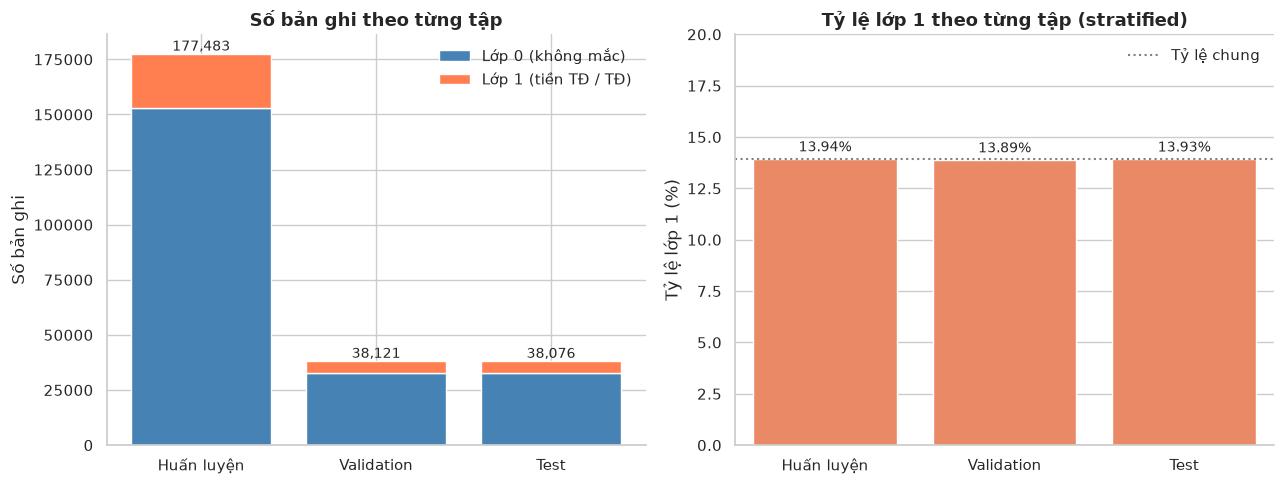

In [15]:
# Biểu đồ minh hoạ kết quả chia tập
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_df = split_summary.iloc[:3].copy()
plot_df["Lớp 0"] = plot_df["Số bản ghi"] - plot_df["Số lớp 1"]

axes[0].bar(plot_df["Tập"], plot_df["Lớp 0"], color="steelblue", label="Lớp 0 (không mắc)")
axes[0].bar(plot_df["Tập"], plot_df["Số lớp 1"], bottom=plot_df["Lớp 0"], color="coral", label="Lớp 1 (tiền TĐ / TĐ)")
for i, r in plot_df.reset_index(drop=True).iterrows():
    axes[0].text(i, r["Số bản ghi"] + 1500, f"{int(r['Số bản ghi']):,}", ha="center", fontsize=10)
axes[0].set_title("Số bản ghi theo từng tập", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Số bản ghi")
axes[0].legend(frameon=False)

sns.barplot(data=plot_df, x="Tập", y="Tỷ lệ lớp 1 (%)", color="coral", ax=axes[1])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.2f%%", fontsize=10, padding=3)
axes[1].axhline(100 * df_model[TARGET].mean(), color="gray", linestyle=":", linewidth=1.5, label="Tỷ lệ chung")
axes[1].set_title("Tỷ lệ lớp 1 theo từng tập (stratified)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Tỷ lệ lớp 1 (%)")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 20)
axes[1].legend(frameon=False)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURES / "split_distribution.png", dpi=300, bbox_inches="tight")
print(f"-> Đã lưu biểu đồ: {FIGURES / 'split_distribution.png'}")
plt.show()

### 1.6 Chuẩn hóa quy trình thực nghiệm (bổ sung theo góp ý của cô)

Cô thống nhất tạm giữ phương án chia theo hồ sơ và yêu cầu kiểm tra thêm bốn việc, thực hiện lần lượt ở các mục nhỏ sau:

- **1.6.1** Chỉ dùng đúng 21 đặc trưng đầu vào, không đưa nhãn hoặc biến trung gian tạo từ nhãn vào huấn luyện.
- **1.6.2** Lưu cố định danh sách bản ghi thuộc train, validation và test để các mô hình được so sánh công bằng.
- **1.6.3** Phân biệt hai kịch bản đánh giá: chia ngẫu nhiên theo bản ghi và chia theo hồ sơ đặc trưng.
- **1.6.4** Thí nghiệm đối chứng về ảnh hưởng của việc loại bản ghi trùng lặp trong tập huấn luyện.

Nguyên tắc: **tập test giữ độc lập cho đánh giá cuối cùng**. Mọi so sánh trong mục 1.6 chỉ dùng train và validation.

#### 1.6.1 Kiểm tra chỉ dùng 21 đặc trưng đầu vào

Trong lúc phân tích, notebook tạo thêm một số cột phụ trong `df` (`AGE_group`, `BMI_group`, `profile_id`, `profile_size`, `n_risk`, `is_copy`). Trong đó `is_copy` được tạo từ cả nhãn nên tuyệt đối không được dùng làm đầu vào. Bảng sau liệt kê vai trò từng cột và các câu `assert` bảo đảm dữ liệu đưa vào mô hình chỉ gồm 21 đặc trưng gốc.

In [16]:
# 1.6.1 Kiểm tra đặc trưng đầu vào
extra_cols = [c for c in df.columns if c != TARGET and c not in FEATURES_21]
origin = {
    "AGE_group": "Tạo từ Age (để vẽ biểu đồ)",
    "BMI_group": "Tạo từ BMI (để vẽ biểu đồ)",
    "profile_id": "Tạo từ 21 đặc trưng, không dùng nhãn (để chia theo hồ sơ)",
    "profile_size": "Tạo từ 21 đặc trưng, không dùng nhãn (kích thước hồ sơ)",
    "n_risk": "Tạo từ đặc trưng (phân tích bản sao)",
    "is_copy": "Tạo từ đặc trưng và NHÃN (đánh dấu bản sao hoàn toàn)",
}
feature_audit = pd.DataFrame({
    "Cột": [TARGET] + FEATURES_21 + extra_cols,
    "Vai trò": ["Nhãn (chỉ dùng làm y)"] + ["Đặc trưng đầu vào"] * 21 + ["Cột phụ, KHÔNG đưa vào mô hình"] * len(extra_cols),
    "Nguồn gốc": ["Dữ liệu gốc"] * 22 + [origin.get(c, "Cột phụ trong notebook") for c in extra_cols],
})
display(feature_audit)
save_table(feature_audit, "1_6_feature_audit")

# Các kiểm tra bắt buộc
assert len(FEATURES_21) == 21
assert TARGET not in FEATURES_21
assert not set(extra_cols) & set(FEATURES_21)
assert list(df_model.columns) == FEATURES_21 + [TARGET]
for name in ["train", "validation", "test"]:
    saved_cols = list(pd.read_csv(DATA / f"{name}.csv", nrows=1).columns)
    assert saved_cols == FEATURES_21 + [TARGET], f"{name}.csv có cột không hợp lệ: {saved_cols}"
print("-> Đạt: train/validation/test.csv chỉ gồm 21 đặc trưng gốc và nhãn; các cột phụ không được dùng làm đầu vào.")

,Cột,Vai trò,Nguồn gốc
0,Diabetes_binary,Nhãn (chỉ dùng làm y),Dữ liệu gốc
1,HighBP,Đặc trưng đầu vào,Dữ liệu gốc
2,HighChol,Đặc trưng đầu vào,Dữ liệu gốc
3,CholCheck,Đặc trưng đầu vào,Dữ liệu gốc
4,BMI,Đặc trưng đầu vào,Dữ liệu gốc
5,Smoker,Đặc trưng đầu vào,Dữ liệu gốc
6,Stroke,Đặc trưng đầu vào,Dữ liệu gốc
7,HeartDiseaseorAttack,Đặc trưng đầu vào,Dữ liệu gốc
8,PhysActivity,Đặc trưng đầu vào,Dữ liệu gốc
9,Fruits,Đặc trưng đầu vào,Dữ liệu gốc


-> Đã lưu bảng: D:\CK\results\tables\1_6_feature_audit.csv
-> Đạt: train/validation/test.csv chỉ gồm 21 đặc trưng gốc và nhãn; các cột phụ không được dùng làm đầu vào.


#### 1.6.2 Lưu cố định danh sách bản ghi thuộc từng tập

Mỗi kịch bản chia được lưu thành một file trong `datas/splits/`, gồm `row_id` (chỉ số dòng trong file dữ liệu gốc, bắt đầu từ 0), `profile_id` và `split`. File `manifest.json` ghi mã băm SHA-256 của file dữ liệu gốc, seed, kích thước từng tập; hàm `load_split` kiểm tra mã băm này để bảo đảm mọi mô hình ở Giai đoạn 2 dùng đúng cùng một danh sách.

In [17]:
# 1.6.2 Hai cách chia và lưu danh sách bản ghi cố định
SPLIT_DIR = DATA / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)


def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def split_by_profile(seed):
    """Kịch bản B: chia theo hồ sơ (giống mục 1.5). Mọi bản ghi cùng 21 đặc trưng nằm trong cùng một tập."""
    tr, tmp, _, st_tmp = train_test_split(ids, strata, test_size=0.30, stratify=strata, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=st_tmp, random_state=seed)
    pid = df["profile_id"].to_numpy()
    return np.where(np.isin(pid, tr), "train", np.where(np.isin(pid, va), "validation", "test"))


def split_by_record(seed):
    """Kịch bản A: chia ngẫu nhiên theo bản ghi, phân tầng theo nhãn (một hồ sơ có thể nằm ở nhiều tập)."""
    idx = np.arange(len(df_model))
    y_all = df_model[TARGET].to_numpy()
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=y_all[tmp], random_state=seed)
    out = np.empty(len(idx), dtype=object)
    out[tr], out[va], out[te] = "train", "validation", "test"
    return out


SCENARIOS = {"record": split_by_record, "profile": split_by_profile}

# Bảo đảm hàm chia theo hồ sơ tái tạo đúng kết quả đã dùng ở mục 1.5
assert (split_by_profile(SEED) == split).all()

manifest = {
    "data_file": CSV_NAME,
    "data_sha256": sha256_of(data_file),
    "n_rows": int(len(df)),
    "target": TARGET,
    "features": FEATURES_21,
    "seed": SEED,
    "ratios": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "scenarios": {},
}
manifest_rows = []
for name, fn in SCENARIOS.items():
    sp = fn(SEED)
    out = pd.DataFrame({"row_id": np.arange(len(df)), "profile_id": df["profile_id"].to_numpy(), "split": sp})
    path = SPLIT_DIR / f"split_by_{name}_seed{SEED}.csv"
    out.to_csv(path, index=False)
    print(f"-> Đã lưu danh sách tập: {path}")
    manifest["scenarios"][name] = {"file": path.name, "counts": {k: int((sp == k).sum()) for k in ["train", "validation", "test"]}}
    for k in ["train", "validation", "test"]:
        m = sp == k
        manifest_rows.append({"Kịch bản": "Chia theo hồ sơ" if name == "profile" else "Chia ngẫu nhiên theo bản ghi",
                              "Tập": k, "Số bản ghi": int(m.sum()), "Số lớp 1": int(df_model.loc[m, TARGET].sum()),
                              "Tỷ lệ lớp 1 (%)": round(100 * df_model.loc[m, TARGET].mean(), 2)})
with open(SPLIT_DIR / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)
print(f"-> Đã lưu: {SPLIT_DIR / 'manifest.json'}")
save_table(pd.DataFrame(manifest_rows), "1_6_split_lists_summary")


def load_split(scenario="profile", seed=SEED):
    """Trả về (train, validation, test) theo đúng danh sách đã lưu, mỗi tập gồm 21 đặc trưng và nhãn."""
    man = json.load(open(SPLIT_DIR / "manifest.json", encoding="utf-8"))
    assert sha256_of(data_file) == man["data_sha256"], "File dữ liệu gốc khác với lúc tạo danh sách tập"
    sp = pd.read_csv(SPLIT_DIR / f"split_by_{scenario}_seed{seed}.csv")
    base = pd.read_csv(data_file)[FEATURES_21 + [TARGET]].astype(int)
    return tuple(base.loc[sp.loc[sp["split"] == k, "row_id"]].reset_index(drop=True) for k in ["train", "validation", "test"])


# Kiểm tra: đọc lại danh sách đã lưu cho đúng các tập train/validation/test của mục 1.5
for k, part in zip(["train", "validation", "test"], load_split("profile")):
    pd.testing.assert_frame_equal(part, splits[k])
print("-> Đạt: load_split('profile') tái tạo đúng train/validation/test.csv của mục 1.5.")

-> Đã lưu danh sách tập: D:\CK\datas\splits\split_by_record_seed42.csv
-> Đã lưu danh sách tập: D:\CK\datas\splits\split_by_profile_seed42.csv
-> Đã lưu: D:\CK\datas\splits\manifest.json
-> Đã lưu bảng: D:\CK\results\tables\1_6_split_lists_summary.csv
-> Đạt: load_split('profile') tái tạo đúng train/validation/test.csv của mục 1.5.


#### 1.6.3 Hai kịch bản đánh giá

| | Kịch bản A – chia ngẫu nhiên theo bản ghi | Kịch bản B – chia theo hồ sơ đặc trưng |
|---|---|---|
| Cách chia | Mỗi bản ghi được xếp ngẫu nhiên (phân tầng theo nhãn) vào một tập | Mọi bản ghi cùng 21 đặc trưng nằm trong cùng một tập |
| Test có hồ sơ đã gặp trong train | Có | Không |
| Câu hỏi trả lời | Mô hình dự đoán tốt đến đâu trên người trả lời mới, kể cả khi họ có hồ sơ giống người đã gặp | Mô hình tổng quát hóa tốt đến đâu trên **tổ hợp đặc trưng chưa từng xuất hiện** trong huấn luyện |
| Rủi ro | Kết quả có thể lạc quan, đặc biệt với mô hình dễ ghi nhớ (Random Forest, XGBoost) | Khắt khe hơn; **không hoàn toàn giống tình huống triển khai** trên người tham gia khảo sát mới, vì người mới vẫn có thể có hồ sơ trùng với người cũ |

Bảng dưới đo mức hồ sơ trong validation/test đã xuất hiện ở train.

In [18]:
# 1.6.3 So sánh hai kịch bản đánh giá (seed = SEED)
pid_all = df["profile_id"].to_numpy()
rows = []
for name, label in [("record", "A. Chia ngẫu nhiên theo bản ghi"), ("profile", "B. Chia theo hồ sơ")]:
    sp = SCENARIOS[name](SEED)
    train_profiles = np.unique(pid_all[sp == "train"])
    row = {"Kịch bản": label}
    for k, kname in [("train", "Train"), ("validation", "Validation"), ("test", "Test")]:
        row[f"{kname}: số bản ghi"] = int((sp == k).sum())
    for k, kname in [("validation", "Validation"), ("test", "Test")]:
        m = sp == k
        row[f"{kname}: % bản ghi có hồ sơ đã gặp ở train"] = round(100 * np.isin(pid_all[m], train_profiles).mean(), 2)
    row["Tỷ lệ lớp 1 train/val/test (%)"] = " / ".join(f"{100 * df_model.loc[sp == k, TARGET].mean():.2f}" for k in ["train", "validation", "test"])
    rows.append(row)
scenario_cmp = pd.DataFrame(rows)
display(scenario_cmp)
save_table(scenario_cmp, "1_6_scenario_comparison")

,Kịch bản,Train: số bản ghi,Validation: số bản ghi,Test: số bản ghi,Validation: % bản ghi có hồ sơ đã gặp ở train,Test: % bản ghi có hồ sơ đã gặp ở train,Tỷ lệ lớp 1 train/val/test (%)
0,A. Chia ngẫu nhiên theo bản ghi,177576,38052,38052,12.76,12.57,13.93 / 13.93 / 13.93
1,B. Chia theo hồ sơ,177483,38121,38076,0.00,0.00,13.94 / 13.89 / 13.93


-> Đã lưu bảng: D:\CK\results\tables\1_6_scenario_comparison.csv


#### 1.6.4 Thí nghiệm đối chứng: loại bản ghi trùng lặp trong tập huấn luyện

**Thiết kế.** Với mỗi kịch bản chia (A, B) và mỗi seed trong `EXP_SEEDS`, huấn luyện cùng một mô hình trên hai biến thể của tập huấn luyện:
- **Giữ bản trùng:** dùng toàn bộ tập train.
- **Loại bản trùng trong train:** bỏ các bản ghi trùng hoàn toàn (21 đặc trưng và nhãn) trong tập train, giữ bản đầu tiên.

Cả hai biến thể được đánh giá trên **cùng một tập validation** (tập test không dùng). Hai mô hình: Logistic Regression (tuyến tính, ít ghi nhớ) và HistGradientBoosting (phi tuyến, dễ ghi nhớ hơn). Các số đo không phụ thuộc ngưỡng gồm ROC-AUC, PR-AUC, Brier, Log Loss; thêm F1 lớn nhất khi quét ngưỡng trên validation (cách quét giống nhau cho mọi phương án) và xác suất dự đoán trung bình so với tỷ lệ lớp 1 thật. Kết quả báo cáo dạng trung bình ± độ lệch chuẩn qua các seed; đây chưa phải so sánh mô hình cuối cùng (Giai đoạn 2).

In [19]:
# 1.6.4 Thí nghiệm đối chứng
EXP_SEEDS = [42, 43, 44, 45, 46]
MODELS = ["Logistic Regression", "HistGradientBoosting"]


def make_model(kind, seed):
    if kind == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=31,
                                          early_stopping=False, random_state=seed)


def eval_probs(y_true, p):
    """Số đo không phụ thuộc ngưỡng, và F1 lớn nhất khi quét ngưỡng trên chính tập đánh giá."""
    pr, rc, th = precision_recall_curve(y_true, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-12)
    k = int(np.argmax(f1))
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "Brier": brier_score_loss(y_true, p), "Log Loss": log_loss(y_true, p),
            "XS trung bình - tỷ lệ thật": float(p.mean() - y_true.mean()),
            "F1 lớn nhất": float(f1[k]), "Recall tại F1 lớn nhất": float(rc[k]), "Precision tại F1 lớn nhất": float(pr[k])}


X_all = df_model[FEATURES_21]
y_all = df_model[TARGET]
runs = []
for scen_key, scen_label in [("record", "A. Chia ngẫu nhiên theo bản ghi"), ("profile", "B. Chia theo hồ sơ")]:
    for seed in EXP_SEEDS:
        sp = SCENARIOS[scen_key](seed)
        tr_idx, va_idx = np.where(sp == "train")[0], np.where(sp == "validation")[0]
        dup_in_train = df_model.iloc[tr_idx].duplicated(subset=FEATURES_21 + [TARGET], keep="first").to_numpy()
        variants = {"Giữ bản trùng": tr_idx, "Loại bản trùng trong train": tr_idx[~dup_in_train]}
        X_va, y_va = X_all.iloc[va_idx], y_all.iloc[va_idx]
        for model_name in MODELS:
            for var_name, idx in variants.items():
                m = make_model(model_name, seed).fit(X_all.iloc[idx], y_all.iloc[idx])
                res = eval_probs(y_va, m.predict_proba(X_va)[:, 1])
                runs.append({"Kịch bản": scen_label, "Seed": seed, "Mô hình": model_name, "Biến thể train": var_name,
                             "Số bản ghi train": len(idx), "Tỷ lệ lớp 1 train (%)": round(100 * y_all.iloc[idx].mean(), 2),
                             "Tỷ lệ lớp 1 validation (%)": round(100 * y_va.mean(), 2), **res})
    print("Xong kịch bản:", scen_label)

runs_df = pd.DataFrame(runs)
save_table(runs_df.round(5), "1_6_dedup_experiment_runs")

METRICS = ["ROC-AUC", "PR-AUC", "Brier", "Log Loss", "XS trung bình - tỷ lệ thật", "F1 lớn nhất"]
grp = runs_df.groupby(["Kịch bản", "Mô hình", "Biến thể train"], sort=False)
summary = grp[METRICS].agg(["mean", "std"])
summary_fmt = pd.DataFrame({m: summary[m]["mean"].map("{:.4f}".format) + " ± " + summary[m]["std"].map("{:.4f}".format) for m in METRICS})
summary_fmt.insert(0, "Số bản ghi train (TB)", grp["Số bản ghi train"].mean().round(0).astype(int))
summary_fmt = summary_fmt.reset_index()
display(summary_fmt)
save_table(summary_fmt, "1_6_dedup_experiment_summary")

# Chênh lệch ghép cặp theo seed: (loại bản trùng) - (giữ bản trùng); số seed mà phương án loại bản trùng cho kết quả tốt hơn
key = ["Kịch bản", "Mô hình", "Seed"]
keep = runs_df[runs_df["Biến thể train"] == "Giữ bản trùng"].set_index(key)[METRICS]
drop = runs_df[runs_df["Biến thể train"] == "Loại bản trùng trong train"].set_index(key)[METRICS]
diff = (drop - keep).reset_index()
better_if_higher = {"ROC-AUC": True, "PR-AUC": True, "F1 lớn nhất": True, "Brier": False, "Log Loss": False}
rows = []
for (scen, mod), g in diff.groupby(["Kịch bản", "Mô hình"], sort=False):
    row = {"Kịch bản": scen, "Mô hình": mod}
    for m in METRICS:
        row[f"Δ {m} (TB ± sd)"] = f"{g[m].mean():+.4f} ± {g[m].std():.4f}"
    for m, hi in better_if_higher.items():
        row[f"Số seed loại bản trùng tốt hơn: {m}"] = f"{int(((g[m] > 0) if hi else (g[m] < 0)).sum())}/{len(g)}"
    rows.append(row)
paired = pd.DataFrame(rows)
display(paired)
save_table(paired, "1_6_dedup_experiment_paired_diff")

Xong kịch bản: A. Chia ngẫu nhiên theo bản ghi
Xong kịch bản: B. Chia theo hồ sơ
-> Đã lưu bảng: D:\CK\results\tables\1_6_dedup_experiment_runs.csv


,Kịch bản,Mô hình,Biến thể train,Số bản ghi train (TB),ROC-AUC,PR-AUC,Brier,Log Loss,XS trung bình - tỷ lệ thật,F1 lớn nhất
0,A. Chia ngẫu nhiên theo bản ghi,Logistic Regression,Giữ bản trùng,177576,0.8202 ± 0.0011,0.4008 ± 0.0038,0.0994 ± 0.0003,0.3210 ± 0.0008,-0.0001 ± 0.0005,0.4594 ± 0.0037
1,A. Chia ngẫu nhiên theo bản ghi,Logistic Regression,Loại bản trùng trong train,163304,0.8200 ± 0.0011,0.4006 ± 0.0038,0.0994 ± 0.0003,0.3211 ± 0.0007,0.0032 ± 0.0006,0.4594 ± 0.0039
2,A. Chia ngẫu nhiên theo bản ghi,HistGradientBoosting,Giữ bản trùng,177576,0.8276 ± 0.0019,0.4260 ± 0.0054,0.0972 ± 0.0005,0.3139 ± 0.0012,-0.0002 ± 0.0006,0.4692 ± 0.0042
3,A. Chia ngẫu nhiên theo bản ghi,HistGradientBoosting,Loại bản trùng trong train,163304,0.8273 ± 0.0016,0.4268 ± 0.0046,0.0972 ± 0.0004,0.3141 ± 0.0010,0.0030 ± 0.0005,0.4693 ± 0.0028
4,B. Chia theo hồ sơ,Logistic Regression,Giữ bản trùng,177578,0.8224 ± 0.0033,0.4027 ± 0.0061,0.0991 ± 0.0007,0.3196 ± 0.0022,-0.0007 ± 0.0011,0.4617 ± 0.0047
5,B. Chia theo hồ sơ,Logistic Regression,Loại bản trùng trong train,160631,0.8222 ± 0.0033,0.4025 ± 0.0061,0.0990 ± 0.0007,0.3199 ± 0.0021,0.0033 ± 0.0011,0.4616 ± 0.0051
6,B. Chia theo hồ sơ,HistGradientBoosting,Giữ bản trùng,177578,0.8295 ± 0.0027,0.4307 ± 0.0060,0.0967 ± 0.0006,0.3123 ± 0.0019,-0.0006 ± 0.0013,0.4715 ± 0.0039
7,B. Chia theo hồ sơ,HistGradientBoosting,Loại bản trùng trong train,160631,0.8289 ± 0.0028,0.4305 ± 0.0068,0.0968 ± 0.0006,0.3128 ± 0.0019,0.0035 ± 0.0012,0.4711 ± 0.0049


-> Đã lưu bảng: D:\CK\results\tables\1_6_dedup_experiment_summary.csv


,Kịch bản,Mô hình,Δ ROC-AUC (TB ± sd),Δ PR-AUC (TB ± sd),Δ Brier (TB ± sd),Δ Log Loss (TB ± sd),Δ XS trung bình - tỷ lệ thật (TB ± sd),Δ F1 lớn nhất (TB ± sd),Số seed loại bản trùng tốt hơn: ROC-AUC,Số seed loại bản trùng tốt hơn: PR-AUC,Số seed loại bản trùng tốt hơn: F1 lớn nhất,Số seed loại bản trùng tốt hơn: Brier,Số seed loại bản trùng tốt hơn: Log Loss
0,A. Chia ngẫu nhiên theo bản ghi,Logistic Regression,-0.0002 ± 0.0000,-0.0002 ± 0.0001,-0.0001 ± 0.0000,+0.0001 ± 0.0000,+0.0033 ± 0.0001,+0.0000 ± 0.0003,0/5,0/5,3/5,5/5,0/5
1,A. Chia ngẫu nhiên theo bản ghi,HistGradientBoosting,-0.0003 ± 0.0005,+0.0007 ± 0.0012,-0.0000 ± 0.0001,+0.0002 ± 0.0004,+0.0032 ± 0.0001,+0.0000 ± 0.0017,2/5,4/5,2/5,2/5,2/5
2,B. Chia theo hồ sơ,Logistic Regression,-0.0002 ± 0.0001,-0.0002 ± 0.0001,-0.0001 ± 0.0000,+0.0002 ± 0.0001,+0.0041 ± 0.0000,-0.0001 ± 0.0007,0/5,0/5,2/5,5/5,0/5
3,B. Chia theo hồ sơ,HistGradientBoosting,-0.0006 ± 0.0004,-0.0002 ± 0.0012,+0.0000 ± 0.0000,+0.0005 ± 0.0002,+0.0041 ± 0.0002,-0.0004 ± 0.0010,1/5,1/5,1/5,1/5,0/5


-> Đã lưu bảng: D:\CK\results\tables\1_6_dedup_experiment_paired_diff.csv


-> Đã lưu biểu đồ: D:\CK\results\figures\dedup_experiment.png


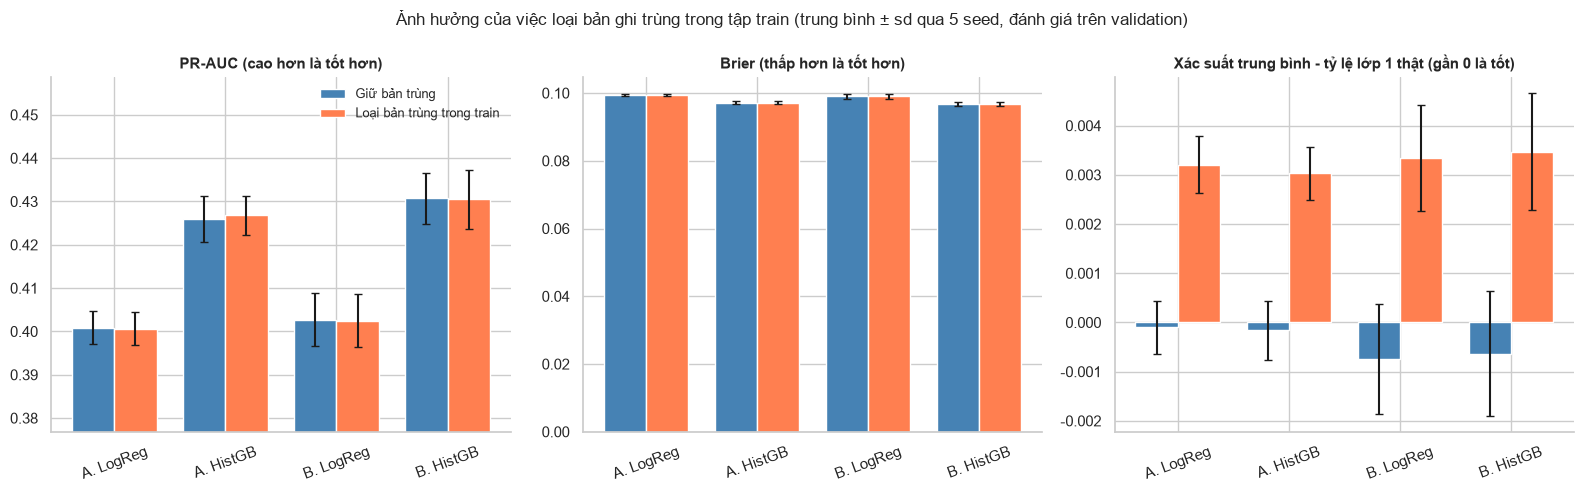

In [20]:
# Biểu đồ kết quả thí nghiệm đối chứng
agg = runs_df.groupby(["Kịch bản", "Mô hình", "Biến thể train"], sort=False)[["PR-AUC", "Brier", "XS trung bình - tỷ lệ thật"]].agg(["mean", "std"])
groups = [(s, m) for s in runs_df["Kịch bản"].unique() for m in MODELS]
labels = [f"{s[:1]}. {m.replace('HistGradientBoosting', 'HistGB').replace('Logistic Regression', 'LogReg')}" for s, m in groups]
colors = {"Giữ bản trùng": "steelblue", "Loại bản trùng trong train": "coral"}
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric, title in zip(axes, ["PR-AUC", "Brier", "XS trung bình - tỷ lệ thật"],
                             ["PR-AUC (cao hơn là tốt hơn)", "Brier (thấp hơn là tốt hơn)", "Xác suất trung bình - tỷ lệ lớp 1 thật (gần 0 là tốt)"]):
    for j, var in enumerate(colors):
        means = [agg.loc[(s, m, var), (metric, "mean")] for s, m in groups]
        sds = [agg.loc[(s, m, var), (metric, "std")] for s, m in groups]
        ax.bar(np.arange(len(groups)) + (j - 0.5) * 0.38, means, 0.38, yerr=sds, capsize=3, color=colors[var], label=var)
    ax.set_xticks(np.arange(len(groups)))
    ax.set_xticklabels(labels, rotation=20)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylim(runs_df["PR-AUC"].min() - 0.02, runs_df["PR-AUC"].max() + 0.02)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Ảnh hưởng của việc loại bản ghi trùng trong tập train (trung bình ± sd qua 5 seed, đánh giá trên validation)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES / "dedup_experiment.png", dpi=300, bbox_inches="tight")
print(f"-> Đã lưu biểu đồ: {FIGURES / 'dedup_experiment.png'}")
plt.show()

**Nhận xét (số liệu: bảng `1_6_dedup_experiment_summary` và `1_6_dedup_experiment_paired_diff`).**

- **Khả năng phân loại và xếp hạng gần như không đổi.** Chênh lệch ROC-AUC và PR-AUC giữa hai biến thể chỉ cỡ 0,0002–0,0007, nhỏ hơn độ lệch chuẩn qua các seed (khoảng 0,001–0,007); hướng chênh lệch không nhất quán giữa các seed và mô hình. Với hai mô hình thử, loại bản trùng **không cải thiện** hiệu năng.
- **Loại bản trùng làm lệch hiệu chuẩn xác suất.** Vì bản trùng tập trung ở lớp 0 (chỉ 1,03% bản trùng thuộc lớp 1), bỏ chúng làm tỷ lệ lớp 1 trong train tăng từ khoảng 13,9% lên khoảng 15,3%. Xác suất dự đoán trung bình trên validation vì vậy cao hơn tỷ lệ thật khoảng 0,003–0,004 (Δ ổn định ở mọi seed), trong khi phương án giữ bản trùng lệch gần 0. Đây là lệch hệ thống nhỏ nhưng có thật; điều này quan trọng với hệ hỗ trợ quyết định vì mức nguy cơ được đọc như xác suất.
- **Kết luận tạm cho Giai đoạn 2:** giữ bản trùng trong train (và chia theo hồ sơ), vì không mất hiệu năng mà xác suất sát tỷ lệ thật hơn. Giới hạn: mới thử Logistic Regression và HistGradientBoosting, mặc định siêu tham số, đánh giá trên validation; cần kiểm lại với Random Forest, XGBoost... ở Giai đoạn 2.
- **So sánh hai kịch bản.** Ở kịch bản A, 12–13% bản ghi validation/test có hồ sơ đã gặp ở train, còn kịch bản B là 0%. Với hai mô hình trên, chỉ số hai kịch bản gần như bằng nhau (chênh lệch trong khoảng sai số giữa các seed), nên chưa thấy dấu hiệu lạc quan do ghi nhớ; điều này chưa chắc đúng với mô hình dễ ghi nhớ hơn (Random Forest sâu), nên Giai đoạn 2 vẫn báo cáo cả hai kịch bản. Kịch bản B đo khả năng tổng quát hóa sang **tổ hợp đặc trưng chưa từng gặp**, không hoàn toàn đồng nghĩa với người tham gia khảo sát mới.

### Kết luận Giai đoạn 1

- **Dữ liệu:** 253.680 bản ghi, 21 đặc trưng, không thiếu giá trị, không vi phạm miền giá trị.
- **Đặc trưng đầu vào:** chỉ dùng đúng 21 đặc trưng gốc (danh sách cố định, có `assert`); nhãn và các cột phụ (`is_copy`, `profile_id`, ...) không đưa vào mô hình.
- **Bản ghi trùng lặp:** 24.206 bản sao (9,54%), nhiều khả năng là người trả lời hợp lệ có hồ sơ giống nhau. **Giữ nguyên, không loại bỏ**; thí nghiệm đối chứng (1.6.4) cho thấy loại bản trùng không cải thiện hiệu năng nhưng làm xác suất dự đoán lệch cao khoảng 0,003–0,004.
- **Mất cân bằng lớp:** lớp 1 chiếm 13,93%. Giữ nguyên phân bố ở validation và test; kỹ thuật cân bằng (class_weight, SMOTENC) chỉ thử trên tập huấn luyện ở Giai đoạn 2.
- **Chia tập:** train 177.483, validation 38.121, test 38.076 bản ghi, tỷ lệ lớp 1 lần lượt 13,94%, 13,89%, 13,93%; không có hồ sơ nào trùng giữa các tập. Danh sách bản ghi từng tập được lưu cố định ở `datas/splits/` kèm `manifest.json` (mã băm dữ liệu, seed).
- **Hai kịch bản đánh giá:** A (ngẫu nhiên theo bản ghi) và B (theo hồ sơ) đều có sẵn danh sách tập; B kiểm tra tổng quát hóa sang tổ hợp đặc trưng chưa gặp, không hoàn toàn giống triển khai trên người mới.
- **Tập test độc lập:** chưa dùng ở bất kỳ phép so sánh nào; mọi lựa chọn mô hình, ngưỡng, hiệu chuẩn, tinh chỉnh chỉ dùng train/validation.
- **Đầu ra cho Giai đoạn 2:** `datas/train.csv`, `validation.csv`, `test.csv`, `datas/splits/`, hàm `load_split()`; bảng trong `results/tables`, biểu đồ trong `results/figures`.

# Giai đoạn 2: Xây dựng và đánh giá các mô hình học máy nâng cao

**Đề tài:** Xây dựng hệ hỗ trợ quyết định đánh giá nguy cơ tiền tiểu đường và tiểu đường dựa trên học máy và dữ liệu khảo sát sức khỏe (CDC BRFSS 2015).

**Nội dung (theo yêu cầu của cô):**
- 2.1 Tối ưu siêu tham số (RandomizedSearchCV) cho Logistic Regression (baseline), Random Forest, XGBoost, LightGBM, và EBM (tùy chọn).
- 2.2 So sánh ba chiến lược xử lý mất cân bằng (không cân bằng + chọn ngưỡng, class_weight/scale_pos_weight, SMOTENC) qua 5 seed, **chỉ trên validation**.
- 2.3 Chọn cấu hình; 2.4 đánh giá cuối trên **test** (hai kịch bản chia tập), trung bình ± độ lệch chuẩn, khoảng tin cậy 95%.
- 2.5 So sánh mô hình bằng kiểm định ghép cặp và bootstrap.
- 2.6 Hiệu chuẩn xác suất (Platt, Isotonic): Brier, Log Loss, ECE, calibration curve.
- 2.7 Chọn ngưỡng theo Recall, Precision và chi phí FN/FP; 2.8 phân tích False Negative.
- 2.9 Thí nghiệm bỏ dần các đặc trưng yếu (để trao đổi với cô về bản rút gọn; mô hình chính vẫn dùng đủ 21 biến).
- 2.0b (tùy chọn) Sàng lọc nhanh nhiều thuật toán bằng LazyPredict.

**Ý nghĩa của xác suất mô hình.** Mô hình ước lượng xác suất một hồ sơ **thuộc nhóm có tiền sử được chẩn đoán tiền tiểu đường/tiểu đường theo dữ liệu khảo sát BRFSS 2015**, không phải xác suất mắc bệnh trong tương lai. Kết quả dùng để hỗ trợ sàng lọc, không thay thế chẩn đoán y khoa.

**Chống rò rỉ tập test.** (1) Siêu tham số chỉ được tinh chỉnh bằng cross-validation theo nhóm hồ sơ trên **train**. (2) Việc chọn chiến lược mất cân bằng chỉ dùng **validation** (mục 2.2–2.3). (3) Bộ hiệu chuẩn và ngưỡng chỉ được học trên **validation**; khi so sánh trên validation dùng cross-fitting. (4) Tập test chỉ được dùng ở mục 2.4 trở đi, sau khi cấu hình đã cố định.

> **Chạy notebook:** cần `dss_utils.py` cùng thư mục, các thư viện trong `requirements.txt` (có xgboost, lightgbm, imbalanced-learn), và đã chạy xong Giai đoạn 1 (có `datas/splits/`). Chạy thử nhanh: đặt `QUICK = True` ở ô cấu hình.

## 2.0 Thiết lập

In [21]:
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import dss_utils as U

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
FIGURES, TABLES = U.FIGURES, U.TABLES
print("Thư mục dự án:", U.FOLDER)

# ------------------------------- CẤU HÌNH -------------------------------
QUICK = False        # True: chạy thử nhanh (2 seed, dữ liệu train nhỏ) chỉ để kiểm tra môi trường; kết quả KHÔNG dùng để báo cáo
INCLUDE_EBM = False  # True: thêm Explainable Boosting Machine (cần `pip install interpret`; chạy lâu hơn)
RERUN = False        # True: xóa kết quả đã lưu của mục 2.2 và chạy lại từ đầu (cần khi đổi siêu tham số/cấu hình)

CFG = dict(seeds=[42, 43, 44, 45, 46],   # 5 seed: mỗi seed là một lần chia lại train/validation/test (theo hồ sơ)
           n_iter=15,                    # số tổ hợp thử trong RandomizedSearchCV
           tune_rows=60000,              # số dòng train dùng khi tinh chỉnh (để giới hạn thời gian)
           max_train_rows=None,          # None = dùng toàn bộ train
           n_jobs=-1,
           cost_ratios=[1, 2, 5, 10, 20])  # giả định chi phí FN so với FP (phân tích độ nhạy)
SPEED = "full"       # "full": cấu hình đầy đủ; "fast": giảm số lần thử và số dòng khi tinh chỉnh để chạy nhanh hơn (bước tinh chỉnh chiếm phần lớn thời gian)
if SPEED == "fast":
    CFG.update(n_iter=8, tune_rows=30000)
if QUICK:
    CFG.update(seeds=[42, 43], n_iter=2, tune_rows=8000, max_train_rows=20000)
    print("CHẾ ĐỘ CHẠY THỬ: kết quả có hậu tố _quick và không dùng để báo cáo (file models/ và results/predictions/ sẽ bị ghi đè).")
TAG = "_quick" if QUICK else ""
STAGE_A_NAME = f"2_stageA_validation_runs{TAG}"
if RERUN and (TABLES / f"{STAGE_A_NAME}.csv").exists():
    (TABLES / f"{STAGE_A_NAME}.csv").unlink()

MODELS, missing = U.available_models(INCLUDE_EBM)
if missing:
    print("CẢNH BÁO: thiếu thư viện cho", missing, "-> chạy `pip install -r requirements.txt` (EBM: `pip install interpret`).")
if not QUICK and any(m in missing for m in ["XGBoost", "LightGBM"]):
    raise ImportError("Thiếu XGBoost/LightGBM: cô yêu cầu tối thiểu các mô hình này. Hãy cài thư viện rồi chạy lại.")
print("Mô hình sẽ so sánh:", MODELS)
print("Seed:", CFG["seeds"])

Thư mục dự án: D:\CK
Mô hình sẽ so sánh: ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM']
Seed: [42, 43, 44, 45, 46]


## 2.0b Sàng lọc nhanh nhiều thuật toán bằng LazyPredict (tùy chọn)

LazyPredict huấn luyện nhanh hàng chục bộ phân loại của scikit-learn với **siêu tham số mặc định** để xem họ thuật toán nào đáng thử. Mục này dùng để **biện minh cho việc chọn mô hình** và phát hiện thuật toán đáng bổ sung; **không thay thế** các bước 2.1–2.8.

Giới hạn cần nói rõ khi báo cáo:
- Chỉ chạy một lần trên một mẫu train nhỏ (`LAZY_ROWS` dòng) và một mẫu validation, kịch bản B, seed đầu tiên; không có nhiều seed, không tinh chỉnh, không có khoảng tin cậy.
- Các chỉ số của LazyPredict (Accuracy, Balanced Accuracy, ROC AUC, F1) tính ở **ngưỡng 0,5**, không có PR-AUC và không có xác suất hiệu chuẩn; với lớp 1 chỉ chiếm 13,9%, Accuracy và F1 ở ngưỡng 0,5 dễ gây hiểu nhầm. Chỉ dùng **ROC AUC** để xếp hạng sơ bộ.
- Một số thuật toán chậm trên dữ liệu lớn (SVC, KNN, Gaussian Process...) bị loại khỏi danh sách.
- Không có kết luận thống kê từ bảng này; việc so sánh chính thức vẫn là mục 2.4–2.5 trên 5 seed.

Cần `pip install lazypredict`. Mặc định `RUN_LAZY = False`.

In [22]:
RUN_LAZY = False   # True: chạy sàng lọc LazyPredict (cần `pip install lazypredict`)
LAZY_ROWS = 30000  # số dòng train dùng để sàng lọc
if RUN_LAZY:
    from lazypredict.Supervised import LazyClassifier, CLASSIFIERS
    SLOW = {"SVC", "NuSVC", "KNeighborsClassifier", "LabelPropagation", "LabelSpreading", "GaussianProcessClassifier",
            "CalibratedClassifierCV", "LinearSVC", "BaggingClassifier"}
    clfs = [c for name, c in CLASSIFIERS if name not in SLOW]
    sp0 = U.get_split("profile", CFG["seeds"][0], LAZY_ROWS)   # train đã lấy mẫu; validation đầy đủ
    Xtr_l, ytr_l, _ = sp0["train"]
    Xva_l, yva_l, _ = sp0["validation"]
    keep = np.random.RandomState(CFG["seeds"][0]).choice(len(yva_l), min(15000, len(yva_l)), replace=False)
    Xva_l, yva_l = Xva_l.iloc[keep], yva_l.iloc[keep]
    t0 = time.time()
    lazy_models, _ = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None, classifiers=clfs,
                                    random_state=CFG["seeds"][0]).fit(Xtr_l, Xva_l, ytr_l, yva_l)
    print(f"Thời gian sàng lọc: {time.time() - t0:.0f}s, số thuật toán: {len(lazy_models)}")
    lazy_table = lazy_models.reset_index().rename(columns={"Model": "Thuật toán"})
    sort_col = "ROC AUC" if "ROC AUC" in lazy_table.columns else "Balanced Accuracy"
    lazy_table = lazy_table.sort_values(sort_col, ascending=False).reset_index(drop=True)
    display(lazy_table.head(15))
    U.save_table(lazy_table.round(4), f"2_0_lazypredict_screening{TAG}")
else:
    print("Bỏ qua sàng lọc LazyPredict (RUN_LAZY = False).")

Bỏ qua sàng lọc LazyPredict (RUN_LAZY = False).


## 2.1 Tối ưu siêu tham số

Mỗi mô hình được tinh chỉnh **một lần** bằng `RandomizedSearchCV` (tiêu chí PR-AUC, 3-fold `StratifiedGroupKFold` theo hồ sơ để các bản ghi cùng hồ sơ không rơi vào cả hai phía của một fold) trên tập train của seed đầu tiên (kịch bản chia theo hồ sơ). Bộ siêu tham số tìm được dùng chung cho cả 5 seed và cả ba chiến lược mất cân bằng; kết quả được lưu vào `models/best_params.json` để lần chạy sau không phải tinh chỉnh lại.

*Giới hạn:* tinh chỉnh một lần dưới chiến lược "không cân bằng" rồi áp dụng cho các chiến lược khác là một đơn giản hóa để giảm thời gian chạy; Random Forest/EBM chỉ tinh chỉnh trên mẫu `tune_rows` dòng.

In [23]:
t0 = time.time()
PARAMS = U.tune_all(MODELS, CFG)
params_table = pd.DataFrame({"Mô hình": list(PARAMS), "Siêu tham số tốt nhất": [json.dumps(v, ensure_ascii=False) for v in PARAMS.values()]})
display(params_table)
U.save_table(params_table, f"2_1_best_hyperparameters{TAG}")
print(f"Thời gian: {time.time() - t0:.0f}s")

   Logistic Regression: dùng kết quả tinh chỉnh đã lưu.
   Random Forest: dùng kết quả tinh chỉnh đã lưu.
   XGBoost: dùng kết quả tinh chỉnh đã lưu.
   LightGBM: dùng kết quả tinh chỉnh đã lưu.


,Mô hình,Siêu tham số tốt nhất
0,Logistic Regression,"{""logisticregression__C"": 0.0019517224641449498}"
1,Random Forest,"{""max_depth"": 12, ""max_features"": 0.3, ""max_sa..."
2,XGBoost,"{""colsample_bytree"": 0.7962072844310213, ""lear..."
3,LightGBM,"{""colsample_bytree"": 0.8058265802441404, ""lear..."


-> Đã lưu bảng: D:\CK\results\tables\2_1_best_hyperparameters.csv
Thời gian: 2s


## 2.2 So sánh chiến lược xử lý mất cân bằng (chỉ trên validation)

Ba chiến lược, đều chỉ tác động lên **train**; validation và test giữ nguyên phân bố gốc (13,9% lớp 1):
- **Không cân bằng:** huấn luyện bình thường, sau đó chọn ngưỡng phân loại.
- **class_weight / scale_pos_weight:** tăng trọng số lớp 1 (`class_weight="balanced"` cho Logistic Regression và Random Forest, `scale_pos_weight = n_lớp0 / n_lớp1` cho XGBoost và LightGBM).
- **SMOTENC:** sinh thêm mẫu lớp 1 sao cho lớp 1 bằng 50% lớp 0. 18 đặc trưng nhị phân/thứ bậc được khai báo là rời rạc, 3 đặc trưng số (BMI, MentHlth, PhysHlth) là liên tục. Không áp dụng SMOTEN cho mọi biến.

Với mỗi tổ hợp và mỗi seed, thang đo không phụ thuộc ngưỡng là ROC-AUC và PR-AUC; đồng thời báo cáo kết quả ở hai điểm vận hành chọn **trên validation**: F1 lớn nhất và Recall ≥ 80%. Cột "XS TB - tỷ lệ thật" cho biết xác suất dự đoán trung bình lệch bao nhiêu so với tỷ lệ lớp 1 thật; các chiến lược cân bằng thường làm giá trị này dương lớn, nghĩa là xác suất bị thổi phồng và cần hiệu chuẩn.

*Lưu ý:* kết quả trong bảng này chỉ dùng để **chọn cấu hình**; chưa dùng tập test. Các số đo theo ngưỡng ở đây hơi lạc quan vì ngưỡng được chọn trên chính validation (như nhau cho mọi tổ hợp).

In [24]:
t0 = time.time()
A = U.run_stage_a(MODELS, PARAMS, CFG, out_name=STAGE_A_NAME)
print(f"Xong {len(A)} lượt chạy. Thời gian phiên này: {time.time() - t0:.0f}s")

SMOTENC: dùng imbalanced-learn
   seed 42 | Logistic Regression  | smotenc      | PR-AUC 0.3864 | ROC-AUC 0.8128 | 122.0s
   seed 42 | Random Forest        | none         | PR-AUC 0.4248 | ROC-AUC 0.8247 | 11.7s
   seed 42 | Random Forest        | class_weight | PR-AUC 0.4246 | ROC-AUC 0.8255 | 14.0s
   seed 42 | Random Forest        | smotenc      | PR-AUC 0.4117 | ROC-AUC 0.8202 | 130.6s
   seed 42 | XGBoost              | none         | PR-AUC 0.4272 | ROC-AUC 0.8269 | 4.2s
   seed 42 | XGBoost              | class_weight | PR-AUC 0.4265 | ROC-AUC 0.8270 | 3.0s
   seed 42 | XGBoost              | smotenc      | PR-AUC 0.4141 | ROC-AUC 0.8201 | 114.2s
   seed 42 | LightGBM             | none         | PR-AUC 0.4296 | ROC-AUC 0.8281 | 4.1s
   seed 42 | LightGBM             | class_weight | PR-AUC 0.4292 | ROC-AUC 0.8281 | 3.9s
   seed 42 | LightGBM             | smotenc      | PR-AUC 0.4119 | ROC-AUC 0.8183 | 120.1s
-> Đã tạo và lưu danh sách tập: D:\CK\datas\splits\split_by_profile_s

In [25]:
cols_a = ["ROC-AUC", "PR-AUC", "Brier", "XS TB - tỷ lệ thật", "Recall @Recall80", "Precision @Recall80", "F1 @F1max", "Recall @F1max"]
A_sum = U.summarize(A, ["Mô hình", "Chiến lược"], cols_a)
display(A_sum)
U.save_table(A_sum, f"2_2_stageA_summary{TAG}")

,Mô hình,Chiến lược,Số seed,ROC-AUC,PR-AUC,Brier,XS TB - tỷ lệ thật,Recall @Recall80,Precision @Recall80,F1 @F1max,Recall @F1max
0,Logistic Regression,none,5,0.8225 ± 0.0033 [0.8184; 0.8265],0.4030 ± 0.0060 [0.3955; 0.4104],0.0990 ± 0.0007 [0.0982; 0.0999],-0.0007 ± 0.0011 [-0.0021; 0.0007],0.8001 ± 0.0001 [0.8000; 0.8001],0.2970 ± 0.0031 [0.2932; 0.3008],0.4618 ± 0.0048 [0.4558; 0.4678],0.6345 ± 0.0177 [0.6125; 0.6565]
1,Logistic Regression,class_weight,5,0.8230 ± 0.0032 [0.8190; 0.8269],0.4014 ± 0.0061 [0.3938; 0.4089],0.1761 ± 0.0012 [0.1746; 0.1775],0.2469 ± 0.0021 [0.2443; 0.2495],0.8001 ± 0.0001 [0.8000; 0.8001],0.2989 ± 0.0031 [0.2950; 0.3027],0.4622 ± 0.0053 [0.4556; 0.4687],0.6296 ± 0.0344 [0.5868; 0.6723]
2,Logistic Regression,smotenc,5,0.8151 ± 0.0034 [0.8109; 0.8194],0.3915 ± 0.0064 [0.3836; 0.3994],0.1261 ± 0.0007 [0.1251; 0.1270],0.1311 ± 0.0017 [0.1289; 0.1332],0.8001 ± 0.0001 [0.8000; 0.8001],0.2894 ± 0.0045 [0.2838; 0.2950],0.4538 ± 0.0049 [0.4477; 0.4599],0.6173 ± 0.0125 [0.6018; 0.6328]
3,Random Forest,none,5,0.8280 ± 0.0030 [0.8243; 0.8317],0.4300 ± 0.0053 [0.4233; 0.4366],0.0970 ± 0.0005 [0.0963; 0.0977],-0.0003 ± 0.0012 [-0.0018; 0.0011],0.8001 ± 0.0001 [0.8000; 0.8001],0.3032 ± 0.0036 [0.2988; 0.3076],0.4703 ± 0.0058 [0.4632; 0.4775],0.6242 ± 0.0306 [0.5862; 0.6621]
4,Random Forest,class_weight,5,0.8284 ± 0.0029 [0.8248; 0.8321],0.4288 ± 0.0049 [0.4227; 0.4349],0.1644 ± 0.0011 [0.1630; 0.1657],0.2252 ± 0.0022 [0.2225; 0.2280],0.8001 ± 0.0001 [0.8000; 0.8001],0.3037 ± 0.0034 [0.2995; 0.3080],0.4702 ± 0.0045 [0.4646; 0.4759],0.6098 ± 0.0155 [0.5906; 0.6290]
5,Random Forest,smotenc,5,0.8226 ± 0.0032 [0.8187; 0.8266],0.4146 ± 0.0031 [0.4107; 0.4185],0.1223 ± 0.0006 [0.1216; 0.1231],0.1269 ± 0.0018 [0.1246; 0.1291],0.8001 ± 0.0001 [0.8000; 0.8001],0.2969 ± 0.0036 [0.2925; 0.3013],0.4597 ± 0.0038 [0.4550; 0.4644],0.6132 ± 0.0219 [0.5860; 0.6404]
6,XGBoost,none,5,0.8296 ± 0.0030 [0.8259; 0.8334],0.4309 ± 0.0060 [0.4235; 0.4383],0.0968 ± 0.0006 [0.0961; 0.0976],-0.0003 ± 0.0011 [-0.0017; 0.0010],0.8001 ± 0.0001 [0.8000; 0.8001],0.3059 ± 0.0026 [0.3026; 0.3092],0.4717 ± 0.0047 [0.4659; 0.4775],0.5917 ± 0.0240 [0.5619; 0.6215]
7,XGBoost,class_weight,5,0.8297 ± 0.0030 [0.8259; 0.8334],0.4299 ± 0.0057 [0.4228; 0.4370],0.1748 ± 0.0012 [0.1734; 0.1763],0.2479 ± 0.0019 [0.2455; 0.2504],0.8001 ± 0.0001 [0.8000; 0.8001],0.3055 ± 0.0029 [0.3019; 0.3090],0.4719 ± 0.0045 [0.4663; 0.4775],0.6136 ± 0.0190 [0.5900; 0.6372]
8,XGBoost,smotenc,5,0.8224 ± 0.0030 [0.8187; 0.8262],0.4160 ± 0.0030 [0.4122; 0.4198],0.1228 ± 0.0006 [0.1220; 0.1236],0.1320 ± 0.0017 [0.1299; 0.1341],0.8001 ± 0.0001 [0.8000; 0.8001],0.2961 ± 0.0023 [0.2932; 0.2990],0.4613 ± 0.0043 [0.4560; 0.4667],0.6264 ± 0.0246 [0.5959; 0.6568]
9,LightGBM,none,5,0.8308 ± 0.0031 [0.8271; 0.8346],0.4344 ± 0.0059 [0.4270; 0.4418],0.0965 ± 0.0006 [0.0957; 0.0973],-0.0006 ± 0.0013 [-0.0022; 0.0010],0.8001 ± 0.0001 [0.8000; 0.8001],0.3072 ± 0.0030 [0.3034; 0.3109],0.4735 ± 0.0058 [0.4663; 0.4806],0.6022 ± 0.0260 [0.5699; 0.6345]


-> Đã lưu bảng: D:\CK\results\tables\2_2_stageA_summary.csv


WindowsPath('D:/CK/results/tables/2_2_stageA_summary.csv')

-> Đã lưu biểu đồ: D:\CK\results\figures\2_2_imbalance_strategies.png


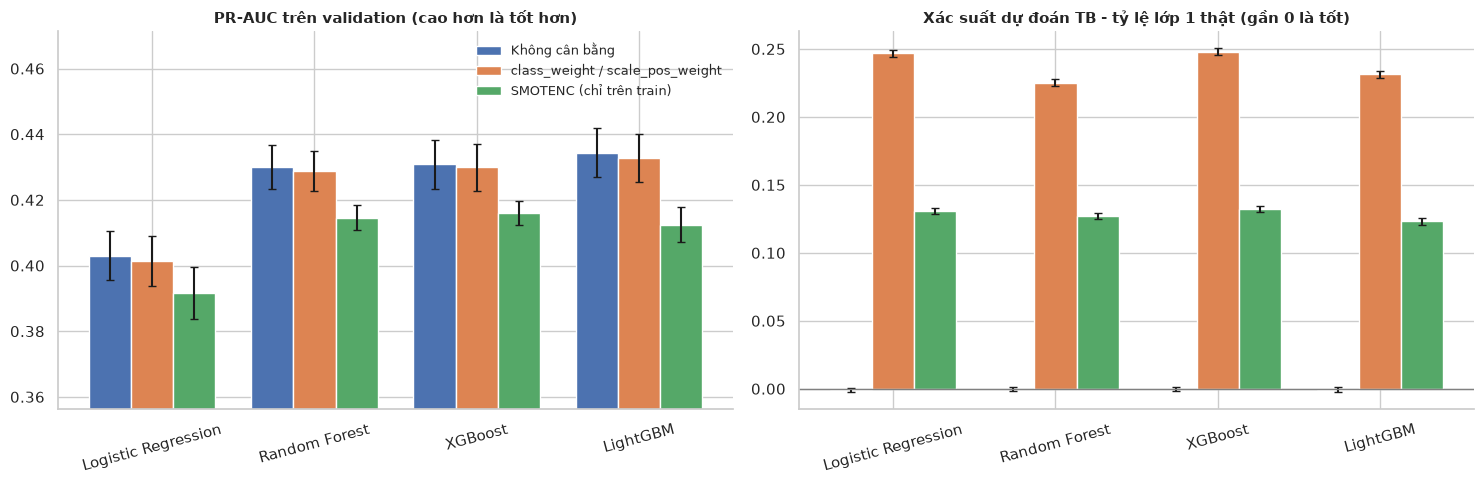

In [26]:
# Biểu đồ: PR-AUC và độ lệch xác suất theo mô hình x chiến lược (trung bình, thanh sai số = CI 95%)
strat_colors = {"none": "#4C72B0", "class_weight": "#DD8452", "smotenc": "#55A868"}
models_order = [m for m in MODELS if m in A["Mô hình"].unique()]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(axes, ["PR-AUC", "XS TB - tỷ lệ thật"],
                             ["PR-AUC trên validation (cao hơn là tốt hơn)", "Xác suất dự đoán TB - tỷ lệ lớp 1 thật (gần 0 là tốt)"]):
    width = 0.26
    for j, strat in enumerate(U.STRATEGIES):
        means, errs = [], []
        for m in models_order:
            v = A[(A["Mô hình"] == m) & (A["Chiến lược"] == strat)][metric]
            if len(v) == 0:
                means.append(np.nan); errs.append(0); continue
            mu, sd, lo, hi = U.mean_sd_ci(v)
            means.append(mu); errs.append(hi - mu)
        ax.bar(np.arange(len(models_order)) + (j - 1) * width, means, width, yerr=errs, capsize=3,
               color=strat_colors[strat], label=U.STRATEGY_LABEL[strat])
    ax.set_xticks(np.arange(len(models_order)))
    ax.set_xticklabels(models_order, rotation=15)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
axes[0].set_ylim(A["PR-AUC"].min() - 0.03, A["PR-AUC"].max() + 0.03)
axes[1].axhline(0, color="gray", lw=1)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / f"2_2_imbalance_strategies{TAG}.png", dpi=300, bbox_inches="tight")
print("-> Đã lưu biểu đồ:", FIGURES / f"2_2_imbalance_strategies{TAG}.png")
plt.show()

### 2.3 Chọn cấu hình cho từng mô hình

Với mỗi mô hình, chiến lược mất cân bằng có **PR-AUC trung bình trên validation** lớn nhất được chọn (PR-AUC phù hợp với dữ liệu mất cân bằng và không phụ thuộc ngưỡng). Mô hình có PR-AUC trung bình lớn nhất được coi là mô hình chính cho các phân tích sâu ở mục 2.6–2.8. Việc chọn này không dùng tập test.

In [27]:
SEL = U.select_strategies(A)
SEL["Hạng"] = SEL["PR-AUC validation (TB)"].rank(ascending=False).astype(int)
display(SEL.sort_values("Hạng"))
U.save_table(SEL, f"2_3_selected_configurations{TAG}")
CHOICES = dict(zip(SEL["Mô hình"], SEL["Chiến lược"]))
BEST_MODEL = SEL.sort_values("PR-AUC validation (TB)", ascending=False).iloc[0]["Mô hình"]
print("Cấu hình đã chọn:", CHOICES)
print("Mô hình chính (PR-AUC validation cao nhất):", BEST_MODEL)

,Mô hình,Chiến lược,PR-AUC validation (TB),Hạng
0,LightGBM,none,0.434415,1
3,XGBoost,none,0.430884,2
2,Random Forest,none,0.429975,3
1,Logistic Regression,none,0.402964,4


-> Đã lưu bảng: D:\CK\results\tables\2_3_selected_configurations.csv
Cấu hình đã chọn: {'LightGBM': 'none', 'Logistic Regression': 'none', 'Random Forest': 'none', 'XGBoost': 'none'}
Mô hình chính (PR-AUC validation cao nhất): LightGBM


## 2.4 Đánh giá cuối trên tập test

Từ đây mới dùng tập test. Mỗi cấu hình đã chọn được huấn luyện lại trên train của từng seed, rồi:
1. dự đoán xác suất cho validation và test;
2. hiệu chuẩn (Platt, Isotonic) bằng bộ hiệu chuẩn học trên **validation**; phương pháp hiệu chuẩn tốt nhất được chọn theo Brier **cross-fit trên validation**;
3. chọn ngưỡng trên validation (xác suất đã hiệu chuẩn, cross-fit) rồi áp dụng nguyên ngưỡng đó lên test.

Hai kịch bản chia tập đều được chạy: **B – chia theo hồ sơ** (kịch bản chính; đo khả năng tổng quát hóa sang tổ hợp đặc trưng chưa từng gặp, không hoàn toàn giống triển khai trên người mới) và **A – chia ngẫu nhiên theo bản ghi**. Cấu hình và siêu tham số giống nhau ở hai kịch bản.

In [28]:
t0 = time.time()
P, T, C = U.evaluate_final(CHOICES, PARAMS, ["profile", "record"], CFG)
U.save_table(P.round(6), f"2_4_final_probability_metrics_raw{TAG}")
U.save_table(T.round(6), f"2_4_final_threshold_metrics_raw{TAG}")
U.save_table(C.round(6), f"2_4_final_cost_raw{TAG}")
print(f"Thời gian: {time.time() - t0:.0f}s")

   [profile] seed 42 | LightGBM             | none         | hiệu chuẩn: none     | 56s
   [profile] seed 42 | Logistic Regression  | none         | hiệu chuẩn: isotonic | 54s
   [profile] seed 42 | Random Forest        | none         | hiệu chuẩn: sigmoid  | 66s
   [profile] seed 42 | XGBoost              | none         | hiệu chuẩn: sigmoid  | 54s
   [profile] seed 43 | LightGBM             | none         | hiệu chuẩn: none     | 56s
   [profile] seed 43 | Logistic Regression  | none         | hiệu chuẩn: isotonic | 51s
   [profile] seed 43 | Random Forest        | none         | hiệu chuẩn: sigmoid  | 63s
   [profile] seed 43 | XGBoost              | none         | hiệu chuẩn: sigmoid  | 54s
   [profile] seed 44 | LightGBM             | none         | hiệu chuẩn: sigmoid  | 56s
   [profile] seed 44 | Logistic Regression  | none         | hiệu chuẩn: isotonic | 52s
   [profile] seed 44 | Random Forest        | none         | hiệu chuẩn: sigmoid  | 64s
   [profile] seed 44 | XGBoost  

In [29]:
SC_LABEL = {"profile": "B. Chia theo hồ sơ", "record": "A. Chia ngẫu nhiên theo bản ghi"}
# Khả năng xếp hạng (không phụ thuộc ngưỡng) trên test, dùng xác suất chưa hiệu chuẩn
rk = P[(P["Tập"] == "test") & (P["Hiệu chuẩn"] == "none")].copy()
rk["Kịch bản"] = rk["Kịch bản"].map(SC_LABEL)
rank_table = U.summarize(rk, ["Kịch bản", "Mô hình", "Chiến lược"], ["ROC-AUC", "PR-AUC"])
display(rank_table)
U.save_table(rank_table, f"2_4_test_ranking_summary{TAG}")

,Kịch bản,Mô hình,Chiến lược,Số seed,ROC-AUC,PR-AUC
0,B. Chia theo hồ sơ,LightGBM,none,5,0.8310 ± 0.0022 [0.8283; 0.8338],0.4379 ± 0.0049 [0.4317; 0.4440]
1,B. Chia theo hồ sơ,Logistic Regression,none,5,0.8226 ± 0.0027 [0.8193; 0.8259],0.4097 ± 0.0067 [0.4014; 0.4180]
2,B. Chia theo hồ sơ,Random Forest,none,5,0.8281 ± 0.0020 [0.8255; 0.8306],0.4339 ± 0.0049 [0.4278; 0.4400]
3,B. Chia theo hồ sơ,XGBoost,none,5,0.8298 ± 0.0020 [0.8274; 0.8323],0.4353 ± 0.0049 [0.4291; 0.4414]
4,A. Chia ngẫu nhiên theo bản ghi,LightGBM,none,5,0.8314 ± 0.0019 [0.8290; 0.8339],0.4352 ± 0.0034 [0.4311; 0.4394]
5,A. Chia ngẫu nhiên theo bản ghi,Logistic Regression,none,5,0.8233 ± 0.0024 [0.8204; 0.8263],0.4053 ± 0.0047 [0.3995; 0.4111]
6,A. Chia ngẫu nhiên theo bản ghi,Random Forest,none,5,0.8284 ± 0.0019 [0.8261; 0.8307],0.4306 ± 0.0027 [0.4273; 0.4339]
7,A. Chia ngẫu nhiên theo bản ghi,XGBoost,none,5,0.8302 ± 0.0018 [0.8280; 0.8324],0.4309 ± 0.0028 [0.4275; 0.4344]


-> Đã lưu bảng: D:\CK\results\tables\2_4_test_ranking_summary.csv


WindowsPath('D:/CK/results/tables/2_4_test_ranking_summary.csv')

In [30]:
# Chỉ số phân loại tại các điểm vận hành (ngưỡng chọn trên validation), kịch bản B
ops_show = ["F1 lớn nhất", "Recall >= 80%", "Recall >= 90%"]
tb = T[(T["Kịch bản"] == "profile") & (T["Điểm vận hành"].isin(ops_show))].copy()
thr_table = U.summarize(tb, ["Điểm vận hành", "Mô hình"], ["Precision", "Recall", "Specificity", "F1", "Balanced Accuracy", "FN", "FP", "Tỷ lệ cảnh báo (%)"], digits=3)
display(thr_table)
U.save_table(thr_table, f"2_4_test_threshold_summary_profile{TAG}")

# Ma trận nhầm lẫn trung bình (số bản ghi) tại điểm vận hành "Recall >= 80%" và "F1 lớn nhất"
cm = tb.groupby(["Điểm vận hành", "Mô hình"], sort=False)[["TN", "FP", "FN", "TP"]].mean().round(0).astype(int).reset_index()
display(cm)
U.save_table(cm, f"2_4_test_confusion_matrix_mean_profile{TAG}")

,Điểm vận hành,Mô hình,Số seed,Precision,Recall,Specificity,F1,Balanced Accuracy,FN,FP,Tỷ lệ cảnh báo (%)
0,F1 lớn nhất,LightGBM,5,0.386 ± 0.011 [0.372; 0.400],0.611 ± 0.017 [0.590; 0.633],0.842 ± 0.012 [0.828; 0.857],0.473 ± 0.004 [0.468; 0.478],0.727 ± 0.003 [0.723; 0.731],2060.000 ± 91.441 [1946.461; 2173.539],5161.600 ± 387.057 [4681.005; 5642.195],22.097 ± 1.232 [20.568; 23.627]
1,Recall >= 80%,LightGBM,5,0.306 ± 0.002 [0.303; 0.309],0.801 ± 0.009 [0.790; 0.812],0.705 ± 0.006 [0.698; 0.712],0.442 ± 0.003 [0.439; 0.446],0.753 ± 0.003 [0.749; 0.757],1056.400 ± 48.138 [996.628; 1116.172],9650.200 ± 161.223 [9450.016; 9850.384],36.541 ± 0.592 [35.806; 37.276]
2,Recall >= 90%,LightGBM,5,0.258 ± 0.004 [0.253; 0.263],0.897 ± 0.009 [0.886; 0.908],0.582 ± 0.013 [0.566; 0.597],0.401 ± 0.004 [0.396; 0.405],0.739 ± 0.003 [0.735; 0.743],546.800 ± 46.154 [489.492; 604.108],13693.000 ± 385.229 [13214.675; 14171.325],48.513 ± 1.206 [47.015; 50.010]
3,F1 lớn nhất,Logistic Regression,5,0.359 ± 0.007 [0.350; 0.367],0.640 ± 0.019 [0.617; 0.664],0.814 ± 0.011 [0.801; 0.828],0.460 ± 0.004 [0.454; 0.465],0.727 ± 0.005 [0.721; 0.734],1907.400 ± 100.361 [1782.786; 2032.014],6076.400 ± 334.644 [5660.885; 6491.915],24.907 ± 1.177 [23.446; 26.368]
4,Recall >= 80%,Logistic Regression,5,0.299 ± 0.006 [0.291; 0.306],0.792 ± 0.013 [0.776; 0.807],0.699 ± 0.012 [0.684; 0.714],0.434 ± 0.005 [0.428; 0.440],0.745 ± 0.002 [0.742; 0.748],1105.200 ± 68.185 [1020.537; 1189.863],9854.400 ± 413.265 [9341.263; 10367.537],36.948 ± 1.217 [35.437; 38.459]
5,Recall >= 90%,Logistic Regression,5,0.252 ± 0.006 [0.244; 0.259],0.897 ± 0.011 [0.884; 0.910],0.567 ± 0.019 [0.543; 0.591],0.393 ± 0.006 [0.385; 0.401],0.732 ± 0.005 [0.726; 0.738],544.600 ± 55.922 [475.163; 614.037],14167.600 ± 618.537 [13399.585; 14935.615],49.766 ± 1.795 [47.536; 51.995]
6,F1 lớn nhất,Random Forest,5,0.377 ± 0.014 [0.361; 0.394],0.627 ± 0.037 [0.582; 0.673],0.832 ± 0.019 [0.808; 0.855],0.470 ± 0.002 [0.468; 0.473],0.729 ± 0.009 [0.718; 0.741],1975.600 ± 194.939 [1733.551; 2217.649],5513.800 ± 610.659 [4755.566; 6272.034],23.246 ± 2.101 [20.638; 25.854]
7,Recall >= 80%,Random Forest,5,0.301 ± 0.003 [0.298; 0.305],0.799 ± 0.010 [0.787; 0.811],0.700 ± 0.007 [0.690; 0.709],0.438 ± 0.002 [0.435; 0.441],0.749 ± 0.002 [0.746; 0.753],1063.600 ± 51.530 [999.618; 1127.582],9831.800 ± 219.972 [9558.669; 10104.931],37.000 ± 0.765 [36.051; 37.949]
8,Recall >= 90%,Random Forest,5,0.253 ± 0.003 [0.249; 0.257],0.897 ± 0.008 [0.886; 0.907],0.571 ± 0.011 [0.557; 0.585],0.395 ± 0.003 [0.391; 0.399],0.734 ± 0.002 [0.731; 0.737],548.600 ± 44.825 [492.942; 604.258],14033.200 ± 347.139 [13602.171; 14464.229],49.402 ± 1.094 [48.044; 50.760]
9,F1 lớn nhất,XGBoost,5,0.383 ± 0.009 [0.371; 0.394],0.617 ± 0.025 [0.586; 0.649],0.839 ± 0.013 [0.823; 0.854],0.472 ± 0.002 [0.470; 0.474],0.728 ± 0.006 [0.720; 0.736],2029.600 ± 135.508 [1861.345; 2197.855],5285.000 ± 407.539 [4778.974; 5791.026],22.504 ± 1.440 [20.716; 24.292]


-> Đã lưu bảng: D:\CK\results\tables\2_4_test_threshold_summary_profile.csv


,Điểm vận hành,Mô hình,TN,FP,FN,TP
0,F1 lớn nhất,LightGBM,27566,5162,2060,3242
1,Recall >= 80%,LightGBM,23077,9650,1056,4246
2,Recall >= 90%,LightGBM,19034,13693,547,4756
3,F1 lớn nhất,Logistic Regression,26651,6076,1907,3395
4,Recall >= 80%,Logistic Regression,22873,9854,1105,4197
5,Recall >= 90%,Logistic Regression,18560,14168,545,4758
6,F1 lớn nhất,Random Forest,27214,5514,1976,3327
7,Recall >= 80%,Random Forest,22896,9832,1064,4239
8,Recall >= 90%,Random Forest,18694,14033,549,4754
9,F1 lớn nhất,XGBoost,27442,5285,2030,3273


-> Đã lưu bảng: D:\CK\results\tables\2_4_test_confusion_matrix_mean_profile.csv


WindowsPath('D:/CK/results/tables/2_4_test_confusion_matrix_mean_profile.csv')

In [31]:
# So sánh hai kịch bản đánh giá: chênh lệch (A - B) của PR-AUC và ROC-AUC theo từng seed và mô hình
base = P[(P["Tập"] == "test") & (P["Hiệu chuẩn"] == "none")].pivot_table(index=["Mô hình", "Seed"], columns="Kịch bản", values=["ROC-AUC", "PR-AUC"])
rows = []
for m in base.index.get_level_values(0).unique():
    sub = base.loc[m]
    row = {"Mô hình": m}
    for met in ["ROC-AUC", "PR-AUC"]:
        d = (sub[(met, "record")] - sub[(met, "profile")]).to_numpy()
        row[f"{met}: A - B (TB ± sd)"] = f"{d.mean():+.4f} ± {d.std(ddof=1) if len(d) > 1 else 0:.4f}"
    rows.append(row)
scen_diff = pd.DataFrame(rows)
display(scen_diff)
U.save_table(scen_diff, f"2_4_scenario_A_vs_B{TAG}")

,Mô hình,ROC-AUC: A - B (TB ± sd),PR-AUC: A - B (TB ± sd)
0,LightGBM,+0.0004 ± 0.0020,-0.0026 ± 0.0056
1,Logistic Regression,+0.0007 ± 0.0020,-0.0044 ± 0.0059
2,Random Forest,+0.0004 ± 0.0018,-0.0033 ± 0.0040
3,XGBoost,+0.0003 ± 0.0014,-0.0043 ± 0.0040


-> Đã lưu bảng: D:\CK\results\tables\2_4_scenario_A_vs_B.csv


WindowsPath('D:/CK/results/tables/2_4_scenario_A_vs_B.csv')

*Cách đọc:* nếu chênh lệch A − B dương rõ và lớn hơn độ lệch chuẩn, kịch bản A lạc quan hơn B (mô hình hưởng lợi từ các hồ sơ đã gặp trong train). Nếu chênh lệch nhỏ, mô hình tổng quát hóa sang hồ sơ mới gần như tương đương. Kết quả của B là kết quả báo cáo chính.

## 2.5 So sánh mô hình bằng kiểm định thống kê

Không kết luận "mô hình A tốt hơn B" chỉ dựa trên chênh lệch nhỏ của một lần chạy. Hai cách kiểm tra (trên kịch bản B, test, xác suất chưa hiệu chuẩn):
- **t-test ghép cặp qua các seed** trên PR-AUC (mỗi seed là một lần chia lại dữ liệu). Với 5 seed, kiểm định có công suất thấp; p-value được hiệu chỉnh Holm cho các so sánh với baseline.
- **Bootstrap ghép cặp theo bản ghi** trên test của seed đầu tiên (1000 lần lấy mẫu lại): khoảng tin cậy 95% của chênh lệch PR-AUC. Bootstrap chỉ phản ánh sai số lấy mẫu trên một tập test, không phản ánh biến thiên giữa các lần chia.

In [32]:
BASELINE = "Logistic Regression"
prof = P[(P["Kịch bản"] == "profile") & (P["Tập"] == "test") & (P["Hiệu chuẩn"] == "none")]
pivot = prof.pivot_table(index="Seed", columns="Mô hình", values="PR-AUC")
others = [m for m in pivot.columns if m != BASELINE]
rows = []
for m in others:
    d = (pivot[m] - pivot[BASELINE]).to_numpy()
    t_stat, p_val = stats.ttest_rel(pivot[m], pivot[BASELINE]) if len(d) > 1 else (np.nan, np.nan)
    rows.append({"So sánh": f"{m} - {BASELINE}", "Chênh lệch PR-AUC (TB ± sd)": f"{d.mean():+.4f} ± {d.std(ddof=1) if len(d) > 1 else 0:.4f}",
                 "Số seed mô hình tốt hơn": f"{int((d > 0).sum())}/{len(d)}", "p (t-test ghép cặp)": p_val})
cmp_df = pd.DataFrame(rows)
if len(cmp_df) and cmp_df["p (t-test ghép cặp)"].notna().all():
    cmp_df["p (hiệu chỉnh Holm)"] = U.holm_adjust(cmp_df["p (t-test ghép cặp)"])

# Bootstrap ghép cặp trên test của seed đầu tiên
s0 = CFG["seeds"][0]
def load_pred(model, scen="profile", seed=s0):
    return np.load(U.PRED_DIR / f"{scen}_{model.replace(' ', '_')}_seed{seed}.npz", allow_pickle=True)
base_pred = load_pred(BASELINE)
boot_rows = []
for m in others:
    pr = load_pred(m)
    b = U.paired_bootstrap_diff(pr["y_test"], pr["p_raw"], base_pred["p_raw"], n_boot=1000, seed=s0)
    boot_rows.append({"So sánh": f"{m} - {BASELINE}", f"Bootstrap (seed {s0}): chênh PR-AUC": f"{b['Chênh lệch']:+.4f} [{b['CI95 dưới']:+.4f}; {b['CI95 trên']:+.4f}]",
                      "p (bootstrap)": b["p (bootstrap, 2 phía)"]})
cmp_df = cmp_df.merge(pd.DataFrame(boot_rows), on="So sánh") if len(boot_rows) else cmp_df
display(cmp_df)
U.save_table(cmp_df, f"2_5_model_comparison_tests{TAG}")

,So sánh,Chênh lệch PR-AUC (TB ± sd),Số seed mô hình tốt hơn,p (t-test ghép cặp),p (hiệu chỉnh Holm),Bootstrap (seed 42): chênh PR-AUC,p (bootstrap)
0,LightGBM - Logistic Regression,+0.0282 ± 0.0037,5/5,0.000069,0.000206,+0.0303 [+0.0233; +0.0370],0.001998
1,Random Forest - Logistic Regression,+0.0242 ± 0.0040,5/5,0.000177,0.000206,+0.0255 [+0.0188; +0.0325],0.001998
2,XGBoost - Logistic Regression,+0.0256 ± 0.0034,5/5,0.000077,0.000206,+0.0265 [+0.0201; +0.0328],0.001998


-> Đã lưu bảng: D:\CK\results\tables\2_5_model_comparison_tests.csv


WindowsPath('D:/CK/results/tables/2_5_model_comparison_tests.csv')

## 2.6 Hiệu chuẩn xác suất

Xác suất đầu ra chỉ có ý nghĩa như "tỷ lệ" nếu phản ánh đúng tần suất lớp 1. Ta so sánh xác suất **chưa hiệu chuẩn**, **Platt (sigmoid)** và **Isotonic** bằng Brier Score, Log Loss, ECE (sai số hiệu chuẩn kỳ vọng, 10 bin theo phân vị) và calibration curve. Bộ hiệu chuẩn được học trên validation; trên validation chỉ đánh giá bằng cross-fitting để không đánh giá trên dữ liệu đã dùng để học; kết quả quyết định nằm ở cột **test**.

In [33]:
cal = P[P["Kịch bản"] == "profile"].copy()
cal["Hiệu chuẩn"] = cal["Hiệu chuẩn"].map(U.CAL_LABEL)
cal_table = U.summarize(cal, ["Tập", "Mô hình", "Hiệu chuẩn"], ["Brier", "Log Loss", "ECE", "XS TB - tỷ lệ thật"], digits=4)
display(cal_table[cal_table["Tập"] == "test"])
U.save_table(cal_table, f"2_6_calibration_summary_profile{TAG}")

# Mức cải thiện Brier sau hiệu chuẩn so với chưa hiệu chuẩn (test, từng seed)
pv = P[(P["Kịch bản"] == "profile") & (P["Tập"] == "test")].pivot_table(index=["Mô hình", "Seed"], columns="Hiệu chuẩn", values="Brier")
imp = pd.DataFrame({"Platt - chưa HC": pv["sigmoid"] - pv["none"], "Isotonic - chưa HC": pv["isotonic"] - pv["none"]}).groupby("Mô hình").agg(["mean", "std"]).round(5)
print("Thay đổi Brier trên test (âm = tốt hơn sau hiệu chuẩn):")
display(imp)
U.save_table(imp.reset_index(), f"2_6_brier_change_after_calibration{TAG}")

,Tập,Mô hình,Hiệu chuẩn,Số seed,Brier,Log Loss,ECE,XS TB - tỷ lệ thật
1,test,LightGBM,Chưa hiệu chuẩn,5,0.0964 ± 0.0003 [0.0960; 0.0968],0.3119 ± 0.0013 [0.3103; 0.3136],0.0054 ± 0.0008 [0.0044; 0.0063],-0.0000 ± 0.0006 [-0.0008; 0.0008]
3,test,LightGBM,Platt (sigmoid),5,0.0964 ± 0.0004 [0.0959; 0.0968],0.3117 ± 0.0014 [0.3099; 0.3135],0.0048 ± 0.0017 [0.0027; 0.0069],0.0007 ± 0.0016 [-0.0013; 0.0026]
5,test,LightGBM,Isotonic,5,0.0965 ± 0.0004 [0.0960; 0.0970],0.3126 ± 0.0017 [0.3106; 0.3147],0.0043 ± 0.0012 [0.0029; 0.0057],0.0007 ± 0.0016 [-0.0013; 0.0027]
7,test,Logistic Regression,Chưa hiệu chuẩn,5,0.0988 ± 0.0005 [0.0981; 0.0994],0.3193 ± 0.0016 [0.3173; 0.3213],0.0127 ± 0.0009 [0.0116; 0.0137],0.0001 ± 0.0008 [-0.0009; 0.0011]
9,test,Logistic Regression,Platt (sigmoid),5,0.0988 ± 0.0005 [0.0981; 0.0995],0.3193 ± 0.0017 [0.3172; 0.3214],0.0129 ± 0.0013 [0.0113; 0.0145],0.0009 ± 0.0011 [-0.0005; 0.0023]
11,test,Logistic Regression,Isotonic,5,0.0985 ± 0.0005 [0.0978; 0.0992],0.3179 ± 0.0020 [0.3154; 0.3204],0.0052 ± 0.0013 [0.0035; 0.0068],0.0008 ± 0.0013 [-0.0008; 0.0024]
13,test,Random Forest,Chưa hiệu chuẩn,5,0.0969 ± 0.0003 [0.0966; 0.0973],0.3137 ± 0.0012 [0.3122; 0.3152],0.0077 ± 0.0012 [0.0062; 0.0092],0.0001 ± 0.0005 [-0.0005; 0.0008]
15,test,Random Forest,Platt (sigmoid),5,0.0968 ± 0.0003 [0.0965; 0.0972],0.3133 ± 0.0013 [0.3117; 0.3149],0.0036 ± 0.0008 [0.0026; 0.0046],0.0005 ± 0.0014 [-0.0013; 0.0023]
17,test,Random Forest,Isotonic,5,0.0969 ± 0.0003 [0.0966; 0.0973],0.3142 ± 0.0014 [0.3124; 0.3159],0.0044 ± 0.0009 [0.0034; 0.0055],0.0005 ± 0.0014 [-0.0012; 0.0022]
19,test,XGBoost,Chưa hiệu chuẩn,5,0.0967 ± 0.0003 [0.0964; 0.0970],0.3135 ± 0.0010 [0.3122; 0.3148],0.0097 ± 0.0011 [0.0083; 0.0111],0.0001 ± 0.0007 [-0.0007; 0.0009]


-> Đã lưu bảng: D:\CK\results\tables\2_6_calibration_summary_profile.csv
Thay đổi Brier trên test (âm = tốt hơn sau hiệu chuẩn):


Platt - chưa HC          Isotonic - chưa HC         
                               mean      std               mean      std
Mô hình                                                                 
LightGBM                   -0.00001  0.00004            0.00011  0.00008
Logistic Regression         0.00005  0.00006           -0.00027  0.00008
Random Forest              -0.00011  0.00003            0.00001  0.00006
XGBoost                    -0.00013  0.00006           -0.00005  0.00008

-> Đã lưu bảng: D:\CK\results\tables\2_6_brier_change_after_calibration.csv


WindowsPath('D:/CK/results/tables/2_6_brier_change_after_calibration.csv')

-> Đã lưu biểu đồ: D:\CK\results\figures\2_6_calibration_curves.png


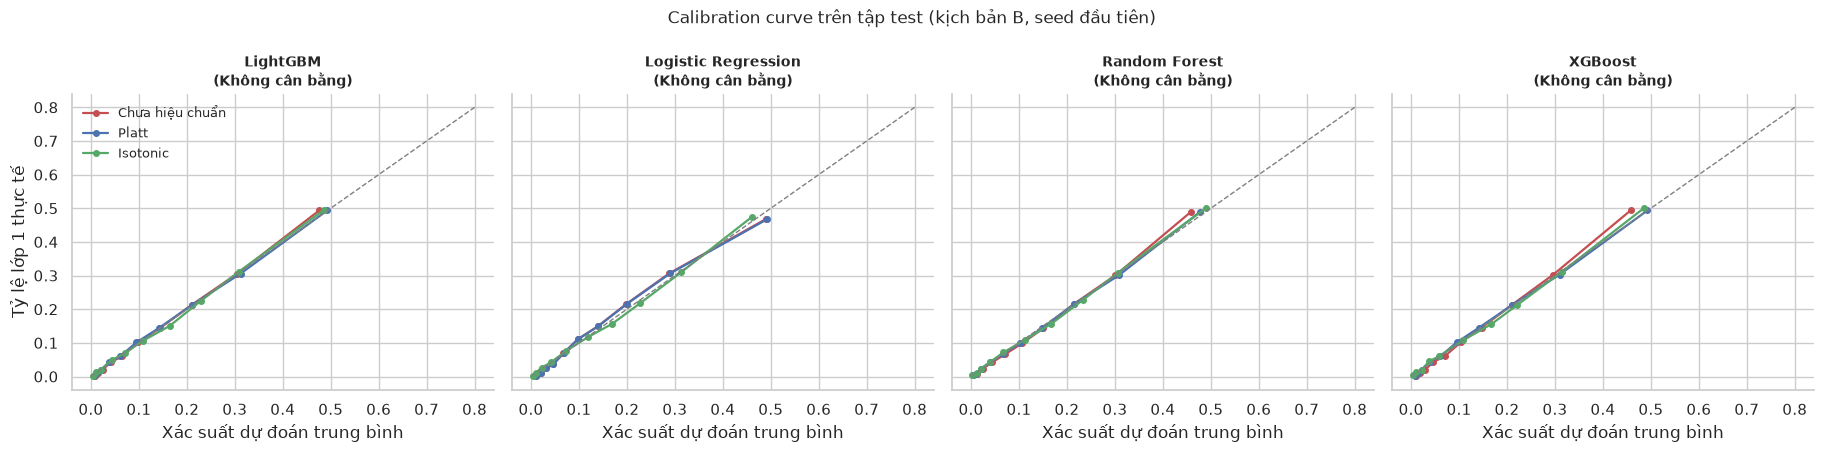

In [34]:
# Calibration curve trên test (seed đầu tiên, kịch bản B): chưa hiệu chuẩn vs Platt vs Isotonic
n_m = len(CHOICES)
fig, axes = plt.subplots(1, n_m, figsize=(4.6 * n_m, 4.6), sharey=True)
axes = np.atleast_1d(axes)
for ax, m in zip(axes, CHOICES):
    d = load_pred(m)
    for key, label, color in [("p_raw", "Chưa hiệu chuẩn", "#C44E52"), ("p_sigmoid", "Platt", "#4C72B0"), ("p_isotonic", "Isotonic", "#55A868")]:
        frac, mean_p = calibration_curve(d["y_test"], d[key], n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, marker="o", ms=4, lw=1.6, color=color, label=label)
    ax.plot([0, 0.8], [0, 0.8], "--", color="gray", lw=1)
    ax.set_title(f"{m}\n({U.STRATEGY_LABEL[CHOICES[m]]})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Xác suất dự đoán trung bình")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
axes[0].set_ylabel("Tỷ lệ lớp 1 thực tế")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Calibration curve trên tập test (kịch bản B, seed đầu tiên)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES / f"2_6_calibration_curves{TAG}.png", dpi=300, bbox_inches="tight")
print("-> Đã lưu biểu đồ:", FIGURES / f"2_6_calibration_curves{TAG}.png")
plt.show()

## 2.7 Chọn ngưỡng phân loại

Ngưỡng không được chọn tùy ý. Các điểm vận hành được xác định **trên validation** (xác suất đã hiệu chuẩn, cross-fit) rồi áp dụng nguyên lên test:
- **F1 lớn nhất:** cân bằng Precision và Recall.
- **Recall ≥ 80% / ≥ 90%:** ưu tiên không bỏ sót (sàng lọc); chọn ngưỡng cao nhất vẫn đạt Recall mục tiêu, tức Precision lớn nhất có thể.
- **Tối thiểu chi phí kỳ vọng** `C_FN × FN + C_FP × FP` với tỷ lệ `C_FN : C_FP` = 1:1, 2:1, 5:1, 10:1, 20:1.

**Về chi phí:** nhóm chưa có số liệu chi phí thực tế của FN và FP. Các tỷ lệ trên là **giả định để phân tích độ nhạy**, không phải số liệu y khoa; kết quả cho thấy ngưỡng và số cảnh báo thay đổi thế nào khi coi một ca bỏ sót "đắt" gấp bao nhiêu lần một cảnh báo sai. Với xác suất đã hiệu chuẩn, ngưỡng lý thuyết tối ưu là `C_FP / (C_FP + C_FN)`, được in kèm để đối chiếu.

In [35]:
ops_all = ["F1 lớn nhất", "Recall >= 80%", "Recall >= 90%"] + [f"Chi phí FN:FP = {r}:1" for r in CFG["cost_ratios"]]
tp = T[(T["Kịch bản"] == "profile") & (T["Mô hình"] == BEST_MODEL)].copy()
op_table = U.summarize(tp, ["Điểm vận hành"], ["Ngưỡng", "Precision", "Recall", "Specificity", "F1", "FN", "FP", "Tỷ lệ cảnh báo (%)"], digits=3)
op_table["Điểm vận hành"] = pd.Categorical(op_table["Điểm vận hành"], ops_all, ordered=True)
op_table = op_table.sort_values("Điểm vận hành").reset_index(drop=True)
print(f"Mô hình chính: {BEST_MODEL} ({U.STRATEGY_LABEL[CHOICES[BEST_MODEL]]}); kết quả trên test, kịch bản B")
display(op_table)
U.save_table(op_table, f"2_7_operating_points_best_model{TAG}")

cost_tab = C[(C["Kịch bản"] == "profile")].groupby(["Tỷ lệ chi phí FN:FP", "Mô hình"], sort=False)[["Ngưỡng", "Chi phí TB / 1000 người (test)", "Chi phí nếu không cảnh báo ai", "Chi phí nếu cảnh báo tất cả", "Recall", "Precision"]].mean().round(3).reset_index()
cost_tab["Ngưỡng lý thuyết 1/(1+r)"] = (1 / (1 + cost_tab["Tỷ lệ chi phí FN:FP"])).round(3)
display(cost_tab)
U.save_table(cost_tab, f"2_7_cost_sensitivity{TAG}")

Mô hình chính: LightGBM (Không cân bằng); kết quả trên test, kịch bản B


,Điểm vận hành,Số seed,Ngưỡng,Precision,Recall,Specificity,F1,FN,FP,Tỷ lệ cảnh báo (%)
0,F1 lớn nhất,5,0.238 ± 0.013 [0.221; 0.255],0.386 ± 0.011 [0.372; 0.400],0.611 ± 0.017 [0.590; 0.633],0.842 ± 0.012 [0.828; 0.857],0.473 ± 0.004 [0.468; 0.478],2060.000 ± 91.441 [1946.461; 2173.539],5161.600 ± 387.057 [4681.005; 5642.195],22.097 ± 1.232 [20.568; 23.627]
1,Recall >= 80%,5,0.134 ± 0.003 [0.129; 0.138],0.306 ± 0.002 [0.303; 0.309],0.801 ± 0.009 [0.790; 0.812],0.705 ± 0.006 [0.698; 0.712],0.442 ± 0.003 [0.439; 0.446],1056.400 ± 48.138 [996.628; 1116.172],9650.200 ± 161.223 [9450.016; 9850.384],36.541 ± 0.592 [35.806; 37.276]
2,Recall >= 90%,5,0.081 ± 0.005 [0.076; 0.087],0.258 ± 0.004 [0.253; 0.263],0.897 ± 0.009 [0.886; 0.908],0.582 ± 0.013 [0.566; 0.597],0.401 ± 0.004 [0.396; 0.405],546.800 ± 46.154 [489.492; 604.108],13693.000 ± 385.229 [13214.675; 14171.325],48.513 ± 1.206 [47.015; 50.010]
3,Chi phí FN:FP = 1:1,5,0.522 ± 0.021 [0.496; 0.548],0.592 ± 0.010 [0.579; 0.605],0.141 ± 0.021 [0.115; 0.167],0.984 ± 0.003 [0.981; 0.987],0.227 ± 0.027 [0.194; 0.261],4553.000 ± 109.121 [4417.508; 4688.492],518.400 ± 85.743 [411.936; 624.864],3.334 ± 0.513 [2.696; 3.971]
4,Chi phí FN:FP = 2:1,5,0.330 ± 0.021 [0.304; 0.357],0.457 ± 0.019 [0.434; 0.481],0.434 ± 0.042 [0.383; 0.486],0.916 ± 0.014 [0.899; 0.933],0.444 ± 0.015 [0.425; 0.462],2998.600 ± 222.892 [2721.843; 3275.357],2757.800 ± 451.005 [2197.804; 3317.796],13.310 ± 1.768 [11.114; 15.506]
5,Chi phí FN:FP = 5:1,5,0.164 ± 0.022 [0.137; 0.192],0.325 ± 0.011 [0.312; 0.339],0.753 ± 0.028 [0.719; 0.788],0.746 ± 0.022 [0.718; 0.774],0.454 ± 0.006 [0.446; 0.462],1307.400 ± 149.013 [1122.376; 1492.424],8306.200 ± 725.814 [7404.983; 9207.417],32.348 ± 2.319 [29.469; 35.226]
6,Chi phí FN:FP = 10:1,5,0.091 ± 0.003 [0.088; 0.094],0.264 ± 0.003 [0.260; 0.268],0.886 ± 0.003 [0.882; 0.890],0.599 ± 0.007 [0.590; 0.608],0.406 ± 0.004 [0.402; 0.411],604.600 ± 15.534 [585.312; 623.888],13117.200 ± 251.573 [12804.830; 13429.570],46.845 ± 0.655 [46.032; 47.658]
7,Chi phí FN:FP = 20:1,5,0.045 ± 0.009 [0.034; 0.056],0.217 ± 0.007 [0.208; 0.226],0.953 ± 0.009 [0.941; 0.965],0.442 ± 0.028 [0.407; 0.477],0.353 ± 0.009 [0.343; 0.364],248.600 ± 49.566 [187.056; 310.144],18266.400 ± 892.459 [17158.266; 19374.534],61.323 ± 2.550 [58.157; 64.489]


-> Đã lưu bảng: D:\CK\results\tables\2_7_operating_points_best_model.csv


,Tỷ lệ chi phí FN:FP,Mô hình,Ngưỡng,Chi phí TB / 1000 người (test),Chi phí nếu không cảnh báo ai,Chi phí nếu cảnh báo tất cả,Recall,Precision,Ngưỡng lý thuyết 1/(1+r)
0,1.0,LightGBM,0.522,133.354,139.428,860.572,0.141,0.592,0.500
1,2.0,LightGBM,0.330,230.215,278.856,860.572,0.434,0.457,0.333
2,5.0,LightGBM,0.164,390.305,697.140,860.572,0.753,0.325,0.167
3,10.0,LightGBM,0.091,503.901,1394.281,860.572,0.886,0.264,0.091
4,20.0,LightGBM,0.045,611.049,2788.562,860.572,0.953,0.217,0.048
5,1.0,Logistic Regression,0.498,136.003,139.428,860.572,0.128,0.560,0.500
6,2.0,Logistic Regression,0.338,237.452,278.856,860.572,0.412,0.439,0.333
7,5.0,Logistic Regression,0.173,401.937,697.140,860.572,0.736,0.322,0.167
8,10.0,Logistic Regression,0.089,518.181,1394.281,860.572,0.892,0.253,0.091
9,20.0,Logistic Regression,0.051,611.447,2788.562,860.572,0.947,0.222,0.048


-> Đã lưu bảng: D:\CK\results\tables\2_7_cost_sensitivity.csv


WindowsPath('D:/CK/results/tables/2_7_cost_sensitivity.csv')

-> Đã lưu biểu đồ: D:\CK\results\figures\2_7_threshold_tradeoff.png


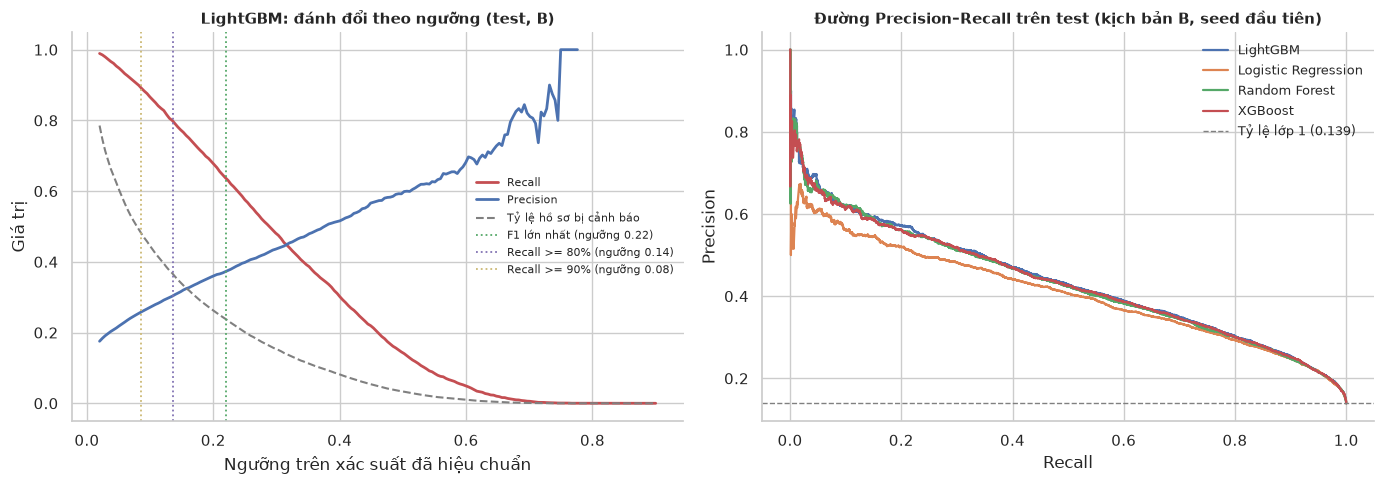

In [36]:
# Biểu đồ: đánh đổi giữa Recall, Precision và tỷ lệ cảnh báo theo ngưỡng (mô hình chính, test, seed đầu tiên) và các điểm vận hành
d = load_pred(BEST_MODEL)
y_te, p_te = d["y_test"], d["p_best"]
grid = np.linspace(0.02, 0.9, 200)
rec = np.array([(p_te[y_te == 1] >= t).mean() for t in grid])
pre = np.array([(y_te[p_te >= t] == 1).mean() if (p_te >= t).any() else np.nan for t in grid])
alert = np.array([(p_te >= t).mean() for t in grid])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(grid, rec, label="Recall", color="#C44E52", lw=2)
ax.plot(grid, pre, label="Precision", color="#4C72B0", lw=2)
ax.plot(grid, alert, label="Tỷ lệ hồ sơ bị cảnh báo", color="gray", lw=1.5, ls="--")
ts = tp[tp["Seed"] == s0].set_index("Điểm vận hành")["Ngưỡng"]
for op, color in [("F1 lớn nhất", "#55A868"), ("Recall >= 80%", "#8172B3"), ("Recall >= 90%", "#CCB974")]:
    ax.axvline(ts[op], color=color, lw=1.3, ls=":", label=f"{op} (ngưỡng {ts[op]:.2f})")
ax.set_xlabel("Ngưỡng trên xác suất đã hiệu chuẩn"); ax.set_ylabel("Giá trị")
ax.set_title(f"{BEST_MODEL}: đánh đổi theo ngưỡng (test, B)", fontsize=11, fontweight="bold")
ax.legend(frameon=False, fontsize=8)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax = axes[1]
for m in CHOICES:
    dm = load_pred(m)
    pr, rc, _ = precision_recall_curve(dm["y_test"], dm["p_raw"])
    ax.plot(rc, pr, lw=1.6, label=m)
ax.axhline(y_te.mean(), color="gray", ls="--", lw=1, label=f"Tỷ lệ lớp 1 ({y_te.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Đường Precision–Recall trên test (kịch bản B, seed đầu tiên)", fontsize=11, fontweight="bold")
ax.legend(frameon=False, fontsize=9)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / f"2_7_threshold_tradeoff{TAG}.png", dpi=300, bbox_inches="tight")
print("-> Đã lưu biểu đồ:", FIGURES / f"2_7_threshold_tradeoff{TAG}.png")
plt.show()

## 2.8 Phân tích False Negative

Với bài toán sàng lọc, bỏ sót hồ sơ thuộc lớp 1 (FN) là sai sót đáng quan tâm nhất. Mục này xem **ai bị bỏ sót** ở hai điểm vận hành của mô hình chính (test, kịch bản B, seed đầu tiên): tỷ lệ FN theo nhóm đối tượng và khác biệt đặc trưng giữa nhóm FN và nhóm TP. Đây là mô tả kết quả của mô hình trên dữ liệu khảo sát, không phải suy luận nhân quả.

In [37]:
split_b = U.get_split("profile", s0, CFG.get("max_train_rows"))
X_te, y_te_s, _ = split_b["test"]
assert (y_te_s.to_numpy() == d["y_test"]).all()
age_grp = pd.cut(X_te["Age"], [0, 4, 8, 13], labels=["18-39", "40-59", "60+"])
bmi_grp = pd.cut(X_te["BMI"], [0, 25, 30, 35, 200], right=False, labels=["<25", "25-29.9", "30-34.9", ">=35"])
inc_grp = pd.cut(X_te["Income"], [0, 3, 6, 8], labels=["thấp (1-3)", "trung bình (4-6)", "cao (7-8)"])
groups = {"Tuổi": age_grp, "BMI": bmi_grp, "Thu nhập": inc_grp, "Giới tính": X_te["Sex"].map({0: "Nữ", 1: "Nam"}),
          "Huyết áp cao": X_te["HighBP"].map({0: "Không", 1: "Có"}), "Sức khỏe tự đánh giá": pd.cut(X_te["GenHlth"], [0, 2, 3, 5], labels=["tốt (1-2)", "trung bình (3)", "kém (4-5)"]),
          "Vận động": X_te["PhysActivity"].map({0: "Không", 1: "Có"})}
fn_rows, ops_fn = [], ["Recall >= 80%", "F1 lớn nhất"]
for op in ops_fn:
    thr = ts[op]
    pred = p_te >= thr
    for gname, g in groups.items():
        for lv in g.cat.categories if hasattr(g, "cat") else sorted(g.dropna().unique()):
            m = (g == lv).to_numpy() & (y_te == 1)
            if m.sum() == 0:
                continue
            fn = int((~pred[m]).sum())
            fn_rows.append({"Điểm vận hành": op, "Nhóm": gname, "Mức": str(lv), "Số hồ sơ lớp 1": int(m.sum()), "FN": fn, "Tỷ lệ FN (%)": round(100 * fn / m.sum(), 1),
                            "Recall (%)": round(100 * (1 - fn / m.sum()), 1)})
fn_table = pd.DataFrame(fn_rows)
display(fn_table[fn_table["Điểm vận hành"] == "Recall >= 80%"])
U.save_table(fn_table, f"2_8_false_negative_by_subgroup{TAG}")

# Đặc trưng trung bình: FN so với TP (cùng là hồ sơ lớp 1)
thr = ts["Recall >= 80%"]
pred = p_te >= thr
fn_mask, tp_mask = (y_te == 1) & ~pred, (y_te == 1) & pred
cmp_feat = pd.DataFrame({"Đặc trưng": U.FEATURES_21, "TB nhóm FN": X_te[fn_mask].mean().to_numpy(), "TB nhóm TP": X_te[tp_mask].mean().to_numpy(),
                         "TB nhóm TN": X_te[(y_te == 0) & ~pred].mean().to_numpy()}).round(3)
cmp_feat["FN - TP"] = (cmp_feat["TB nhóm FN"] - cmp_feat["TB nhóm TP"]).round(3)
print(f"Số FN = {int(fn_mask.sum())}, số TP = {int(tp_mask.sum())} tại ngưỡng Recall >= 80% ({thr:.3f})")
display(cmp_feat.reindex(cmp_feat["FN - TP"].abs().sort_values(ascending=False).index))
U.save_table(cmp_feat, f"2_8_false_negative_feature_means{TAG}")

,Điểm vận hành,Nhóm,Mức,Số hồ sơ lớp 1,FN,Tỷ lệ FN (%),Recall (%)
0,Recall >= 80%,Tuổi,18-39,165,114,69.1,30.9
1,Recall >= 80%,Tuổi,40-59,1529,440,28.8,71.2
2,Recall >= 80%,Tuổi,60+,3609,510,14.1,85.9
3,Recall >= 80%,BMI,<25,629,323,51.4,48.6
4,Recall >= 80%,BMI,25-29.9,1608,453,28.2,71.8
5,Recall >= 80%,BMI,30-34.9,1521,198,13.0,87.0
6,Recall >= 80%,BMI,>=35,1545,90,5.8,94.2
7,Recall >= 80%,Thu nhập,thấp (1-3),1330,131,9.8,90.2
8,Recall >= 80%,Thu nhập,trung bình (4-6),2066,339,16.4,83.6
9,Recall >= 80%,Thu nhập,cao (7-8),1907,594,31.1,68.9


-> Đã lưu bảng: D:\CK\results\tables\2_8_false_negative_by_subgroup.csv
Số FN = 1064, số TP = 4239 tại ngưỡng Recall >= 80% (0.136)


,Đặc trưng,TB nhóm FN,TB nhóm TP,TB nhóm TN,FN - TP
15,PhysHlth,3.367,9.033,2.094,-5.666
3,BMI,27.438,33.019,26.404,-5.581
14,MentHlth,2.594,4.728,2.538,-2.134
18,Age,8.250,9.692,7.014,-1.442
20,Income,6.234,5.008,6.567,1.226
13,GenHlth,2.413,3.504,2.031,-1.091
0,HighBP,0.378,0.846,0.210,-0.468
19,Education,5.102,4.657,5.248,0.445
16,DiffWalk,0.105,0.435,0.051,-0.330
1,HighChol,0.405,0.733,0.270,-0.328


-> Đã lưu bảng: D:\CK\results\tables\2_8_false_negative_feature_means.csv


WindowsPath('D:/CK/results/tables/2_8_false_negative_feature_means.csv')

-> Đã lưu biểu đồ: D:\CK\results\figures\2_8_false_negative_by_subgroup.png


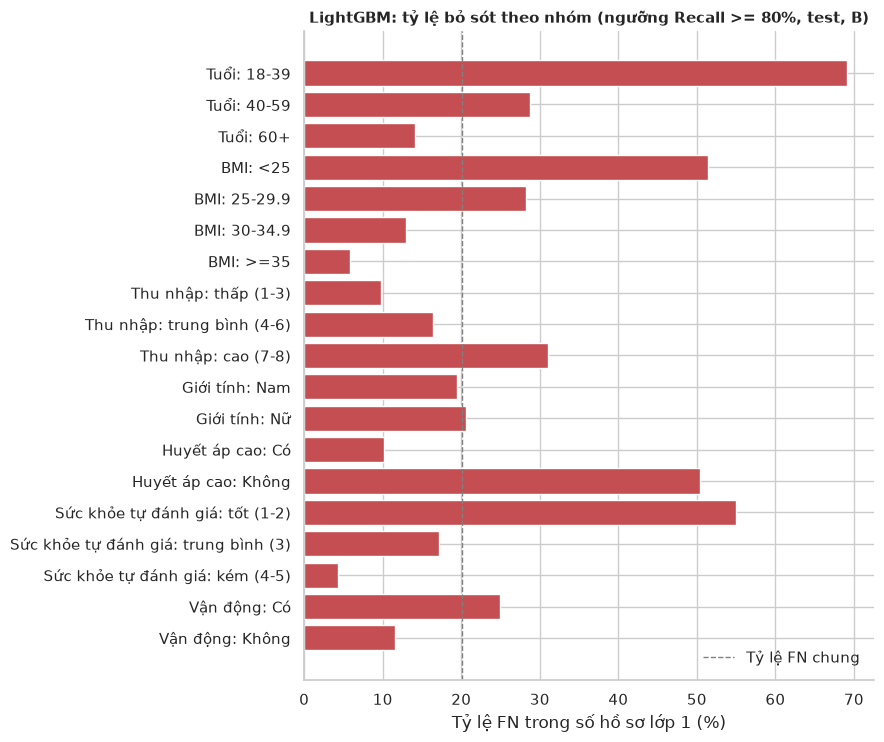

In [38]:
# Biểu đồ: tỷ lệ FN theo nhóm (điểm vận hành Recall >= 80%)
sub = fn_table[fn_table["Điểm vận hành"] == "Recall >= 80%"].copy()
sub["Nhãn"] = sub["Nhóm"] + ": " + sub["Mức"]
sub = sub.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(sub) + 1.5))
ax.barh(sub["Nhãn"], sub["Tỷ lệ FN (%)"], color="#C44E52")
ax.axvline(100 * fn_mask.sum() / (y_te == 1).sum(), color="gray", ls="--", lw=1, label="Tỷ lệ FN chung")
ax.set_xlabel("Tỷ lệ FN trong số hồ sơ lớp 1 (%)")
ax.set_title(f"{BEST_MODEL}: tỷ lệ bỏ sót theo nhóm (ngưỡng Recall >= 80%, test, B)", fontsize=11, fontweight="bold")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / f"2_8_false_negative_by_subgroup{TAG}.png", dpi=300, bbox_inches="tight")
print("-> Đã lưu biểu đồ:", FIGURES / f"2_8_false_negative_by_subgroup{TAG}.png")
plt.show()

## 2.9 Thí nghiệm bỏ dần các đặc trưng yếu (đề xuất rút gọn, không thay đổi mô hình chính)

Cô yêu cầu dùng đủ 21 đặc trưng đầu vào, nên **mô hình chính giữ nguyên 21 biến**. Mục này kiểm tra xem bỏ một số biến ít ảnh hưởng (ví dụ Education) có làm giảm chất lượng hay không, để nhóm có bằng chứng trao đổi với cô về bản rút gọn (ứng dụng ít câu hỏi hơn).

Cách làm (chỉ dùng train và validation):
1. Xếp hạng đặc trưng bằng **permutation importance** (độ giảm PR-AUC khi xáo trộn một biến) của mô hình chính trên **validation** của seed đầu tiên.
2. Huấn luyện lại mô hình chính (cùng siêu tham số và chiến lược) sau khi bỏ dần 1, 2, 3, 5, 8, 10 biến yếu nhất, cùng hai phương án cụ thể: bỏ Education; bỏ Education và Income.
3. So sánh PR-AUC, ROC-AUC, Brier và Precision tại Recall ≈ 80% trên validation qua tất cả seed, kèm chênh lệch ghép cặp so với bản đủ 21 biến.

Lưu ý khi đọc kết quả:
- Permutation importance có thể đánh giá thấp các biến tương quan mạnh với nhau (ví dụ HighBP, HighChol, GenHlth, DiffWalk), nên thứ hạng chỉ là gợi ý; kết luận dựa trên **kết quả huấn luyện lại** ở bước 2.
- Thứ hạng và kết quả cùng dùng validation, nên bảng này **chỉ để tham khảo**, không dùng để chọn lại cấu hình bằng test.
- Education và Income có thể ít đóng góp cho dự đoán nhưng vẫn cần cho việc so sánh các nhóm kinh tế – xã hội ở phần giải thích (SHAP) ở Giai đoạn 3. Đây là lý do cân nhắc trước khi bỏ.
- Các biến có thể can thiệp (BMI, vận động, ăn rau quả) cần giữ cho chức năng What-if ở Giai đoạn 3, dù đóng góp dự đoán nhỏ.

In [39]:
t0 = time.time()
imp_table, abl_runs, abl_variants = U.run_feature_ablation(
    BEST_MODEL, CHOICES[BEST_MODEL], PARAMS.get(BEST_MODEL), CFG,
    extra_sets={"Bỏ Education": ["Education"], "Bỏ Education và Income": ["Education", "Income"]})
print(f"Thời gian: {time.time() - t0:.0f}s")
display(imp_table)
U.save_table(imp_table.round(5), f"2_9_permutation_importance{TAG}")
U.save_table(abl_runs.round(5), f"2_9_feature_ablation_runs{TAG}")

   seed 42: xong 9 phương án
   seed 43: xong 9 phương án
   seed 44: xong 9 phương án
   seed 45: xong 9 phương án
   seed 46: xong 9 phương án
Thời gian: 61s


,Đặc trưng,Giảm PR-AUC khi xáo trộn
0,BMI,0.080208
1,GenHlth,0.074830
2,Age,0.035840
3,HighBP,0.031342
4,HighChol,0.026637
5,HvyAlcoholConsump,0.006841
6,Sex,0.004879
7,Income,0.004810
8,HeartDiseaseorAttack,0.004591
9,CholCheck,0.004282


-> Đã lưu bảng: D:\CK\results\tables\2_9_permutation_importance.csv
-> Đã lưu bảng: D:\CK\results\tables\2_9_feature_ablation_runs.csv


WindowsPath('D:/CK/results/tables/2_9_feature_ablation_runs.csv')

,Phương án,Biến bỏ,Số seed,ROC-AUC,PR-AUC,Brier,Precision @Recall80
0,Đủ 21 biến,-,5,0.8308 ± 0.0031 [0.8271; 0.8346],0.4344 ± 0.0059 [0.4270; 0.4418],0.0965 ± 0.0006 [0.0957; 0.0973],0.3072 ± 0.0030 [0.3034; 0.3109]
1,Bỏ 1 biến yếu nhất,Stroke,5,0.8307 ± 0.0030 [0.8269; 0.8344],0.4345 ± 0.0055 [0.4276; 0.4413],0.0965 ± 0.0006 [0.0958; 0.0972],0.3061 ± 0.0041 [0.3010; 0.3111]
2,Bỏ 2 biến yếu nhất,"Stroke, PhysHlth",5,0.8305 ± 0.0029 [0.8269; 0.8341],0.4340 ± 0.0051 [0.4276; 0.4403],0.0965 ± 0.0006 [0.0958; 0.0973],0.3066 ± 0.0030 [0.3029; 0.3103]
3,Bỏ 3 biến yếu nhất,"Stroke, PhysHlth, Veggies",5,0.8306 ± 0.0031 [0.8267; 0.8345],0.4344 ± 0.0050 [0.4282; 0.4406],0.0965 ± 0.0006 [0.0957; 0.0973],0.3057 ± 0.0032 [0.3017; 0.3096]
4,Bỏ 5 biến yếu nhất,"Stroke, PhysHlth, Veggies, Smoker, PhysActivity",5,0.8304 ± 0.0031 [0.8265; 0.8343],0.4337 ± 0.0055 [0.4269; 0.4405],0.0966 ± 0.0006 [0.0958; 0.0973],0.3061 ± 0.0036 [0.3016; 0.3106]
5,Bỏ 8 biến yếu nhất,"Stroke, PhysHlth, Veggies, Smoker, PhysActivit...",5,0.8304 ± 0.0031 [0.8266; 0.8342],0.4340 ± 0.0055 [0.4273; 0.4408],0.0966 ± 0.0006 [0.0958; 0.0973],0.3062 ± 0.0032 [0.3021; 0.3102]
6,Bỏ 10 biến yếu nhất,"Stroke, PhysHlth, Veggies, Smoker, PhysActivit...",5,0.8297 ± 0.0032 [0.8257; 0.8337],0.4318 ± 0.0055 [0.4249; 0.4387],0.0967 ± 0.0006 [0.0959; 0.0975],0.3056 ± 0.0024 [0.3026; 0.3086]
7,Bỏ Education,Education,5,0.8307 ± 0.0029 [0.8270; 0.8343],0.4340 ± 0.0057 [0.4269; 0.4412],0.0965 ± 0.0006 [0.0958; 0.0973],0.3071 ± 0.0031 [0.3033; 0.3110]
8,Bỏ Education và Income,"Education, Income",5,0.8291 ± 0.0029 [0.8255; 0.8328],0.4321 ± 0.0060 [0.4246; 0.4396],0.0968 ± 0.0006 [0.0960; 0.0975],0.3035 ± 0.0036 [0.2990; 0.3080]


,Phương án,Δ PR-AUC so với đủ 21 biến (TB ± sd),Số seed PR-AUC thấp hơn,Δ Brier (TB),p (t-test ghép cặp)
0,Bỏ 1 biến yếu nhất,+0.0000 ± 0.0007,2/5,+0.00002,0.876618
1,Bỏ 2 biến yếu nhất,-0.0005 ± 0.0014,4/5,+0.00006,0.507734
2,Bỏ 3 biến yếu nhất,-0.0000 ± 0.0013,2/5,+0.00003,0.964407
3,Bỏ 5 biến yếu nhất,-0.0007 ± 0.0007,4/5,+0.00008,0.080228
4,Bỏ 8 biến yếu nhất,-0.0004 ± 0.0009,4/5,+0.00009,0.413245
5,Bỏ 10 biến yếu nhất,-0.0026 ± 0.0008,5/5,+0.00023,0.002134
6,Bỏ Education,-0.0004 ± 0.0006,3/5,+0.00004,0.209950
7,Bỏ Education và Income,-0.0023 ± 0.0004,5/5,+0.00029,0.000174


-> Đã lưu bảng: D:\CK\results\tables\2_9_feature_ablation_summary.csv
-> Đã lưu bảng: D:\CK\results\tables\2_9_feature_ablation_paired_diff.csv
-> Đã lưu biểu đồ: D:\CK\results\figures\2_9_feature_ablation.png


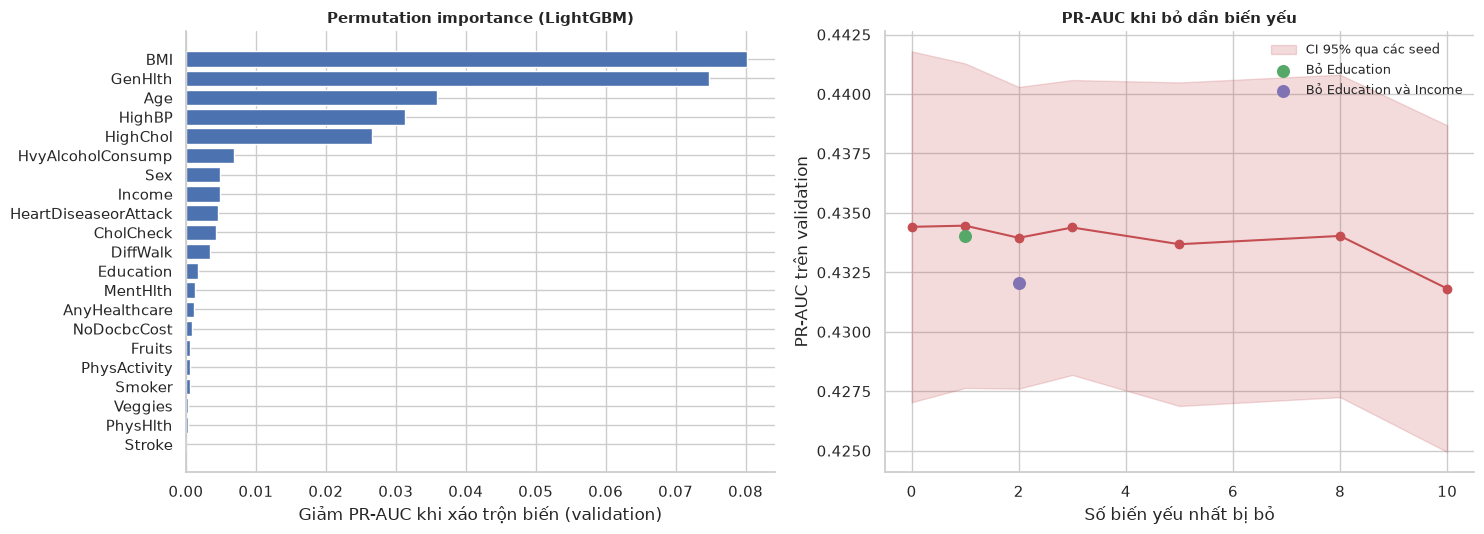

In [40]:
# Tổng hợp: trung bình ± sd [CI 95%] và chênh lệch ghép cặp so với bản đủ 21 biến
abl_cols = ["ROC-AUC", "PR-AUC", "Brier", "Precision @Recall80"]
abl_sum = U.summarize(abl_runs, ["Phương án"], abl_cols)
abl_sum.insert(1, "Biến bỏ", [", ".join(abl_variants[v]) if abl_variants[v] else "-" for v in abl_sum["Phương án"]])
full = abl_runs[abl_runs["Phương án"] == "Đủ 21 biến"].set_index("Seed")
rows = []
for v, g in abl_runs.groupby("Phương án", sort=False):
    if v == "Đủ 21 biến":
        continue
    g = g.set_index("Seed")
    d = (g["PR-AUC"] - full["PR-AUC"]).to_numpy()
    db = (g["Brier"] - full["Brier"]).to_numpy()
    p_val = stats.ttest_rel(g["PR-AUC"], full["PR-AUC"])[1] if len(d) > 1 else np.nan
    rows.append({"Phương án": v, "Δ PR-AUC so với đủ 21 biến (TB ± sd)": f"{d.mean():+.4f} ± {d.std(ddof=1) if len(d) > 1 else 0:.4f}",
                 "Số seed PR-AUC thấp hơn": f"{int((d < 0).sum())}/{len(d)}", "Δ Brier (TB)": f"{db.mean():+.5f}", "p (t-test ghép cặp)": p_val})
abl_diff = pd.DataFrame(rows)
display(abl_sum)
display(abl_diff)
U.save_table(abl_sum, f"2_9_feature_ablation_summary{TAG}")
U.save_table(abl_diff, f"2_9_feature_ablation_paired_diff{TAG}")

# Biểu đồ: độ quan trọng và PR-AUC theo số biến bỏ
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ip = imp_table.iloc[::-1]
ax.barh(ip["Đặc trưng"], ip["Giảm PR-AUC khi xáo trộn"], color="#4C72B0")
ax.set_xlabel("Giảm PR-AUC khi xáo trộn biến (validation)")
ax.set_title(f"Permutation importance ({BEST_MODEL})", fontsize=11, fontweight="bold")
ax = axes[1]
seq = abl_runs[abl_runs["Phương án"].str.startswith(("Đủ", "Bỏ ")) & ~abl_runs["Phương án"].str.contains("Education")]
xs, ms, los, his = [], [], [], []
for k, g in seq.groupby("Số biến bỏ"):
    mu, sd, lo, hi = U.mean_sd_ci(g["PR-AUC"])
    xs.append(k); ms.append(mu); los.append(lo); his.append(hi)
ax.plot(xs, ms, marker="o", color="#C44E52")
ax.fill_between(xs, los, his, color="#C44E52", alpha=0.2, label="CI 95% qua các seed")
for name, color in [("Bỏ Education", "#55A868"), ("Bỏ Education và Income", "#8172B3")]:
    g = abl_runs[abl_runs["Phương án"] == name]
    ax.scatter([g["Số biến bỏ"].iloc[0]], [g["PR-AUC"].mean()], s=70, color=color, zorder=3, label=name)
ax.set_xlabel("Số biến yếu nhất bị bỏ"); ax.set_ylabel("PR-AUC trên validation")
ax.set_title("PR-AUC khi bỏ dần biến yếu", fontsize=11, fontweight="bold")
ax.legend(frameon=False, fontsize=9)
for a in axes:
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / f"2_9_feature_ablation{TAG}.png", dpi=300, bbox_inches="tight")
print("-> Đã lưu biểu đồ:", FIGURES / f"2_9_feature_ablation{TAG}.png")
plt.show()


## 2.10 Tổng hợp và đầu ra cho Giai đoạn 3

In [41]:
best_row = SEL[SEL["Mô hình"] == BEST_MODEL].iloc[0]
rk_b = rk[(rk["Kịch bản"] == SC_LABEL["profile"]) & (rk["Mô hình"] == BEST_MODEL)]
print(f"Mô hình chính: {BEST_MODEL} | chiến lược: {U.STRATEGY_LABEL[best_row['Chiến lược']]}")
print(f"PR-AUC test (B): {U.fmt_ci(rk_b['PR-AUC'])}  | ROC-AUC test (B): {U.fmt_ci(rk_b['ROC-AUC'])}")
print(f"Baseline {BASELINE} PR-AUC test (B): {U.fmt_ci(rk[(rk['Kịch bản'] == SC_LABEL['profile']) & (rk['Mô hình'] == BASELINE)]['PR-AUC'])}")
print("Phương pháp hiệu chuẩn được chọn theo mô hình (seed đầu tiên):",
      T[(T['Kịch bản'] == 'profile') & (T['Seed'] == s0)].groupby('Mô hình')['Hiệu chuẩn'].first().to_dict())
print("\nĐầu ra: bảng trong results/tables, biểu đồ trong results/figures, xác suất dự đoán trong results/predictions, mô hình + bộ hiệu chuẩn + ngưỡng trong models/*_bundle.joblib")

Mô hình chính: LightGBM | chiến lược: Không cân bằng
PR-AUC test (B): 0.4379 ± 0.0049 [0.4317; 0.4440]  | ROC-AUC test (B): 0.8310 ± 0.0022 [0.8283; 0.8338]
Baseline Logistic Regression PR-AUC test (B): 0.4097 ± 0.0067 [0.4014; 0.4180]
Phương pháp hiệu chuẩn được chọn theo mô hình (seed đầu tiên): {'LightGBM': 'none', 'Logistic Regression': 'isotonic', 'Random Forest': 'sigmoid', 'XGBoost': 'sigmoid'}

Đầu ra: bảng trong results/tables, biểu đồ trong results/figures, xác suất dự đoán trong results/predictions, mô hình + bộ hiệu chuẩn + ngưỡng trong models/*_bundle.joblib


### Nhận xét của nhóm (điền sau khi chạy bản đầy đủ)

- **Mô hình nào tốt nhất và chênh lệch so với baseline có ý nghĩa thống kê không?** (xem 2.4–2.5; dẫn số PR-AUC, khoảng tin cậy, p-value đã hiệu chỉnh)
- **Chiến lược mất cân bằng nào hiệu quả?** (2.2: class_weight/SMOTENC có cải thiện PR-AUC hay chỉ làm xác suất bị thổi phồng?)
- **Hiệu chuẩn:** phương pháp nào giảm Brier/ECE trên test? (2.6)
- **Ngưỡng:** điểm vận hành nào phù hợp cho sàng lọc, đánh đổi Recall – số cảnh báo sai ra sao? Lưu ý các tỷ lệ chi phí chỉ là giả định độ nhạy. (2.7)
- **False Negative:** nhóm nào bị bỏ sót nhiều hơn mức chung? (2.8)
- **Hạn chế:** dữ liệu khảo sát tự báo cáo năm 2015, nhãn gộp tiền tiểu đường và tiểu đường, kịch bản B không đồng nghĩa triển khai trên người mới, mới tinh chỉnh một lần cho mỗi mô hình.

# GIAI ĐOẠN 3: HỆ HỖ TRỢ QUYẾT ĐỊNH SÀNG LỌC NGUY CƠ (DECISION SUPPORT) VÀ GIẢI THÍCH MÔ HÌNH (XAI)

> **Học phần**: INS305 – Hệ hỗ trợ quyết định · **Đề tài**: Hệ hỗ trợ quyết định đánh giá nguy cơ tiền tiểu đường và tiểu đường dựa trên học máy và dữ liệu khảo sát sức khỏe (CDC BRFSS 2015)

**Cách đọc Giai đoạn 3.** Mô hình học máy chỉ cung cấp *xác suất*. Hệ thống biến xác suất thành *quyết định hỗ trợ* qua các thành phần tách biệt: phân mức nguy cơ → bộ quy tắc → phân tích phương án (ngưỡng, Top-k, What-if) → giải thích (SHAP).

**Nguyên tắc.**
1. Từ Giai đoạn 3, **không dùng test để chọn lại mô hình, hiệu chuẩn hay ngưỡng**. Mọi lựa chọn thiết kế được quyết định bằng *validation*; test chỉ để báo cáo cuối.
2. Mỗi seed có một mô hình riêng huấn luyện trên train của seed đó (không đánh giá mô hình của seed này trên test của seed khác).
3. Nhãn là thông tin **tự khai** về tiền sử được chẩn đoán; hệ thống **không chẩn đoán** và không thay thế nhân viên y tế.
4. Các giới hạn năng lực xử lý (100/200/300 hồ sơ trên 1.000 người) và tỉ lệ chi phí FN:FP là **kịch bản giả định**.
5. Các số liệu trong phần chữ được in tự động từ bảng kết quả; không gõ tay.

## 3.0 Kiến trúc, chốt cấu hình mô hình và hiệu chuẩn

Sơ đồ kiến trúc nêu đầu vào, đầu ra và nhiệm vụ của từng thành phần. Cấu hình LightGBM (siêu tham số, chiến lược mất cân bằng) lấy từ `models/LightGBM_bundle.joblib` của Giai đoạn 2.
Hiệu chuẩn được chọn bằng **quy tắc đặt trước trên validation**: chỉ dùng Platt hoặc Isotonic nếu chúng giảm Brier ở **mọi** seed và mức giảm trung bình ≥ 0,0001; ngược lại giữ xác suất chưa hiệu chuẩn (đơn giản hơn). Hệ thống triển khai dùng đúng cấu hình này.

-> Đã lưu biểu đồ: D:\CK\results\figures\3_0_architecture.png


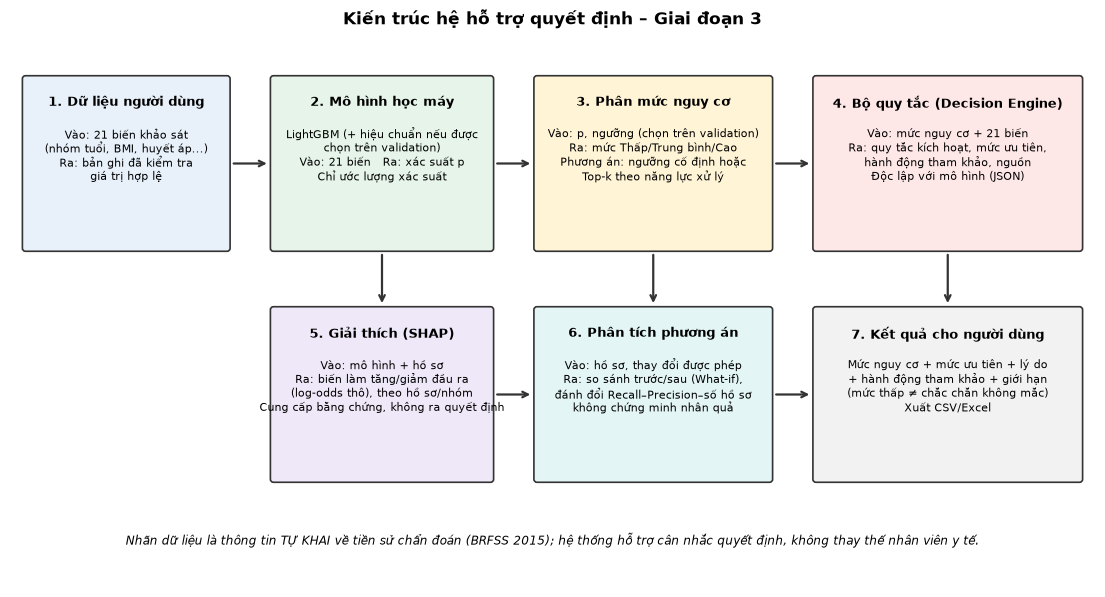

Cấu hình LightGBM từ Giai đoạn 2 – chiến lược mất cân bằng: Không cân bằng
Siêu tham số: {'colsample_bytree': 0.8058265802441404, 'learning_rate': 0.020328077177382428, 'min_child_samples': 108, 'n_estimators': 198, 'num_leaves': 105, 'reg_lambda': 4.777437867054348, 'subsample': 0.6557975442608167}

Huấn luyện/nạp LightGBM cho 5 seed (mỗi seed một mô hình riêng; kết quả được lưu trong results/phase3):
-> Kiểm tra cộng tính SHAP: sai số lớn nhất 2.05e-14 (log-odds)


2.0451088739159573e-14

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import dss_utils as U
import dss_stage3 as S3

S3.plot_architecture(); plt.show()
CFG2 = S3.phase2_config()
print("Cấu hình LightGBM từ Giai đoạn 2 – chiến lược mất cân bằng:", U.STRATEGY_LABEL[CFG2["strategy"]])
print("Siêu tham số:", CFG2["params"])
print("\nHuấn luyện/nạp LightGBM cho 5 seed (mỗi seed một mô hình riêng; kết quả được lưu trong results/phase3):")
RUNS = S3.fit_all(CFG2)
S3.check_additivity(RUNS[0]["model"], RUNS[0]["X_test"])

In [3]:
cal_detail, cal_summary, CALIBRATION, CAL_WHY = S3.calibration_comparison(RUNS)
display(cal_summary)
print("\n>>> Cấu hình hiệu chuẩn được chốt:", U.CAL_LABEL[CALIBRATION], "|", CAL_WHY)
FINS = [S3.finalize(r, CALIBRATION) for r in RUNS]          # ngưỡng chỉ học trên validation
FIN = FINS[0]                                              # seed 42: mô hình triển khai

-> Đã lưu bảng: D:\CK\results\tables\3_0_calibration_validation_by_seed.csv
-> Đã lưu bảng: D:\CK\results\tables\3_0_calibration_validation_summary.csv


,Hiệu chuẩn,Số seed,Brier,Log Loss,ECE,PR-AUC
0,Chưa hiệu chuẩn,5,0.0965 ± 0.0006 [0.0957; 0.0973],0.3119 ± 0.0020 [0.3094; 0.3144],0.0063 ± 0.0007 [0.0054; 0.0071],0.4344 ± 0.0059 [0.4270; 0.4418]
1,Platt (sigmoid),5,0.0965 ± 0.0006 [0.0957; 0.0973],0.3116 ± 0.0021 [0.3090; 0.3143],0.0054 ± 0.0013 [0.0037; 0.0070],0.4343 ± 0.0060 [0.4269; 0.4418]
2,Isotonic,5,0.0965 ± 0.0007 [0.0957; 0.0974],0.3121 ± 0.0023 [0.3092; 0.3149],0.0016 ± 0.0005 [0.0010; 0.0022],0.4282 ± 0.0066 [0.4200; 0.4364]



>>> Cấu hình hiệu chuẩn được chốt: Chưa hiệu chuẩn | Không phương pháp nào giảm Brier ở mọi seed với mức giảm đủ lớn → giữ xác suất chưa hiệu chuẩn (đơn giản hơn).


## 3.1 So sánh điểm vận hành và phân mức nguy cơ 3 tầng

Các điểm vận hành (ngưỡng học trên validation): ngưỡng mặc định 0,5, F1 lớn nhất, Recall ≥ 80%, Recall ≥ 90%, chi phí giả định FN:FP = 2:1, 5:1, 10:1. Bảng báo cáo Recall, Precision, F1, FN, FP, số cảnh báo và số hồ sơ cần xử lý **trên 1.000 người** (test, trung bình ± độ lệch chuẩn [CI 95%] qua 5 seed).

In [4]:
op_detail, op_summary = S3.operating_table(FINS)
display(op_summary)

-> Đã lưu bảng: D:\CK\results\tables\3_1_operating_points_by_seed.csv
-> Đã lưu bảng: D:\CK\results\tables\3_1_operating_points_summary.csv


,Điểm vận hành,Số seed,Ngưỡng,Recall,Precision,F1,FN / 1.000,FP / 1.000,Cảnh báo / 1.000
0,"Ngưỡng mặc định 0,5",5,0.500 ± 0.000 [0.500; 0.500],0.144 ± 0.004 [0.138; 0.149],0.595 ± 0.009 [0.584; 0.606],0.232 ± 0.006 [0.224; 0.239],119.391 ± 0.630 [118.609; 120.173],13.621 ± 0.266 [13.291; 13.951],33.658 ± 0.679 [32.814; 34.501]
1,F1 lớn nhất,5,0.238 ± 0.012 [0.222; 0.253],0.605 ± 0.022 [0.577; 0.632],0.389 ± 0.012 [0.374; 0.405],0.473 ± 0.003 [0.469; 0.477],55.129 ± 3.162 [51.203; 59.056],132.694 ± 11.593 [118.299; 147.089],216.993 ± 14.535 [198.945; 235.041]
2,Recall >= 80%,5,0.137 ± 0.002 [0.134; 0.140],0.800 ± 0.010 [0.788; 0.812],0.306 ± 0.002 [0.303; 0.309],0.443 ± 0.003 [0.439; 0.446],27.866 ± 1.357 [26.181; 29.552],253.198 ± 4.818 [247.215; 259.181],364.760 ± 6.176 [357.091; 372.428]
3,Recall >= 90%,5,0.085 ± 0.003 [0.081; 0.088],0.897 ± 0.008 [0.887; 0.907],0.258 ± 0.004 [0.253; 0.262],0.400 ± 0.004 [0.396; 0.405],14.325 ± 1.119 [12.935; 15.714],360.369 ± 10.005 [347.946; 372.792],485.473 ± 11.206 [471.559; 499.386]
4,Chi phí FN:FP = 2:1,5,0.325 ± 0.024 [0.295; 0.355],0.434 ± 0.043 [0.381; 0.487],0.458 ± 0.019 [0.434; 0.481],0.444 ± 0.015 [0.425; 0.463],78.884 ± 5.977 [71.463; 86.306],72.314 ± 12.057 [57.344; 87.285],132.858 ± 18.012 [110.493; 155.224]
5,Chi phí FN:FP = 5:1,5,0.159 ± 0.013 [0.143; 0.176],0.754 ± 0.027 [0.721; 0.788],0.325 ± 0.011 [0.311; 0.339],0.454 ± 0.007 [0.446; 0.462],34.260 ± 3.748 [29.606; 38.914],219.125 ± 19.077 [195.438; 242.812],324.293 ± 22.910 [295.847; 352.740]
6,Chi phí FN:FP = 10:1,5,0.090 ± 0.004 [0.085; 0.094],0.889 ± 0.005 [0.882; 0.895],0.262 ± 0.004 [0.258; 0.267],0.405 ± 0.004 [0.400; 0.410],15.534 ± 0.722 [14.638; 16.431],348.775 ± 8.610 [338.084; 359.465],472.668 ± 9.462 [460.920; 484.417]


**Phân mức 3 tầng.** Hai sơ đồ ứng viên, đều xây từ các ngưỡng đã có ở Giai đoạn 2: **A** (Thấp < ngưỡng Recall ≥ 80% ≤ Trung bình < ngưỡng F1 lớn nhất ≤ Cao) và **B** (Thấp < ngưỡng Recall ≥ 90% ≤ Trung bình < ngưỡng Recall ≥ 80% ≤ Cao).
Sơ đồ được *chọn trên validation*; test chỉ để báo cáo. Sơ đồ A được chọn làm mặc định vì mục tiêu sàng lọc là Recall khoảng 80% với số hồ sơ cảnh báo vừa phải; sơ đồ B nhạy hơn nhưng đẩy khoảng một nửa dân số lên tầng Trung bình/Cao (xem bảng validation). Người dùng có thể đổi `SCHEME` theo nguồn lực.

-> Đã lưu bảng: D:\CK\results\tables\3_1_tiers_validation_summary.csv
=== Validation (dùng để CHỌN sơ đồ phân mức) ===


,Sơ đồ,Tầng,Số seed,Tỷ lệ dân số (%),Tỷ lệ lớp 1 trong tầng (%),Tỷ lệ ca bệnh được bắt (%)
0,A (Recall ≥ 80% → F1 lớn nhất),Thấp,5,63.74 ± 0.36 [63.30; 64.19],4.37 ± 0.03 [4.33; 4.40],19.99 ± 0.01 [19.99; 20.00]
1,A (Recall ≥ 80% → F1 lớn nhất),Trung bình,5,14.77 ± 1.54 [12.85; 16.69],18.61 ± 0.56 [17.91; 19.31],19.79 ± 2.60 [16.56; 23.02]
2,A (Recall ≥ 80% → F1 lớn nhất),Cao,5,21.49 ± 1.53 [19.59; 23.39],39.08 ± 1.29 [37.47; 40.68],60.22 ± 2.60 [56.99; 63.45]
3,B (Recall ≥ 90% → Recall ≥ 80%),Thấp,5,51.55 ± 0.60 [50.81; 52.29],2.70 ± 0.03 [2.66; 2.74],9.99 ± 0.01 [9.98; 10.00]
4,B (Recall ≥ 90% → Recall ≥ 80%),Trung bình,5,12.19 ± 0.51 [11.56; 12.82],11.44 ± 0.46 [10.87; 12.01],10.00 ± 0.01 [10.00; 10.01]
5,B (Recall ≥ 90% → Recall ≥ 80%),Cao,5,36.26 ± 0.36 [35.81; 36.70],30.72 ± 0.30 [30.34; 31.09],80.01 ± 0.01 [80.00; 80.01]


-> Đã lưu bảng: D:\CK\results\tables\3_1_tiers_test_summary.csv

=== Test (báo cáo cuối) ===


,Sơ đồ,Tầng,Số seed,Tỷ lệ dân số (%),Tỷ lệ lớp 1 trong tầng (%),Tỷ lệ ca bệnh được bắt (%)
0,A (Recall ≥ 80% → F1 lớn nhất),Thấp,5,63.52 ± 0.62 [62.76; 64.29],4.39 ± 0.18 [4.16; 4.61],19.99 ± 0.99 [18.76; 21.22]
1,A (Recall ≥ 80% → F1 lớn nhất),Trung bình,5,14.78 ± 1.78 [12.57; 16.98],18.40 ± 0.60 [17.65; 19.15],19.55 ± 2.88 [15.97; 23.13]
2,A (Recall ≥ 80% → F1 lớn nhất),Cao,5,21.70 ± 1.45 [19.89; 23.50],38.91 ± 1.25 [37.36; 40.47],60.46 ± 2.21 [57.72; 63.21]
3,B (Recall ≥ 90% → Recall ≥ 80%),Thấp,5,51.45 ± 1.12 [50.06; 52.84],2.78 ± 0.17 [2.57; 2.99],10.27 ± 0.81 [9.27; 11.28]
4,B (Recall ≥ 90% → Recall ≥ 80%),Trung bình,5,12.07 ± 0.63 [11.28; 12.86],11.24 ± 0.66 [10.42; 12.05],9.71 ± 0.49 [9.11; 10.32]
5,B (Recall ≥ 90% → Recall ≥ 80%),Cao,5,36.48 ± 0.62 [35.71; 37.24],30.59 ± 0.21 [30.32; 30.85],80.01 ± 0.99 [78.78; 81.24]


-> Đã lưu biểu đồ: D:\CK\results\figures\3_1_tier_distribution.png


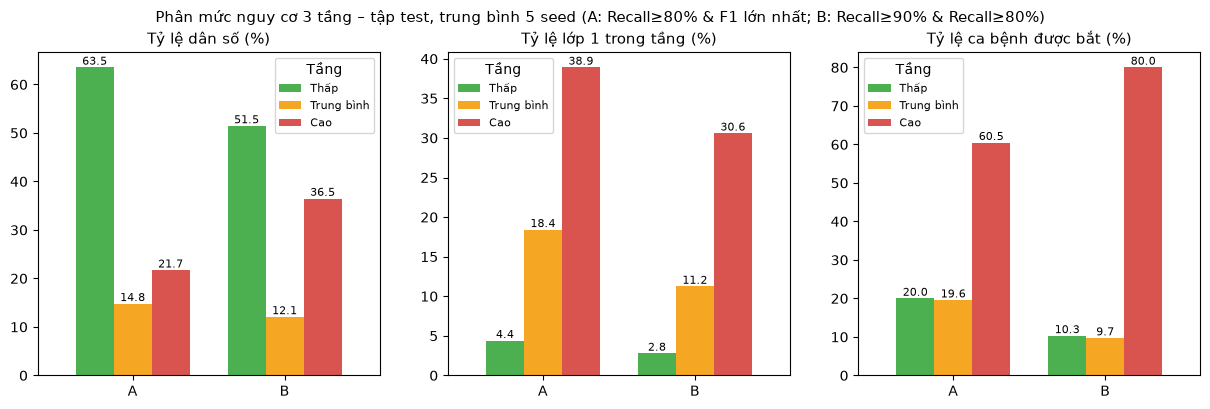

Sơ đồ A (Recall ≥ 80% → F1 lớn nhất) – tầng Cao chiếm 21.70 ± 1.45 [19.89; 23.50] % dân số, bắt 60.46 ± 2.21 [57.72; 63.21] % ca bệnh; tầng Thấp vẫn chứa 19.99 ± 0.99 [18.76; 21.22] % ca bệnh (không có nghĩa là không mắc bệnh).


In [5]:
_, tier_val = S3.tier_evaluation(FINS, "validation")
print("=== Validation (dùng để CHỌN sơ đồ phân mức) ===");  display(tier_val)
SCHEME = "A (Recall ≥ 80% → F1 lớn nhất)"
tier_test_detail, tier_test = S3.tier_evaluation(FINS, "test")
print("\n=== Test (báo cáo cuối) ==="); display(tier_test)
S3.plot_tiers(tier_test_detail); plt.show()
a = tier_test[tier_test["Sơ đồ"] == SCHEME].set_index("Tầng")
print("Sơ đồ", SCHEME, "– tầng Cao chiếm", a.loc["Cao", "Tỷ lệ dân số (%)"], "% dân số, bắt", a.loc["Cao", "Tỷ lệ ca bệnh được bắt (%)"], "% ca bệnh;",
      "tầng Thấp vẫn chứa", a.loc["Thấp", "Tỷ lệ ca bệnh được bắt (%)"], "% ca bệnh (không có nghĩa là không mắc bệnh).")

## 3.2 Lựa chọn theo năng lực xử lý: Top-k so với ngưỡng cố định

Nếu đơn vị chỉ tiếp nhận được *k* hồ sơ trên 1.000 người (kịch bản giả định 100/200/300/400), hệ thống xếp hạng theo xác suất và chọn Top-k. Bảng so sánh với ngưỡng cố định bằng Precision@k, Recall@k, số FN còn lại và số hồ sơ phải xử lý. Điểm khác biệt chính: ngưỡng cố định cho khối lượng công việc *thay đổi* theo tập dữ liệu (độ lệch chuẩn của "Hồ sơ xử lý / 1.000"), còn Top-k cho khối lượng *cố định*, với Recall tương đương khi cùng số cảnh báo.

-> Đã lưu bảng: D:\CK\results\tables\3_2_topk_vs_threshold.csv


,Phương án,Số seed,Hồ sơ xử lý / 1.000,Precision@k,Recall@k,FN còn lại / 1.000,FP / 1.000
0,Top-k: 100/1.000,5,100.001 ± 0.009 [99.989; 100.012],0.492 ± 0.003 [0.488; 0.496],0.353 ± 0.002 [0.350; 0.355],90.245 ± 0.333 [89.832; 90.658],50.818 ± 0.318 [50.423; 51.213]
1,Top-k: 200/1.000,5,200.001 ± 0.009 [199.990; 200.012],0.402 ± 0.002 [0.399; 0.404],0.576 ± 0.003 [0.573; 0.579],59.091 ± 0.424 [58.564; 59.617],119.664 ± 0.375 [119.198; 120.129]
2,Top-k: 300/1.000,5,300.002 ± 0.005 [299.995; 300.008],0.338 ± 0.002 [0.335; 0.340],0.727 ± 0.004 [0.722; 0.732],38.123 ± 0.574 [37.410; 38.835],198.696 ± 0.581 [197.975; 199.418]
3,Top-k: 400/1.000,5,400.002 ± 0.010 [399.990; 400.014],0.291 ± 0.002 [0.288; 0.293],0.834 ± 0.005 [0.827; 0.840],23.192 ± 0.751 [22.260; 24.125],283.766 ± 0.712 [282.882; 284.651]
4,Ngưỡng cố định: F1 lớn nhất,5,216.993 ± 14.535 [198.945; 235.041],0.389 ± 0.012 [0.374; 0.405],0.605 ± 0.022 [0.577; 0.632],55.129 ± 3.162 [51.203; 59.056],132.694 ± 11.593 [118.299; 147.089]
5,Top-k bằng số cảnh báo TB của 'F1 lớn nhất' (2...,5,216.993 ± 0.007 [216.985; 217.001],0.389 ± 0.003 [0.386; 0.392],0.605 ± 0.004 [0.600; 0.611],55.020 ± 0.599 [54.277; 55.763],132.585 ± 0.604 [131.835; 133.335]
6,Ngưỡng cố định: Recall >= 80%,5,364.760 ± 6.176 [357.091; 372.428],0.306 ± 0.002 [0.303; 0.309],0.800 ± 0.010 [0.788; 0.812],27.866 ± 1.357 [26.181; 29.552],253.198 ± 4.818 [247.215; 259.181]
7,Top-k bằng số cảnh báo TB của 'Recall >= 80%' ...,5,364.761 ± 0.010 [364.749; 364.774],0.306 ± 0.002 [0.303; 0.309],0.800 ± 0.005 [0.794; 0.807],27.820 ± 0.737 [26.905; 28.735],253.153 ± 0.773 [252.193; 254.114]
8,Ngưỡng cố định: Recall >= 90%,5,485.473 ± 11.206 [471.559; 499.386],0.258 ± 0.004 [0.253; 0.262],0.897 ± 0.008 [0.887; 0.907],14.325 ± 1.119 [12.935; 15.714],360.369 ± 10.005 [347.946; 372.792]
9,Top-k bằng số cảnh báo TB của 'Recall >= 90%' ...,5,485.472 ± 0.003 [485.469; 485.475],0.257 ± 0.001 [0.256; 0.259],0.896 ± 0.004 [0.892; 0.901],14.452 ± 0.513 [13.815; 15.089],360.496 ± 0.474 [359.908; 361.084]


-> Đã lưu biểu đồ: D:\CK\results\figures\3_2_topk_vs_threshold.png


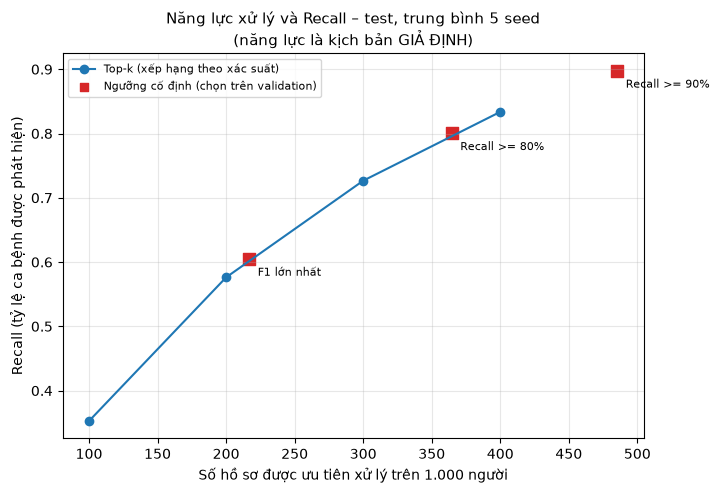

In [6]:
topk_detail, topk_summary = S3.topk_comparison(FINS)
display(topk_summary)
S3.plot_topk(topk_detail); plt.show()

## 3.3 Phân tích bỏ sót (False Negative) theo nhóm đối tượng

Bảng Recall, FNR, Precision, số hồ sơ và số lớp 1 theo nhóm tuổi, BMI, giới tính, thu nhập, tại ba điểm vận hành (Recall ≥ 90%, Recall ≥ 80%, F1 lớn nhất). FNR có khoảng tin cậy Wilson 95%; nhóm có dưới 100 hồ sơ lớp 1 được gắn nhãn "ít mẫu". Mục tiêu không phải nâng Recall cho mọi nhóm bằng mọi giá, mà phát hiện nhóm mô hình hoạt động kém và thể hiện cảnh báo phù hợp (quy tắc R01, R16).

-> Đã lưu bảng: D:\CK\results\tables\3_3_fn_by_group.csv


,Điểm vận hành,Nhóm,Mức,Số hồ sơ,Số lớp 1,Recall,FNR,FNR CI95 dưới,FNR CI95 trên,Precision,Tỷ lệ cảnh báo (%),Ghi chú
0,Recall >= 90%,Nhóm tuổi,60 trở lên,18283,3609,0.938,0.062,0.054,0.070,0.270,68.621,
1,Recall >= 90%,Nhóm tuổi,40–59,13905,1529,0.840,0.160,0.142,0.179,0.239,38.641,
2,Recall >= 90%,Nhóm tuổi,18–39,5888,165,0.442,0.558,0.481,0.631,0.146,8.509,
3,Recall >= 90%,BMI,≥ 30,13076,3066,0.956,0.044,0.038,0.052,0.310,72.285,
4,Recall >= 90%,BMI,"25–29,9",14071,1608,0.853,0.147,0.131,0.166,0.212,45.946,
5,Recall >= 90%,BMI,< 25,10929,629,0.704,0.296,0.261,0.333,0.177,22.902,
6,Recall >= 90%,Giới tính,Nữ,21325,2768,0.884,0.116,0.104,0.128,0.258,44.488,
7,Recall >= 90%,Giới tính,Nam,16751,2535,0.906,0.094,0.084,0.106,0.257,53.328,
8,Recall >= 90%,Thu nhập,Cao (≥ 50.000),20013,1907,0.827,0.173,0.157,0.191,0.225,34.977,
9,Recall >= 90%,Thu nhập,Thấp (< 20.000 USD),5654,1330,0.952,0.048,0.038,0.061,0.306,73.099,


-> Đã lưu biểu đồ: D:\CK\results\figures\3_3_fn_by_group.png


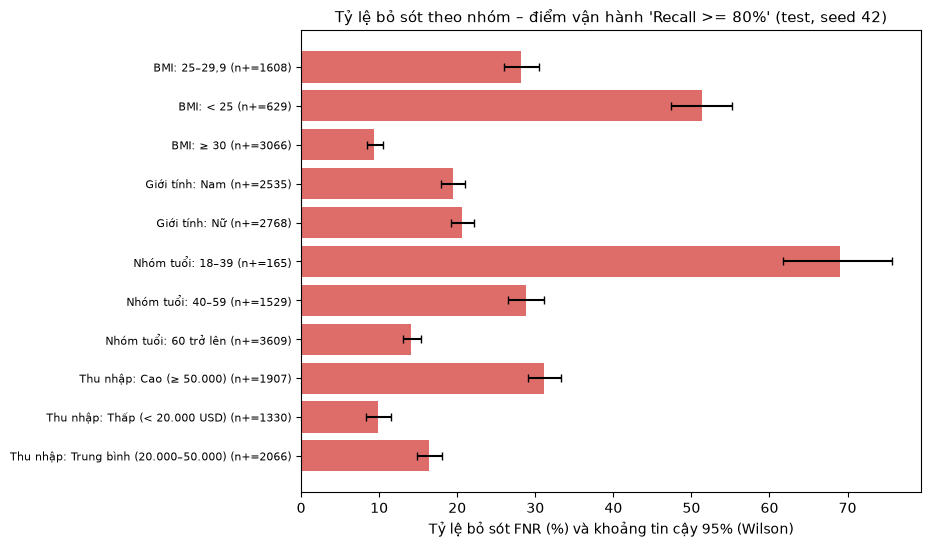

Ba nhóm bị bỏ sót nhiều nhất ở Recall ≥ 80%:
     Nhóm            Mức  Số lớp 1   FNR  FNR CI95 dưới  FNR CI95 trên
Nhóm tuổi          18–39       165 0.691          0.617          0.756
      BMI           < 25       629 0.514          0.474          0.552
 Thu nhập Cao (≥ 50.000)      1907 0.311          0.291          0.333


In [7]:
fn_tab = S3.fn_by_group(FIN)
show = fn_tab[["Điểm vận hành", "Nhóm", "Mức", "Số hồ sơ", "Số lớp 1", "Recall", "FNR", "FNR CI95 dưới", "FNR CI95 trên", "Precision", "Tỷ lệ cảnh báo (%)", "Ghi chú"]]
display(show.round(3))
S3.plot_fn_by_group(fn_tab); plt.show()
w = fn_tab[fn_tab["Điểm vận hành"] == "Recall >= 80%"].sort_values("FNR", ascending=False).head(3)
print("Ba nhóm bị bỏ sót nhiều nhất ở Recall ≥ 80%:"); print(w[["Nhóm", "Mức", "Số lớp 1", "FNR", "FNR CI95 dưới", "FNR CI95 trên"]].round(3).to_string(index=False))

**Ảnh hưởng của việc chọn ngưỡng đến mức bỏ sót giữa các nhóm.** Yêu cầu xem các ngưỡng khác nhau tác động thế nào đến mức bỏ sót giữa các nhóm. Bảng dưới so sánh FNR của cùng một nhóm tại ba ngưỡng (Recall ≥ 90%, Recall ≥ 80%, F1 lớn nhất) và tính chênh lệch/tỉ số giữa nhóm bị bỏ sót nhiều nhất và ít nhất trong từng tiêu chí (tuổi, BMI, giới, thu nhập). Câu hỏi: hạ ngưỡng có thu hẹp khoảng cách giữa các nhóm không, và nhóm nào vẫn bị bỏ sót dù đã hạ ngưỡng?

In [8]:
OPS3 = ["Recall >= 90%", "Recall >= 80%", "F1 lớn nhất"]
piv = fn_tab.pivot_table(index=["Nhóm", "Mức"], columns="Điểm vận hành", values="FNR")[OPS3]
display(piv.round(3))
rows = []
for fam, g in fn_tab.groupby("Nhóm"):
    for op in OPS3:
        v = g.loc[g["Điểm vận hành"] == op, "FNR"]
        rows.append({"Tiêu chí": fam, "Điểm vận hành": op, "FNR thấp nhất": v.min(), "FNR cao nhất": v.max(),
                     "Chênh lệch (cao nhất − thấp nhất)": v.max() - v.min(), "Tỉ số (cao nhất / thấp nhất)": v.max() / v.min()})
fn_gap = S3._save_table(pd.DataFrame(rows), "3_3_fn_gap_by_threshold")
display(fn_gap.round(3))

Điểm vận hành                         Recall >= 90%  Recall >= 80%  \
Nhóm      Mức                                                        
BMI       25–29,9                             0.147          0.282   
          < 25                                0.296          0.514   
          ≥ 30                                0.044          0.094   
Giới tính Nam                                 0.094          0.194   
          Nữ                                  0.116          0.206   
Nhóm tuổi 18–39                               0.558          0.691   
          40–59                               0.160          0.288   
          60 trở lên                          0.062          0.141   
Thu nhập  Cao (≥ 50.000)                      0.173          0.311   
          Thấp (< 20.000 USD)                 0.048          0.098   
          Trung bình (20.000–50.000)          0.080          0.164   

Điểm vận hành                         F1 lớn nhất  
Nhóm      Mức                                      
BMI       25–29,9                           0.502  
          < 25                              0.769  
          ≥ 30                              0.205  
Giới tính Nam                               0.357  
          Nữ                                0.367  
Nhóm tuổi 18–39                             0.836  
          40–59                             0.440  
          60 trở lên                        0.308  
Thu nhập  Cao (≥ 50.000)                    0.501  
          Thấp (< 20.000 USD)               0.208  
          Trung bình (20.000–50.000)        0.333

-> Đã lưu bảng: D:\CK\results\tables\3_3_fn_gap_by_threshold.csv


,Tiêu chí,Điểm vận hành,FNR thấp nhất,FNR cao nhất,Chênh lệch (cao nhất − thấp nhất),Tỉ số (cao nhất / thấp nhất)
0,BMI,Recall >= 90%,0.044,0.296,0.251,6.666
1,BMI,Recall >= 80%,0.094,0.514,0.420,5.467
2,BMI,F1 lớn nhất,0.205,0.769,0.564,3.745
3,Giới tính,Recall >= 90%,0.094,0.116,0.021,1.226
4,Giới tính,Recall >= 80%,0.194,0.206,0.012,1.061
5,Giới tính,F1 lớn nhất,0.357,0.367,0.009,1.026
6,Nhóm tuổi,Recall >= 90%,0.062,0.558,0.496,9.024
7,Nhóm tuổi,Recall >= 80%,0.141,0.691,0.550,4.889
8,Nhóm tuổi,F1 lớn nhất,0.308,0.836,0.529,2.717
9,Thu nhập,Recall >= 90%,0.048,0.173,0.125,3.596


## 3.4 Giải thích mô hình bằng SHAP

SHAP được tính bằng TreeSHAP chính xác của LightGBM (`predict(..., pred_contrib=True)`), nên không cần thư viện `shap`. **Thang đo:** giá trị SHAP nằm trên thang **log-odds của đầu ra thô** của mô hình (trước hiệu chuẩn). Tổng SHAP + giá trị nền = log-odds thô; xác suất hiển thị ở mục khác là xác suất sau khi áp dụng cấu hình hiệu chuẩn đã chọn. Giá trị nền E[f(X)] là *trung bình log-odds*, nên không bằng tỉ lệ nền của dữ liệu. SHAP mô tả cách mô hình dùng biến, không phải quan hệ nhân quả.
Ba mức: toàn cục (bar + phân bố), từng hồ sơ (4 ca minh họa gồm 1 ca bị bỏ sót), theo nhóm (tuổi, giới, BMI, thu nhập), cộng độ ổn định giữa 5 mô hình trên cùng một mẫu.

-> Đã lưu bảng: D:\CK\results\tables\3_4_shap_importance.csv
-> Đã lưu bảng: D:\CK\results\tables\3_4_shap_stability.csv
-> Đã lưu bảng: D:\CK\results\tables\3_4_shap_by_group.csv
-> Đã lưu bảng: D:\CK\results\tables\3_4_hvyalcohol_check.csv


,Đặc trưng,mean(|SHAP|),Hạng
0,GenHlth,0.589503,1
1,HighBP,0.503679,2
2,BMI,0.357169,3
3,Age,0.356949,4
4,HighChol,0.253221,5
5,Sex,0.104548,6
6,Income,0.098883,7
7,HeartDiseaseorAttack,0.051877,8
8,DiffWalk,0.047716,9
9,CholCheck,0.042988,10


-> Đã lưu biểu đồ: D:\CK\results\figures\3_4_shap_bar.png
-> Đã lưu biểu đồ: D:\CK\results\figures\3_4_shap_beeswarm.png


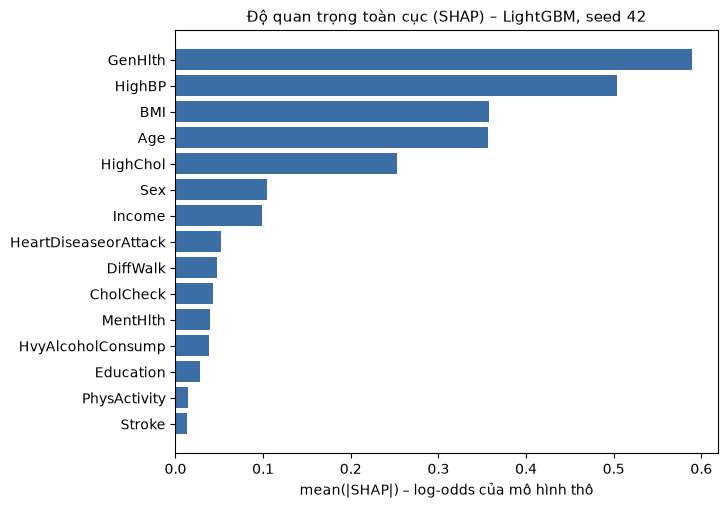

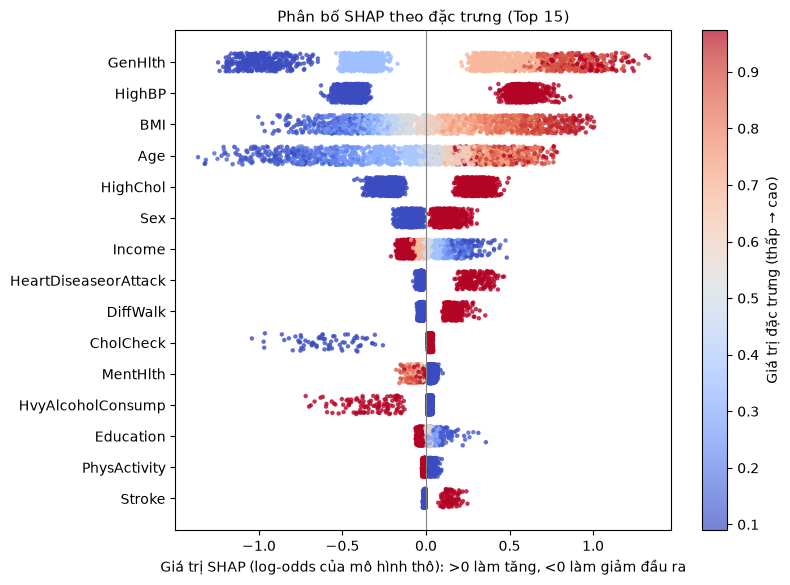

-> Đã lưu biểu đồ: D:\CK\results\figures\3_4_shap_by_group.png


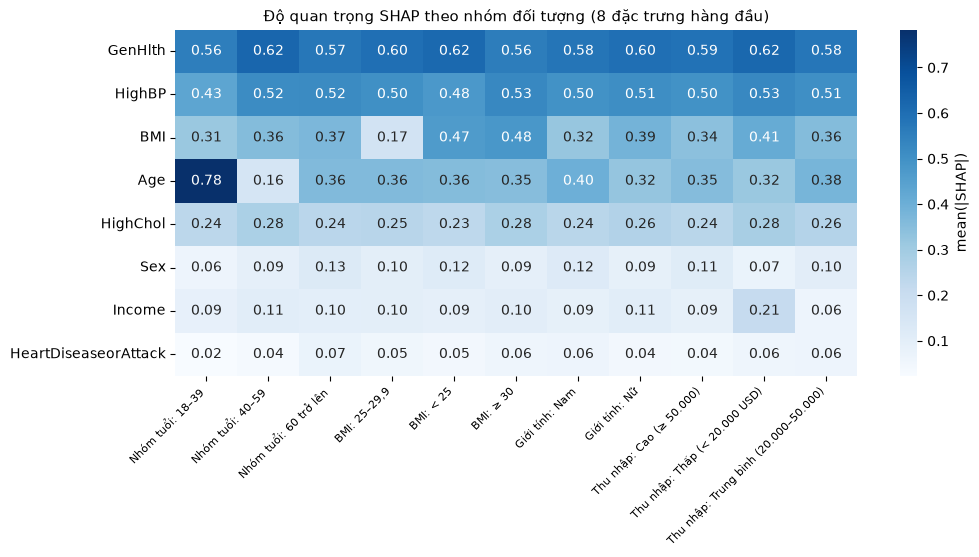

-> Đã lưu biểu đồ: D:\CK\results\figures\3_4_waterfall_cases.png


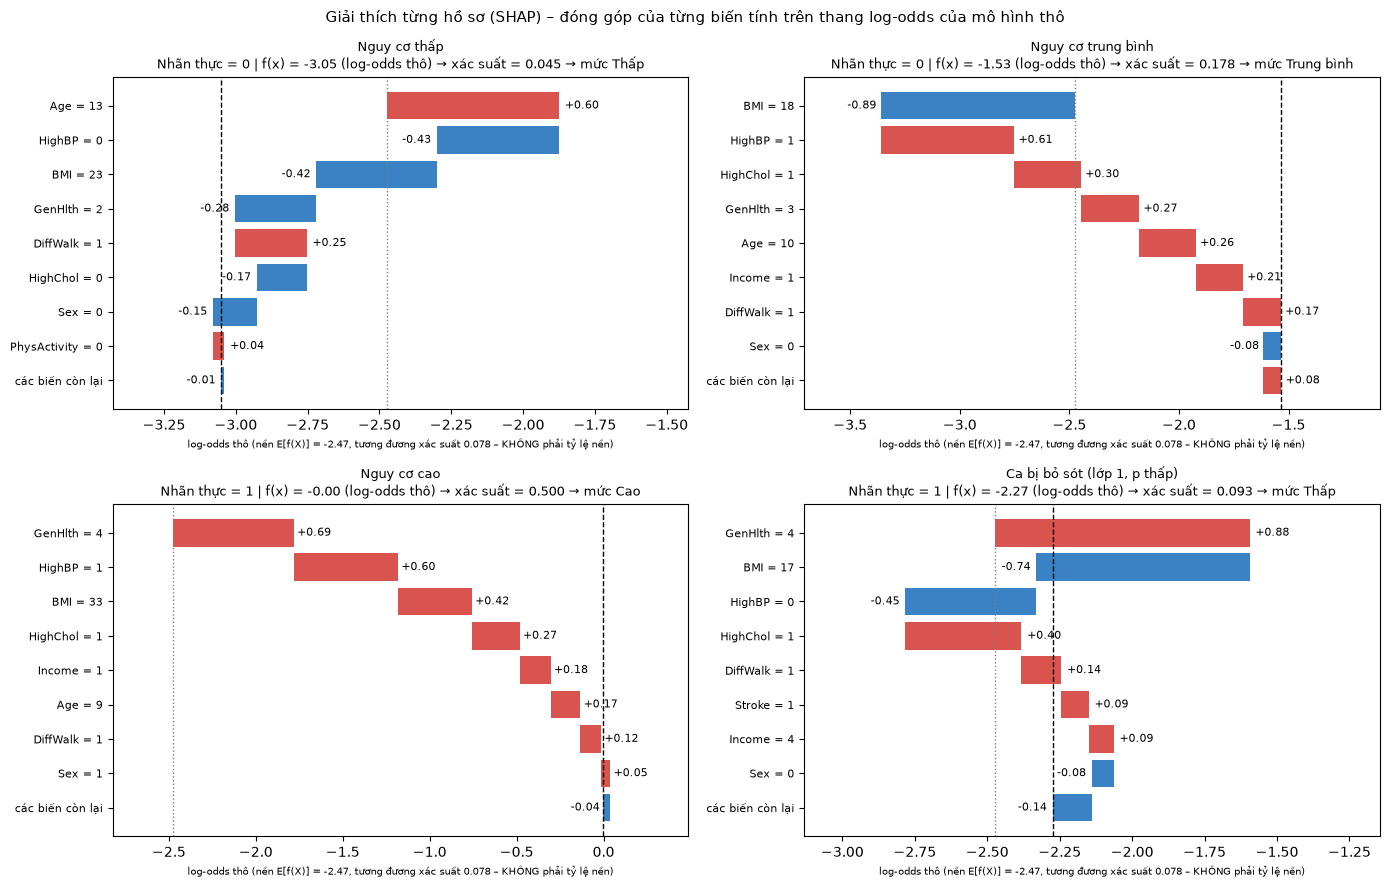

Độ ổn định giải thích giữa 5 mô hình (cùng mẫu): {'Spearman TB (các cặp seed)': 0.986, 'Spearman nhỏ nhất': 0.975, 'Trùng top-5 TB (/5)': 5.0}


In [9]:
SHAP = S3.shap_analysis(FINS, n_sample=2000)
display(SHAP["imp"].head(10))
S3.plot_shap_global(SHAP); plt.show()
S3.plot_shap_groups(SHAP); plt.show()
T_LOW, T_HIGH = S3.tier_schemes(FIN)[SCHEME]
CASES = S3.pick_cases(FIN, SHAP, T_LOW, T_HIGH)
S3.plot_waterfalls(SHAP, FIN, CASES, T_LOW, T_HIGH); plt.show()
print("Độ ổn định giải thích giữa 5 mô hình (cùng mẫu):", {k: round(v, 3) for k, v in SHAP["stability"].items()})

**Kiểm tra biến `HvyAlcoholConsump`.** Biến này có độ quan trọng khá cao nhưng quan hệ *nghịch* với nhãn. Bảng dưới cho thấy cả trong dữ liệu gốc và trong SHAP, người uống rượu nhiều có tỉ lệ nhãn dương thấp hơn. Đây là quan hệ thống kê trong dữ liệu khảo sát tự khai (có thể do người bệnh bỏ rượu, hiệu ứng "sick quitter", hoặc nhóm người trả lời khác biệt), **không** có nghĩa uống nhiều rượu có tác dụng phòng ngừa tiểu đường. Vì vậy: không quy tắc nào dùng biến này làm căn cứ lời khuyên và What-if không mô phỏng thay đổi biến này.

In [10]:
display(SHAP["alcohol"])

,HvyAlcoholConsump,Số hồ sơ (mẫu SHAP),SHAP trung bình (log-odds),Tỷ lệ lớp 1 trong toàn bộ dữ liệu (%)
0,0,1891,0.020975,14.415430
1,1,109,-0.337097,5.836139


## 3.5 Bộ quy tắc hỗ trợ quyết định (Decision Engine)

Bộ quy tắc nằm trong `rules/decision_rules.json`, **độc lập với mô hình học máy**: mỗi quy tắc có mã, điều kiện, mức ưu tiên, hành động, giải thích, nguồn tham khảo. Hai loại quy tắc được phân biệt rõ:
- `guideline`: dựa trên tài liệu chuyên môn (ADA Standards of Care 2026, USPSTF 2021, CDC National DPP);
- `operational`: do nhóm xây dựng từ kết quả thực nghiệm (phân mức, nhóm dễ bị bỏ sót).

SHAP hoặc tương quan thống kê **không** được dùng làm căn cứ duy nhất cho lời khuyên y tế. Mỗi quy tắc có thêm các trường `doc`, `section`, `rec_no` (số khuyến cáo) và `status` (trạng thái xác minh). Các trích dẫn mới được đối chiếu qua nguồn thứ cấp; `rec_no` để trống cho tới khi nhóm đối chiếu bản gốc.

**R05 và ranh giới 70 tuổi:** USPSTF áp dụng cho 35–70 tuổi, còn BRFSS chỉ có nhóm tuổi 5 năm (mã 10 = 65–69, mã 11 = 70–74). R05 dùng mã 4–10 nên không tính người đúng 70 tuổi (không tách được khỏi nhóm 70–74); người 70–74 vẫn nhận R04. Hệ thống không biết tuổi chính xác của từng người.
Mức *nguy cơ* (từ mô hình) và mức *ưu tiên hỗ trợ* (cao nhất trong các quy tắc được kích hoạt) là hai đại lượng khác nhau: một người mức nguy cơ Thấp nhưng từ 35 tuổi vẫn nhận nhắc tầm soát theo hướng dẫn.

In [11]:
RULES = S3.save_rules()
rules_df = pd.DataFrame([{"Mã": r["id"], "Loại": r["type"], "Ưu tiên": r["priority"], "Tên": r["name"], "Tài liệu / mục": (r.get("doc", "") + " – " + r.get("section", "")),
                          "Số khuyến cáo": r.get("rec_no") or "chưa điền", "Trạng thái xác minh": r.get("status", "")} for r in RULES["rules"]])
print("10 quy tắc chuyên môn (guideline):"); display(rules_df[rules_df["Loại"] == "guideline"])
print("6 quy tắc vận hành (operational):"); display(rules_df[rules_df["Loại"] == "operational"])
print("\n=== Kiểm tra tính nhất quán và mâu thuẫn của bộ quy tắc (dùng ngưỡng THẬT của hệ thống) ===")
rule_tests, rule_consistency, rule_summary = S3.run_rule_tests(RULES, {"t_low": T_LOW, "t_high": T_HIGH})
display(rule_consistency)
print(f"\n=== {len(rule_tests)} tình huống kiểm thử (file rules/test_cases.csv) ===")
display(rule_tests[["id", "mô tả", "p", "Mức kỳ vọng", "Mức engine", "Quy tắc kỳ vọng", "Quy tắc kích hoạt", "Đạt"]])
print(rule_summary)

-> Đã lưu bộ quy tắc (16 quy tắc): D:\CK\rules\decision_rules.json
10 quy tắc chuyên môn (guideline):


,Mã,Loại,Ưu tiên,Tên,Tài liệu / mục,Số khuyến cáo,Trạng thái xác minh
3,R04,guideline,2,Tầm soát định kỳ từ 35 tuổi,ADA Standards of Care 2026 – Mục 2 – Diagnosis...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
4,R05,guideline,2,Tầm soát người 35–70 tuổi thừa cân,USPSTF 2021 (JAMA 2021;326(8):736-743) – Recom...,B,Đã đối chiếu bản tóm tắt AAFP; chờ đối chiếu b...
5,R06,guideline,2,Thừa cân kèm yếu tố nguy cơ (mọi độ tuổi),ADA Standards of Care 2026 – Mục 2 – Diagnosis...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
6,R07,guideline,2,Quản lý cân nặng khi BMI ≥ 25,CDC National Diabetes Prevention Program – Chư...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
7,R08,guideline,2,Ít vận động,CDC National Diabetes Prevention Program – Chư...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
8,R09,guideline,1,Ăn ít rau/trái cây,ADA Standards of Care 2026 – Mục 5 – Facilitat...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
9,R10,guideline,2,Huyết áp cao,ADA Standards of Care 2026 – Mục 2 – Diagnosis...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
10,R11,guideline,1,Cholesterol cao,ADA Standards of Care 2026 – Mục 10 – Cardiova...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
11,R12,guideline,2,Có bệnh tim mạch,ADA Standards of Care 2026 – Mục 2 – Diagnosis...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...
12,R13,guideline,1,Tiền sử hút thuốc (lưu ý cách hiểu biến),ADA Standards of Care 2026 – Mục 5 – Facilitat...,chưa điền,Chưa đối chiếu bản gốc (mới qua nguồn thứ cấp)...


6 quy tắc vận hành (operational):


,Mã,Loại,Ưu tiên,Tên,Tài liệu / mục,Số khuyến cáo,Trạng thái xác minh
0,R01,operational,1,Mức nguy cơ thấp – luôn kèm lưu ý giới hạn,Nhóm xây dựng – Báo cáo Giai đoạn 2 mục 8–9; G...,chưa điền,"Không áp dụng – quy tắc vận hành của nhóm, kiể..."
1,R02,operational,2,Mức nguy cơ trung bình,Nhóm xây dựng – Báo cáo Giai đoạn 2 mục 8–9; G...,chưa điền,"Không áp dụng – quy tắc vận hành của nhóm, kiể..."
2,R03,operational,3,Mức nguy cơ cao,Nhóm xây dựng – Báo cáo Giai đoạn 2 mục 8–9; G...,chưa điền,"Không áp dụng – quy tắc vận hành của nhóm, kiể..."
13,R14,operational,2,Sức khỏe tự đánh giá yếu hoặc khó đi bộ,Nhóm xây dựng – Báo cáo Giai đoạn 2 mục 8–9; G...,chưa điền,"Không áp dụng – quy tắc vận hành của nhóm, kiể..."
14,R15,operational,1,Rào cản tiếp cận y tế,Nhóm xây dựng – Báo cáo Giai đoạn 2 mục 8–9; G...,chưa điền,"Không áp dụng – quy tắc vận hành của nhóm, kiể..."
15,R16,operational,2,Nhóm mô hình dễ bỏ sót,Nhóm xây dựng – Báo cáo Giai đoạn 2 mục 8–9; G...,chưa điền,"Không áp dụng – quy tắc vận hành của nhóm, kiể..."



=== Kiểm tra tính nhất quán và mâu thuẫn của bộ quy tắc (dùng ngưỡng THẬT của hệ thống) ===
-> Đã lưu bảng: D:\CK\results\tables\3_5_rule_tests.csv
-> Đã lưu bảng: D:\CK\results\tables\3_5_rule_consistency.csv


,Kiểm tra,Kết quả,Chi tiết
0,Mã quy tắc không trùng,ĐẠT,
1,Đủ trường bắt buộc,ĐẠT,
2,Quy tắc 'guideline' đều có nguồn tham khảo,ĐẠT,
3,Điều kiện chỉ dùng biến hợp lệ,ĐẠT,
4,"Quy tắc 'guideline' có tài liệu, mục và trạng ...",ĐẠT,
5,Có 10 quy tắc guideline và 6 quy tắc operational,ĐẠT,
6,Không quy tắc nào dùng HvyAlcoholConsump làm c...,ĐẠT,
7,Không có hai quy tắc trùng điều kiện,ĐẠT,[]
8,Đúng một quy tắc mức nguy cơ được kích hoạt vớ...,ĐẠT,
9,Mức thấp luôn kèm lưu ý giới hạn (R01),ĐẠT,



=== 23 tình huống kiểm thử (file rules/test_cases.csv) ===


,id,mô tả,p,Mức kỳ vọng,Mức engine,Quy tắc kỳ vọng,Quy tắc kích hoạt,Đạt
0,T01,"Người khỏe mạnh, xác suất rất thấp",0.030000,Thấp,Thấp,"R01,R16","R01,R16",True
1,T02,"Người khỏe mạnh, xác suất trong vùng trung bình",0.200000,Trung bình,Trung bình,R02,R02,True
2,T03,"Người khỏe mạnh, xác suất cao",0.400000,Cao,Cao,R03,R03,True
3,T04,"35–39 tuổi, mức thấp (kiểm tra tầm soát theo t...",0.050000,Thấp,Thấp,"R01,R04,R16","R01,R04,R16",True
4,T05,"Nhiều yếu tố: 45–49 tuổi, BMI 27, huyết áp cao...",0.300000,Cao,Cao,"R03,R04,R05,R06,R07,R10,R11","R03,R04,R05,R06,R07,R10,R11",True
5,T06,"Nhiều yếu tố: 60–64 tuổi, BMI 33, ít vận động,...",0.550000,Cao,Cao,"R03,R04,R05,R06,R07,R08,R09,R10,R11,R13","R03,R04,R05,R06,R07,R08,R09,R10,R11,R13",True
6,T07,"75–79 tuổi, BMI 24, có bệnh tim, mức thấp",0.100000,Thấp,Thấp,"R01,R04,R12,R16","R01,R04,R12,R16",True
7,T08,"Hồ sơ dễ bị bỏ sót: trẻ, BMI 22, không huyết á...",0.055000,Thấp,Thấp,"R01,R16","R01,R16",True
8,T09,Sát dưới ngưỡng thấp/trung bình (p = t_low − 0...,0.135443,Thấp,Thấp,"R01,R04,R05,R07","R01,R04,R05,R07",True
9,T10,Đúng ngưỡng thấp/trung bình (p = t_low),0.135543,Trung bình,Trung bình,"R02,R04,R05,R07","R02,R04,R05,R07",True


{'Số tình huống': 23, 'Tỷ lệ tình huống đạt (mức + quy tắc kích hoạt đúng)': 1.0, 'Tỷ lệ nhất quán mô hình–mức cảnh báo–quy tắc': 1.0, 'Số kiểm tra tính nhất quán bộ quy tắc đạt': '11/11', 'Thời gian quyết định trung bình (ms/hồ sơ, chưa gồm mô hình)': 1.324565220705193}


## 3.6 What-if có ràng buộc và so sánh tình huống

Chỉ cho phép thay đổi: **BMI** (chỉ giảm, trong khoảng 15–60), **PhysActivity**, **Fruits**, **Veggies** (chỉ 0 → 1). Không cho phép đổi tuổi, giới, đột quỵ, bệnh tim, huyết áp, cholesterol… và **không đổi `Smoker` từ 1 sang 0** (biến này là "đã từng hút ≥ 100 điếu", không phải tình trạng hiện tại). Mỗi mô phỏng kiểm tra tính hợp lý (BMI thiếu cân, giảm > 10%, và số hồ sơ huấn luyện tương tự – tổ hợp hiếm bị cảnh báo) và giải thích nguyên nhân bằng *thay đổi SHAP* giữa hai hồ sơ.
**What-if chỉ mô phỏng phản ứng của mô hình, không chứng minh một hành động sẽ làm giảm nguy cơ mắc bệnh theo mức thay đổi của xác suất.** Đường cong giảm BMI cho thấy xác suất có thể thay đổi theo bước (hiệu ứng ngưỡng của cây quyết định).

-> Đã lưu hệ thống: D:\CK\models\Phase3_system.joblib
-> Đã lưu bảng: D:\CK\results\tables\3_6_whatif_scenarios.csv
-> Đã lưu bảng: D:\CK\results\tables\3_6_whatif_bmi_curve.csv


,Kịch bản,Số hồ sơ,Xác suất TB,Δp tuyệt đối TB,Δp tương đối TB (%),% còn mức Cao,% xuống Trung bình,% xuống Thấp
0,PA0: Hiện tại,3498,0.389,0.000,0.000,100.000,0.000,0.000
1,PA1: Lối sống (vận động + rau + trái cây),3498,0.380,-0.009,-2.717,95.540,4.460,0.000
2,PA2: Giảm 5% BMI,3498,0.366,-0.023,-6.452,91.081,8.919,0.000
3,PA3: Giảm 7% BMI (mục tiêu DPP),3498,0.356,-0.032,-9.194,87.136,12.864,0.000
4,PA4: Giảm 10% BMI,3498,0.338,-0.051,-14.364,81.132,18.811,0.057
5,PA5: Giảm 7% BMI + lối sống,3498,0.346,-0.043,-12.186,82.762,17.124,0.114


-> Đã lưu biểu đồ: D:\CK\results\figures\3_6_whatif.png


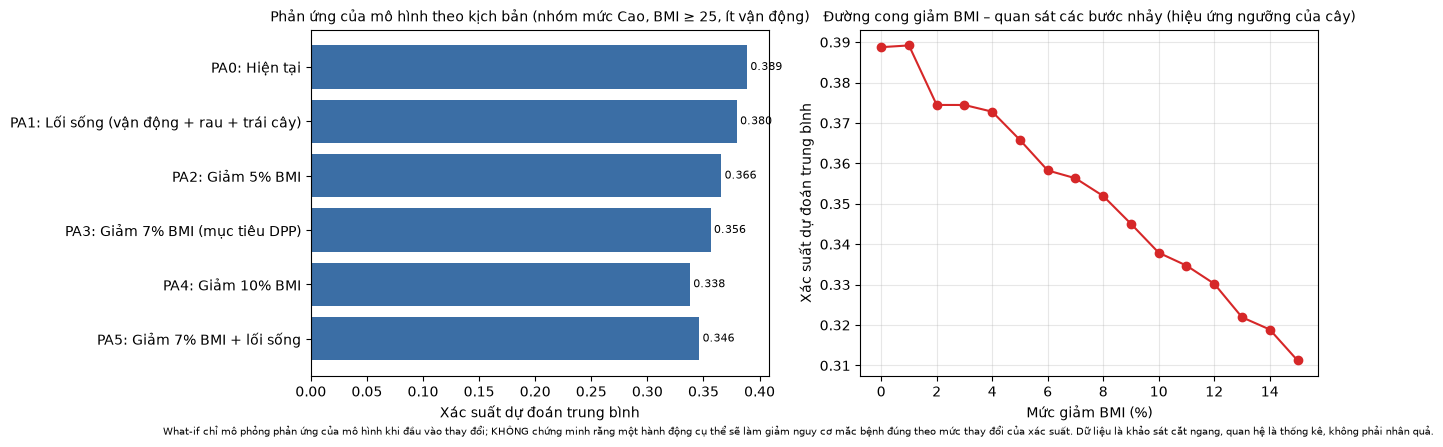

Trước: p = 0.251 (mức Cao, ưu tiên: Ưu tiên cao)
Sau  : p = 0.193 (mức Trung bình, ưu tiên: Cần lưu ý)   Δp = -0.058


,Đặc trưng,Trước,Sau,Thay đổi SHAP (log-odds thô)
0,BMI,34,31.6,-0.175105
1,PhysActivity,0,1.0,-0.058512
2,HighChol,1,1.0,-0.047260
3,GenHlth,2,2.0,-0.027158
4,Age,8,8.0,-0.016826


Cảnh báo: không
What-if chỉ mô phỏng phản ứng của mô hình khi đầu vào thay đổi; KHÔNG chứng minh rằng một hành động cụ thể sẽ làm giảm nguy cơ mắc bệnh đúng theo mức thay đổi của xác suất. Dữ liệu là khảo sát cắt ngang, quan hệ là thống kê, không phải nhân quả.

Kiểm tra ràng buộc – các thay đổi sau PHẢI bị từ chối:
  đã chặn {'Smoker': 0} → Không được thay đổi 'Smoker': biến này là 'đã từng hút ≥100 điếu', không phải tình trạng h
  đã chặn {'Age': 5} → Không được thay đổi 'Age': tuổi không thể can thiệp
  đã chặn {'Stroke': 0} → Không được thay đổi 'Stroke': tiền sử đột quỵ không thể thay đổi
  đã chặn {'HvyAlcoholConsump': 0} → Không được thay đổi 'HvyAlcoholConsump': không mô phỏng thay đổi theo hướng này vì quan hệ
  đã chặn {'BMI': 40} → What-if chỉ cho phép giảm BMI
  đã chặn {'BMI': 10} → BMI sau can thiệp phải nằm trong khoảng 15–60


In [12]:
SYSTEM = S3.build_system(FIN, SCHEME, CAL_WHY, CFG2)
sc_tab, sc_curve, GROUP = S3.whatif_scenarios(FIN, SYSTEM, T_LOW, T_HIGH)
display(sc_tab.round(3))
S3.plot_whatif(sc_tab, sc_curve); plt.show()

# Ví dụ một hồ sơ: trước/sau, nguyên nhân thay đổi, quy tắc, kiểm tra ràng buộc
profile = S3._neutral(); profile.update(Age=8, BMI=34, HighBP=1, HighChol=1, PhysActivity=0, Smoker=1, Fruits=0, Sex=1)
res = S3.what_if(SYSTEM, profile, {"BMI": 31.6, "PhysActivity": 1, "Fruits": 1}, RULES)
print(f"Trước: p = {res['before']['p']:.3f} (mức {res['before']['tier_name']}, ưu tiên: {res['before']['priority_name']})")
print(f"Sau  : p = {res['after']['p']:.3f} (mức {res['after']['tier_name']}, ưu tiên: {res['after']['priority_name']})   Δp = {res['delta_p']:+.3f}")
display(res["why"]); print("Cảnh báo:", res["flags"] or "không"); print(res["disclaimer"])
print("\nKiểm tra ràng buộc – các thay đổi sau PHẢI bị từ chối:")
for bad in [{"Smoker": 0}, {"Age": 5}, {"Stroke": 0}, {"HvyAlcoholConsump": 0}, {"BMI": 40}, {"BMI": 10}]:
    try:
        S3.what_if(SYSTEM, profile, bad, RULES); print("  KHÔNG bị chặn:", bad)
    except ValueError as e:
        print("  đã chặn", bad, "→", str(e)[:90])

## 3.7 Thí nghiệm so sánh cấu hình A, B, C, D

- **A:** LightGBM với ngưỡng mặc định 0,5.
- **B:** LightGBM + ngưỡng chọn trên validation (Recall ≥ 80%, F1 lớn nhất).
- **C:** LightGBM + quyết định theo chi phí giả định (5:1, 10:1) hoặc theo năng lực xử lý (Top 200/300 trên 1.000).
- **D:** hệ thống tích hợp (mô hình + quy tắc + SHAP + What-if). Không kỳ vọng D làm tăng PR-AUC; D được đánh giá riêng bằng chất lượng hỗ trợ quyết định: tỉ lệ quy tắc kích hoạt đúng, tính nhất quán, phát hiện mâu thuẫn, thời gian phản hồi, và mức độ nhắc tầm soát cho ca bị bỏ sót (kèm chi phí vận hành của nhắc nhở).
Chi phí tính theo giả định FN:FP = 5:1 và 10:1 (đã công bố), trên 1.000 người.

In [13]:
abc_detail, abc_summary = S3.compare_configs(FINS, RULES)
display(abc_summary)
print("\n=== Cấu hình D: chất lượng hỗ trợ quyết định (test, seed 42) ===")
D_TAB = S3.system_quality(FIN, SYSTEM, RULES, rule_summary)
display(D_TAB)

-> Đã lưu bảng: D:\CK\results\tables\3_7_configs_ABC.csv


,Cấu hình,Phương án,Số seed,Recall,Precision,FN / 1.000,FP / 1.000,Hồ sơ xử lý / 1.000,Chi phí / 1.000 (FN:FP=5:1),Chi phí / 1.000 (FN:FP=10:1)
0,A,"Ngưỡng mặc định 0,5",5,0.144 ± 0.004 [0.138; 0.149],0.595 ± 0.009 [0.584; 0.606],119.391 ± 0.630 [118.609; 120.173],13.621 ± 0.266 [13.291; 13.951],33.658 ± 0.679 [32.814; 34.501],610.577 ± 3.158 [606.655; 614.498],1207.532 ± 6.301 [1199.709; 1215.356]
1,B,Ngưỡng chọn trên validation: Recall ≥ 80%,5,0.800 ± 0.010 [0.788; 0.812],0.306 ± 0.002 [0.303; 0.309],27.866 ± 1.357 [26.181; 29.552],253.198 ± 4.818 [247.215; 259.181],364.760 ± 6.176 [357.091; 372.428],392.529 ± 4.325 [387.159; 397.899],531.860 ± 10.311 [519.058; 544.663]
2,B,Ngưỡng chọn trên validation: F1 lớn nhất,5,0.605 ± 0.022 [0.577; 0.632],0.389 ± 0.012 [0.374; 0.405],55.129 ± 3.162 [51.203; 59.056],132.694 ± 11.593 [118.299; 147.089],216.993 ± 14.535 [198.945; 235.041],408.340 ± 5.074 [402.040; 414.640],683.986 ± 20.422 [658.628; 709.343]
3,C,Theo chi phí giả định 5:1,5,0.754 ± 0.027 [0.721; 0.788],0.325 ± 0.011 [0.311; 0.339],34.260 ± 3.748 [29.606; 38.914],219.125 ± 19.077 [195.438; 242.812],324.293 ± 22.910 [295.847; 352.740],390.425 ± 3.743 [385.778; 395.072],561.725 ± 19.142 [537.957; 585.493]
4,C,Theo chi phí giả định 10:1,5,0.889 ± 0.005 [0.882; 0.895],0.262 ± 0.004 [0.258; 0.267],15.534 ± 0.722 [14.638; 16.431],348.775 ± 8.610 [338.084; 359.465],472.668 ± 9.462 [460.920; 484.417],426.446 ± 6.293 [418.632; 434.260],504.118 ± 5.580 [497.190; 511.045]
5,C,Theo năng lực: Top 200/1.000,5,0.576 ± 0.003 [0.573; 0.579],0.402 ± 0.002 [0.399; 0.404],59.091 ± 0.424 [58.564; 59.617],119.664 ± 0.375 [119.198; 120.129],200.001 ± 0.009 [199.990; 200.012],415.117 ± 2.368 [412.178; 418.057],710.571 ± 4.479 [705.010; 716.133]
6,C,Theo năng lực: Top 300/1.000,5,0.727 ± 0.004 [0.722; 0.732],0.338 ± 0.002 [0.335; 0.340],38.123 ± 0.574 [37.410; 38.835],198.696 ± 0.581 [197.975; 199.418],300.002 ± 0.005 [299.995; 300.008],389.310 ± 3.361 [385.137; 393.484],579.924 ± 6.223 [572.197; 587.651]



=== Cấu hình D: chất lượng hỗ trợ quyết định (test, seed 42) ===
-> Đã lưu bảng: D:\CK\results\tables\3_7_system_quality_D.csv


,"Chỉ tiêu (cấu hình D, test seed 42)",Kết quả
0,Số tình huống kiểm thử quy tắc,23
1,Tỷ lệ tình huống kích hoạt đúng quy tắc và mức,100.0%
2,Tỷ lệ nhất quán mô hình – mức cảnh báo – quy tắc,100.0%
3,Kiểm tra mâu thuẫn bộ quy tắc (đạt),11/11
4,Hồ sơ mức thấp luôn có lưu ý giới hạn (R01),100.0%
5,"Ca bị bỏ sót (mức thấp, nhãn 1) được nhắc tầm ...",96.6% (1028/1064)
6,Hồ sơ mức thấp nhận nhắc tầm soát (chi phí vận...,87.1%
7,Hồ sơ mức thấp thuộc nhóm dễ bỏ sót (R16),31.9%
8,Thời gian phản hồi trung bình cho một hồ sơ (g...,12.1 ms


## 3.9 Kiểm thử xuyên suốt (hồ sơ → LightGBM → mức nguy cơ → quy tắc → SHAP → file xuất)

Bộ kiểm thử `tests/test_end_to_end.py` **đọc ngưỡng thật từ `models/Phase3_system.joblib`** (không gõ tay 0,134/0,238), chạy các tình huống sát ngưỡng, nhiều quy tắc cùng kích hoạt, hồ sơ dễ bị bỏ sót, dữ liệu không hợp lệ, các thay đổi What-if bị cấm, và so khớp kết quả hiển thị với CSV/Excel/HTML.

In [14]:
import subprocess, sys
out = subprocess.run([sys.executable, "tests/test_end_to_end.py"], capture_output=True, text=True, encoding="utf-8")
print(out.stdout[-4000:]); print(out.stderr[-1500:] if out.returncode else "")
display(pd.read_csv(U.TABLES / "5_e2e_test_results.csv"))

-> Đã lưu bảng: D:\CK\results\tables\3_5_rule_tests.csv
-> Đã lưu bảng: D:\CK\results\tables\3_5_rule_consistency.csv
[PASS] Ngưỡng đọc từ file hệ thống, hợp lệ (0 < t_low < t_high < 1)
        t_low=0.1355, t_high=0.2194, sơ đồ=A (Recall ≥ 80% → F1 lớn nhất)
[PASS] Hệ thống có đủ 21 biến, mô hình LightGBM, hiệu chuẩn đã chọn
        hiệu chuẩn = none
[PASS] Pipeline: p khớp mô hình+hiệu chuẩn, mức khớp ngưỡng thật, quy tắc khớp engine, SHAP cộng đúng
        6 hồ sơ
[PASS] Quy tắc không bao giờ dựa vào HvyAlcoholConsump (hồ sơ uống rượu nhiều và không uống cho cùng bộ quy tắc)
[PASS] Sát ngưỡng: t_low−ε → Thấp, t_low → Trung bình, t_high−ε → Trung bình, t_high → Cao
[PASS] 23 tình huống quy tắc (có sát ngưỡng thật, nhiều quy tắc, hồ sơ dễ bị bỏ sót, ranh giới R05) đều đạt
        23 tình huống; 11/11 kiểm tra nhất quán
[PASS] Bộ quy tắc: đúng 16 quy tắc = 10 guideline + 6 operational; guideline có tài liệu, mục, trạng thái xác minh
[PASS] Dữ liệu sai bị chặn: thiếu cột, không phải số,

,Kiểm thử,Kết quả,Chi tiết
0,"Ngưỡng đọc từ file hệ thống, hợp lệ (0 < t_low...",ĐẠT,"t_low=0.1355, t_high=0.2194, sơ đồ=A (Recall ≥..."
1,"Hệ thống có đủ 21 biến, mô hình LightGBM, hiệu...",ĐẠT,hiệu chuẩn = none
2,"Pipeline: p khớp mô hình+hiệu chuẩn, mức khớp ...",ĐẠT,6 hồ sơ
3,Quy tắc không bao giờ dựa vào HvyAlcoholConsum...,ĐẠT,NaN
4,"Sát ngưỡng: t_low−ε → Thấp, t_low → Trung bình...",ĐẠT,NaN
5,"23 tình huống quy tắc (có sát ngưỡng thật, nhi...",ĐẠT,23 tình huống; 11/11 kiểm tra nhất quán
6,Bộ quy tắc: đúng 16 quy tắc = 10 guideline + 6...,ĐẠT,NaN
7,"Dữ liệu sai bị chặn: thiếu cột, không phải số,...",ĐẠT,NaN
8,What-if cấm: đổi Age/Sex/Stroke/HeartDisease/H...,ĐẠT,13 thay đổi bị chặn
9,"What-if hợp lệ: BMI giảm, bắt đầu vận động/ăn ...",ĐẠT,Δp = -0.0362


## 3.10 Decision Curve Analysis (tùy chọn)

Lợi ích ròng `NB(pt) = TP/n − FP/n · pt/(1−pt)` so sánh LightGBM với hai chiến lược mặc định: cảnh báo tất cả và không cảnh báo ai, trên tập test (trung bình 5 seed). `pt` thể hiện mức đánh đổi: ở `pt = 0,2` người ra quyết định coi một ca bỏ sót nặng gấp 4 lần một cảnh báo sai. **Giả định:** nhãn là tự khai, tỉ lệ dương 13,9%, các giá trị `pt` là giả định; kết quả **không** phải bằng chứng hiệu quả lâm sàng.

-> Đã lưu bảng: D:\CK\results\tables\3_9_decision_curve.csv
-> Đã lưu biểu đồ: D:\CK\results\figures\3_9_decision_curve.png


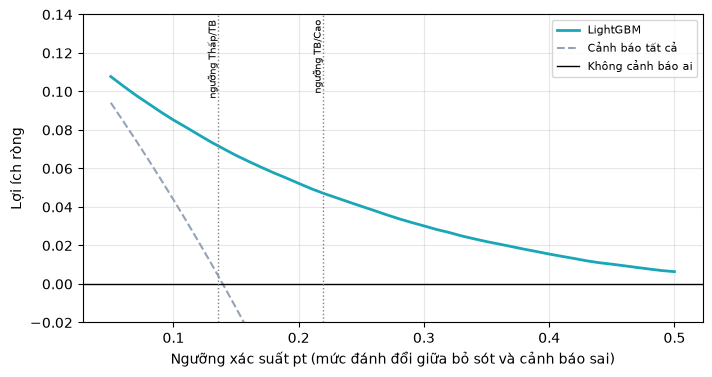

,Ngưỡng pt,Mô hình (LightGBM),Cảnh báo tất cả,Không cảnh báo ai
0,0.05,0.1078,0.0941,0.0
5,0.10,0.0852,0.0438,0.0
10,0.15,0.0668,-0.0124,0.0
15,0.20,0.0523,-0.0757,0.0
25,0.30,0.0302,-0.2294,0.0
35,0.40,0.0156,-0.4343,0.0


In [15]:
DCA = S3.decision_curve(FINS)
S3.plot_decision_curve(DCA, T_LOW, T_HIGH); plt.show()
display(DCA[DCA["Ngưỡng pt"].isin([0.05, 0.10, 0.15, 0.20, 0.30, 0.40])].round(4))

## 3.11 Tổng kết Giai đoạn 3

**Đã thực hiện (có kết quả thực nghiệm):** chốt cấu hình hiệu chuẩn bằng validation; bảng điểm vận hành và phân mức 3 tầng; so sánh Top-k với ngưỡng cố định; phân tích bỏ sót theo nhóm có khoảng tin cậy; SHAP toàn cục, từng hồ sơ, theo nhóm và độ ổn định; bộ 16 quy tắc (10 chuyên môn + 6 vận hành) có nguồn, tài liệu/mục và trạng thái xác minh, kèm 23 tình huống kiểm thử; kiểm thử xuyên suốt (mục 3.9); Decision Curve Analysis (mục 3.10); What-if có ràng buộc; so sánh cấu hình A–D.

**Còn ở mức thiết kế / giới hạn:**
- Các giới hạn năng lực xử lý và tỉ lệ chi phí là kịch bản giả định, chưa được xác minh với nhu cầu sàng lọc thực tế.
- Kiểm thử quy tắc chỉ chứng minh *engine làm đúng định nghĩa quy tắc*, không chứng minh khuyến nghị có hiệu quả lâm sàng.
- Nguồn y khoa cần được đối chiếu số khuyến cáo trong bản gốc; chưa có chuyên gia y tế đánh giá.
- DCA (mục 3.10) chỉ là phân tích giả định trên dữ liệu khảo sát; không phải bằng chứng hiệu quả lâm sàng. Không chạy EBM theo hướng dẫn của cô.
- Chưa thử nghiệm với người dùng thật (3–5 người) – cần thực hiện và ghi lại.
- Số khuyến cáo (`rec_no`) trong bản gốc ADA/USPSTF/CDC chưa được điền.
- Giao diện Streamlit (`app.py`) đã có đủ 8 chức năng, cần chạy thử trên máy: `streamlit run app.py`.

**Câu hỏi nghiên cứu cho bài báo:** việc tích hợp xác suất dự đoán, cơ chế phân bổ nguồn lực (Top-k), giải thích mô hình và quy tắc quyết định có cải thiện chất lượng quyết định trong các kịch bản sàng lọc giả định hay không? Kết quả hiện có (mục 3.2, 3.7) là bằng chứng cho phần *phân bổ nguồn lực* và *khả năng nhắc tầm soát*; phần còn lại mới ở mức thiết kế.